# MV_Panels_Analysis

Analisi dei tre rivelatori su ch16, ch17 e ch18, con trigger esterno (CFD V812, maggioranza 2) a 750 MS/s.
I file `test_52-0V_0158` ... `0162` sono pezzi di una stessa presa dati e si
leggono come un'unica run: gli eventi si concatenano nell'ordine dei file.
Le celle di lettura, waveform e filtro vengono da `SiPM_Characterization_Gain_Study`.

In [1]:
## === Import principali ===
import os
import re
import contextlib, gzip, shutil, tempfile

import numpy as np
import matplotlib.pyplot as plt
import h5py
from scipy.optimize import curve_fit


# ============================================================
# LETTURA DEI FILE DELLA DAQ  (da WCFastCheck)
#
# I file hanno due formati: v1 un dataset per evento (event0, event1, ...),
# v2 un unico dataset /events/waveforms -- nato per poter leggere mentre la
# run e' in corso, che con un dataset per evento non si puo' fare. E i canali
# registrati NON sono sempre 32: si prendono dal file, non si assumono.
# ============================================================

@contextlib.contextmanager
def apri_run(path):
    """Apre un file della DAQ, compresso o no. A run finita diventa .h5.gz."""
    tmp = None
    if path.endswith(".gz"):
        tmp = tempfile.NamedTemporaryFile(suffix=".h5", delete=False).name
        with gzip.open(path, "rb") as fin, open(tmp, "wb") as fout:
            shutil.copyfileobj(fin, fout)
        path = tmp
    f = h5py.File(path, "r")
    try:
        yield f
    finally:
        f.close()
        if tmp:
            os.unlink(tmp)


def eventi_di(f):
    """(chiavi degli eventi, funzione che ne legge uno) per i due formati."""
    g = f["/events"]
    if "waveforms" in g:
        ds = g["waveforms"]
        return list(range(ds.shape[0])), lambda k: np.asarray(ds[k], dtype=np.float64)
    chiavi = sorted(g.keys(), key=lambda x: int(x.replace("event", "")))
    return chiavi, lambda k: np.asarray(g[k][:], dtype=np.float64)


def canali_di(f, voluti):
    """(canali nel file, indici di quelli chiesti).

    I canali si chiedono per NUMERO -- 16 e' il canale 16 del V1742 -- e non
    per posizione nella matrice: la posizione dipende da quali canali sono
    stati registrati in quella run, e cambia da una run all'altra.
    """
    lista = [int(c) for c in f["/config"].attrs["ChannelList"]]
    manca = [c for c in voluti if c not in lista]
    if manca:
        raise ValueError("Canali non nel file: %s. Il file contiene %s." % (manca, lista))
    return lista, [lista.index(c) for c in voluti]


def leggi_canale(path, canale, max_eventi=None):
    """Matrice (eventi, campioni) di un canale, in ADC int16, e SamplingTime [ns].

    Nel formato v2 il dataset si legge in un colpo solo: con eventi_di, un
    evento alla volta, mezzo milione di eventi richiedono minuti invece di
    secondi. Il v1 non lo permette e passa da eventi_di.
    """
    with apri_run(path) as f:
        sampling_time_ns = float(f["/config"].attrs["SamplingTime"]) * 1e9
        canali_file, (i_ch,) = canali_di(f, [canale])
        g = f["/events"]
        if "waveforms" in g:
            ds = g["waveforms"]
            n = ds.shape[0] if max_eventi is None else min(max_eventi, ds.shape[0])
            dati = ds[:n]
        else:
            chiavi, leggi = eventi_di(f)
            chiavi = chiavi[:max_eventi] if max_eventi is not None else chiavi
            dati = np.stack([leggi(k) for k in chiavi]).astype(np.int16)
    n_campioni = dati.shape[1] // len(canali_file)
    wf = dati.reshape(dati.shape[0], len(canali_file), n_campioni)[:, i_ch, :]
    return np.ascontiguousarray(wf), sampling_time_ns


def leggi_canali(path, canali, max_eventi=None):
    """{canale: matrice (eventi, campioni) in ADC int16}, SamplingTime [ns], attributi di /config.

    Come leggi_canale, ma con un'apertura sola per tutti i canali: un .h5.gz
    da 600 MB si decomprime in decine di secondi, e farlo una volta per canale
    triplicherebbe il tempo. Gli attributi servono a verificare che i file da
    unire siano stati presi con la stessa configurazione.
    """
    with apri_run(path) as f:
        attrs = dict(f["/config"].attrs)
        sampling_time_ns = float(attrs["SamplingTime"]) * 1e9
        canali_file, indici = canali_di(f, canali)
        g = f["/events"]
        if "waveforms" in g:
            ds = g["waveforms"]
            n = ds.shape[0] if max_eventi is None else min(max_eventi, ds.shape[0])
            dati = ds[:n]
        else:
            chiavi, leggi = eventi_di(f)
            chiavi = chiavi[:max_eventi] if max_eventi is not None else chiavi
            dati = np.stack([leggi(k) for k in chiavi]).astype(np.int16)
    n_campioni = dati.shape[1] // len(canali_file)
    dati = dati.reshape(dati.shape[0], len(canali_file), n_campioni)
    wf = {ch: np.ascontiguousarray(dati[:, i, :]) for ch, i in zip(canali, indici)}
    return wf, sampling_time_ns, attrs

In [88]:
# ============================================================
# CONFIG
# ============================================================

# Il notebook sta in tools/, i dati in data/ alla radice del repo
DATA_DIR = os.path.abspath(os.path.join("..", "data"))

# Pezzi di UNA stessa presa dati: si concatenano in quest'ordine in un'unica
# run. L'ordine conta solo per ritrovare un evento nel suo file d'origine
# (FILE_EVENTO, EVENTO_NEL_FILE).
# Pannello di cui si misura l'efficienza. Un run misura l'efficienza di UN
# pannello: il trigger esterno e' un CFD sugli altri due, quindi ogni pannello
# ha i suoi run. Si sceglie qui, si esegue il notebook fino alla cella che salva
# il risultato (measurements/mv_panels_eff_<pannello>.json) e si ripete per gli
# altri pannelli; la cella di confronto con Yale legge i JSON dei pannelli che ci sono.
PANNELLO = "Charles"           # "Alice" | "Charles" | "Bob"

# Pezzi di UNA stessa presa dati: si concatenano in quest'ordine in un'unica
# run. L'ordine conta solo per ritrovare un evento nel suo file d'origine
# (FILE_EVENTO, EVENTO_NEL_FILE).
# Dal .log di ogni run (non dal codice): i run 0057-0066 hanno il CFD V812 su 3
# ingressi (ch0, ch1, ch2) con maggioranza 2, cioe' registrano anche gli eventi
# in cui scattano due pannelli qualsiasi; i run 0168-0172 lo hanno su 2 ingressi
# (ch1, ch2) con maggioranza 2, cioe' la coincidenza di due pannelli.
RUN_FILES_PANNELLO = {
    "Alice": [
        "test_52-0V_0057_750Ms_70PT.h5.gz",
        "test_52-0V_0058_750Ms_70PT.h5.gz",
        "test_52-0V_0059_750Ms_70PT.h5.gz",
        "test_52-0V_0060_750Ms_70PT.h5.gz",
        "test_52-0V_0061_750Ms_70PT.h5.gz",
        # "test_52-0V_0062_750Ms_70PT.h5.gz",
        # "test_52-0V_0063_750Ms_70PT.h5.gz",
        # "test_52-0V_0064_750Ms_70PT.h5.gz",
        # "test_52-0V_0065_750Ms_70PT.h5.gz",
        # "test_52-0V_0066_750Ms_70PT.h5.gz",
    ],
    "Charles": [
        "test_52-0V_0168_750Ms_70PT.h5.gz",
        "test_52-0V_0169_750Ms_70PT.h5.gz",
        "test_52-0V_0170_750Ms_70PT.h5.gz",
        "test_52-0V_0171_750Ms_70PT.h5.gz",
        "test_52-0V_0172_750Ms_70PT.h5.gz",   # in acquisizione il 2026-10-15
        # "test_52-0V_0190_1Gs_60PT.h5.gz",
        # "test_52-0V_0191_1Gs_60PT.h5.gz",
        # "test_52-0V_0192_1Gs_60PT.h5.gz",
        # "test_52-0V_0193_1Gs_60PT.h5.gz",
        # "test_52-0V_0194_1Gs_60PT.h5.gz",
    ],
    "Bob": [
        "test_52-0V_0173_750Ms_70PT.h5.gz",
        "test_52-0V_0174_750Ms_70PT.h5.gz",
        "test_52-0V_0176_750Ms_70PT.h5.gz",
        "test_52-0V_0177_750Ms_70PT.h5.gz",
        "test_52-0V_0178_750Ms_70PT.h5.gz", 

    ],
}
if PANNELLO not in RUN_FILES_PANNELLO:
    raise ValueError(f"PANNELLO = {PANNELLO!r}: scegliere fra {list(RUN_FILES_PANNELLO)}")
RUN_FILES = RUN_FILES_PANNELLO[PANNELLO]
if not RUN_FILES:
    raise ValueError(f"Nessun file per {PANNELLO}: aggiungerli a RUN_FILES_PANNELLO[{PANNELLO!r}]")
print(f"Pannello sotto esame: {PANNELLO}, {len(RUN_FILES)} file")

# Canale V1742 -> rivelatore collegato. I canali si chiedono per NUMERO, non
# per posizione nel file. Il nome compare in titoli e stampe.
RIVELATORI = {
    16: "Charles",
    17: "Alice",
    18: "Bob",
}
CANALI = list(RIVELATORI)

MAX_EVENTI_PER_FILE = None   # None = tutti; un numero per prove veloci

# Dove si scrivono i risultati per pannello e da dove li legge il confronto
DIR_MISURE = os.path.abspath(os.path.join("..", "measurements"))


def tensione_da_nome(nome):
    """(etichetta come nel nome, tensione [V]): '52-0V' -> ('52-0V', 52.0).

    Nel nome il punto decimale e' scritto '-', perche' un punto confonderebbe
    l'estensione. La tensione ce la scrive il controllore leggendola
    dall'alimentatore: chi avvia la DAQ senza passare da li' lascia
    l'etichetta della run precedente, e il nome mente.
    """
    m = re.search(r"_(\d+(?:-\d+)?)V_", nome)
    if m is None:
        raise ValueError(f"{nome}: tensione non trovata nel nome (atteso es. _52-0V_)")
    return m.group(1) + "V", float(m.group(1).replace("-", "."))


# Un'unica run vuol dire un'unica tensione: file a tensioni diverse uniti
# insieme mescolerebbero guadagni diversi senza che nulla lo mostri.
tensioni = {nome: tensione_da_nome(nome) for nome in RUN_FILES}
if len({v for _, v in tensioni.values()}) != 1:
    raise ValueError(f"I file non hanno tutti la stessa tensione: {tensioni}")
VBIAS_LABEL, VBIAS = next(iter(tensioni.values()))     # "52-0V", 52.0 [V]

DESCRIZIONE = {ch: f"ch{ch} ({RIVELATORI[ch]}), {VBIAS:g} V" for ch in CANALI}


# ============================================================
# LETTURA E UNIONE
# ============================================================

# Attributi che devono coincidere fra i pezzi: con uno solo diverso non sono
# la stessa run, e concatenarli darebbe una distribuzione che non esiste.
# ChannelList NON c'e': i canali si chiedono per numero (leggi_canali), quindi
# che un file ne abbia registrati altri (es. 19 e 20 nei run di Bob 0176-0178)
# non cambia i dati dei canali che servono. Se ne manca uno fra quelli chiesti,
# leggi_canali da' errore da se'.
DEVONO_COINCIDERE = ["SamplingTime", "SamplesPerChannel", "PostTriggerSize",
                     "TriggerMode", "SelfTriggerChannels", "SelfTriggerMode"]

pezzi = {ch: [] for ch in CANALI}
FILE_EVENTO = []             # per ogni evento: indice in RUN_FILES
EVENTO_NEL_FILE = []         # per ogni evento: numero d'evento dentro il suo file
START_TIME = []              # StartTime di ogni file [s, epoch]
SAMPLING_TIME = None
attrs_rif = None
for i_file, nome in enumerate(RUN_FILES):
    path = os.path.join(DATA_DIR, nome)
    wf, dt_ns, attrs = leggi_canali(path, CANALI, MAX_EVENTI_PER_FILE)
    n = next(iter(wf.values())).shape[0]
    # Una run fermata prima del primo trigger produce un file valido ma vuoto
    if n == 0:
        raise ValueError(f"{nome}: 0 eventi nel file (run senza trigger? vedere il .log)")
    if attrs_rif is None:
        attrs_rif = attrs
    for k in DEVONO_COINCIDERE:
        if not np.array_equal(np.asarray(attrs.get(k)), np.asarray(attrs_rif.get(k))):
            raise ValueError(f"{nome}: {k} = {attrs.get(k)}, diverso da {RUN_FILES[0]} ({attrs_rif.get(k)})")
    # Le soglie si possono cambiare a run in corso: diverse non impediscono
    # l'unione, ma si deve sapere
    if not np.array_equal(attrs.get("SelfTriggerThreshold"), attrs_rif.get("SelfTriggerThreshold")):
        print(f"ATTENZIONE {nome}: SelfTriggerThreshold {attrs.get('SelfTriggerThreshold')} "
              f"diverse da {RUN_FILES[0]} ({attrs_rif.get('SelfTriggerThreshold')})")
    SAMPLING_TIME = dt_ns    # [ns]
    for ch in CANALI:
        pezzi[ch].append(wf[ch])
    del wf
    FILE_EVENTO.append(np.full(n, i_file, dtype=np.int16))
    EVENTO_NEL_FILE.append(np.arange(n, dtype=np.int32))
    START_TIME.append(float(attrs["StartTime"]))
    print(f"{nome}: {n} eventi, run {attrs.get('RunNumber')}, soglie {attrs.get('SelfTriggerThreshold')}")

# wf_canali[ch]: matrice (eventi totali, campioni) del canale ch, tutti i file uno dopo l'altro.
# L'evento i e' lo stesso trigger su tutti i canali.
wf_canali = {}
for ch in CANALI:
    wf_canali[ch] = np.concatenate(pezzi[ch])
    pezzi[ch] = None         # libera i pezzi man mano: a run intera sono GB
del pezzi
FILE_EVENTO = np.concatenate(FILE_EVENTO)
EVENTO_NEL_FILE = np.concatenate(EVENTO_NEL_FILE)

N_EVENTI = len(FILE_EVENTO)
N_SAMPLES = wf_canali[CANALI[0]].shape[1]
print(f"\nRun unita a {VBIAS:g} V ({VBIAS_LABEL}): {N_EVENTI} eventi da {len(RUN_FILES)} file, "
      f"{N_SAMPLES} campioni, dt = {SAMPLING_TIME:.4f} ns, canali {CANALI}")
print(f"Memoria delle waveform: {sum(w.nbytes for w in wf_canali.values()) / 1e9:.1f} GB")


def compute_charge(wf, gate_ns, baseline_ns=None):
    """Carica per evento: somma dei campioni ADC dentro il gate [ns].

    Con baseline_ns si sottrae a ogni evento la SUA baseline, media dei
    campioni in quella finestra. Serve: la baseline si muove da un evento
    all'altro (rumore lento, sotto i 50 MHz, che il filtro non toglie), e
    sommata su tanti campioni allarga la distribuzione piu' della distanza
    fra i picchi di singolo fotoelettrone, che spariscono. Misurato sul run
    54 V senza LED: senza sottrazione nessun picco, con la sottrazione e un
    gate stretto attorno all'impulso si separano 1, 2 e 3 p.e.
    Senza baseline_ns la somma e' grezza (baseline compresa).
    I tempi ripartono da 0 sulla matrice ricevuta.
    Gli impulsi di questo SiPM sono positivi: piu' fotoni, carica piu' alta.
    """
    t = np.arange(wf.shape[1]) * SAMPLING_TIME
    sel = (t >= gate_ns[0]) & (t <= gate_ns[1])
    # float64: con le WF filtrate (float) una somma in interi troncherebbe ogni campione
    q = wf[:, sel].sum(axis=1, dtype=np.float64)
    if baseline_ns is not None:
        sel_bl = (t >= baseline_ns[0]) & (t <= baseline_ns[1])
        q -= wf[:, sel_bl].mean(axis=1, dtype=np.float64) * sel.sum()
    return q


def larghezza_massima_ns(wf, soglia, mask_t):
    """Per evento, durata [ns] del tratto PIU' LUNGO di campioni consecutivi sopra soglia.

    Solo sui campioni con mask_t (booleana sull'asse dei tempi). Zero se
    nessun campione supera la soglia. Un tratto di n campioni vale n*dt.
    Una soglia sola, quindi un impulso che scende sotto e risale conta come
    due tratti: conta il piu' lungo, non la somma.
    A blocchi: sulla run intera la matrice e' di GB.
    """
    n_ev = wf.shape[0]
    n_s = int(mask_t.sum())
    pos = np.arange(1, n_s + 1, dtype=np.int16)      # 1..n_s: posizione del campione nella finestra
    zero = np.int16(0)
    out = np.empty(n_ev, dtype=np.float32)
    for i0 in range(0, n_ev, BLOCCO_EVENTI):
        sopra_ = wf[i0:i0 + BLOCCO_EVENTI][:, mask_t] > soglia
        # posizione dell'ultimo campione SOTTO soglia fino a ogni campione (0 se non ce n'e');
        # per un campione sopra soglia, pos - ultimo_sotto e' la lunghezza del tratto finora
        ultimo_sotto = np.maximum.accumulate(np.where(sopra_, zero, pos), axis=1)
        out[i0:i0 + BLOCCO_EVENTI] = (pos - ultimo_sotto).max(axis=1) * SAMPLING_TIME
    return out


Pannello sotto esame: Charles, 5 file
test_52-0V_0168_750Ms_70PT.h5.gz: 200000 eventi, run 168, soglie None
test_52-0V_0169_750Ms_70PT.h5.gz: 200000 eventi, run 169, soglie None
test_52-0V_0170_750Ms_70PT.h5.gz: 200000 eventi, run 170, soglie None
test_52-0V_0171_750Ms_70PT.h5.gz: 200000 eventi, run 171, soglie None
test_52-0V_0172_750Ms_70PT.h5.gz: 200000 eventi, run 172, soglie None

Run unita a 52 V (52-0V): 1000000 eventi da 5 file, 1012 campioni, dt = 1.3333 ns, canali [16, 17, 18]
Memoria delle waveform: 6.1 GB


In [89]:
# === Sottrazione della baseline evento per evento ===
# Prima di qualunque analisi a ogni evento di ogni canale si toglie la media
# dei SUOI campioni nella finestra senza segnale. Dopo questa cella wf_canali
# e' in ADC rispetto alla baseline, in float32, e tutte le celle successive
# (waveform, filtro, spettro, ampiezze) lavorano su quella.
#
# La finestra: con PostTrigger 50 l'impulso arriva a ~300 ns. Misurato sui
# primi 20000 eventi della 0158, tutti e tre i canali: la mediana delle WF
# resta piatta entro 1 ADC fino a 276 ns e a 301 ns e' gia' salita di
# 36-77 ADC; l'rms nella finestra non cambia fra [0, 90] e [0, 250] ns e
# cresce a [0, 280]. Non si ricava dal PostTrigger per aritmetica: il conto
# (1 - 0.5) x 1349 ns metterebbe il trigger a ~675 ns. Con un altro
# PostTrigger (es. 80) la finestra va rimisurata.
#
# Perche' per evento e non un numero per canale: in una parte degli eventi
# (almeno l'1% sui primi 20000 della 0158) la baseline e' piu' bassa di
# 20-25 ADC su tutta la finestra, negli stessi eventi su tutti i canali
# (correlazione 0.97 fra ch16 e ch17). Con una baseline unica quegli eventi
# farebbero una coda negativa nelle ampiezze e sposterebbero ogni carica.
#
# Il filtro della cella dopo non disfa la sottrazione: e' lineare e lascia
# passare la continua con guadagno 1, quindi sottrarre prima o dopo da' lo
# stesso risultato.
BASELINE_NS = (0.0, 180.0)

t_bl = np.arange(N_SAMPLES) * SAMPLING_TIME
mask_bl = (t_bl >= BASELINE_NS[0]) & (t_bl <= BASELINE_NS[1])
BLOCCO_BL = 50000            # a blocchi: in float64 la run intera di un canale sarebbe 8 GB

BASELINE_EVENTO = {}         # canale -> baseline di ogni evento [ADC], prima della sottrazione
for ch in CANALI:
    grezza = wf_canali[ch]
    out = np.empty(grezza.shape, dtype=np.float32)
    bl = np.empty(grezza.shape[0])
    for i0 in range(0, grezza.shape[0], BLOCCO_BL):
        x = grezza[i0:i0 + BLOCCO_BL].astype(np.float64)
        b = x[:, mask_bl].mean(axis=1)
        out[i0:i0 + BLOCCO_BL] = x - b[:, None]
        bl[i0:i0 + BLOCCO_BL] = b
    wf_canali[ch] = out
    BASELINE_EVENTO[ch] = bl
    del grezza
    print(f"[{DESCRIZIONE[ch]}] baseline per evento nella finestra [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns "
          f"({mask_bl.sum()} campioni): mediana {np.median(bl):.2f} ADC, "
          f"percentili 1/99 {np.percentile(bl, 1):.2f} / {np.percentile(bl, 99):.2f} ADC")

[ch16 (Charles), 52 V] baseline per evento nella finestra [0, 180] ns (136 campioni): mediana 2182.57 ADC, percentili 1/99 2159.95 / 2187.86 ADC
[ch17 (Alice), 52 V] baseline per evento nella finestra [0, 180] ns (136 campioni): mediana 2150.76 ADC, percentili 1/99 2128.10 / 2154.68 ADC
[ch18 (Bob), 52 V] baseline per evento nella finestra [0, 180] ns (136 campioni): mediana 2169.12 ADC, percentili 1/99 2146.61 / 2175.85 ADC


In [90]:
# === Canali di cui si mostrano i grafici ===
# Le celle successive calcolano e stampano comunque per TUTTI i canali;
# questa scelta salta solo il disegno.
# Per vederli tutti: commentare la seconda riga e rieseguire questa cella
# (la prima serve proprio a questo: senza, commentando la seconda il kernel
# terrebbe il valore vecchio).
CANALI_DA_MOSTRARE = None          # None = grafici di tutti i canali
CANALI_DA_MOSTRARE = [16, 17, 18]  # numeri di canale V1742

if CANALI_DA_MOSTRARE is not None:
    # Un canale sbagliato non darebbe nessun grafico senza dirlo
    sconosciuti = [c for c in CANALI_DA_MOSTRARE if c not in wf_canali]
    if sconosciuti:
        raise ValueError(f"Canali non letti: {sconosciuti}. Disponibili: {list(wf_canali)}")


def mostra(ch):
    """True se i grafici di questo canale vanno disegnati."""
    return CANALI_DA_MOSTRARE is None or ch in CANALI_DA_MOSTRARE

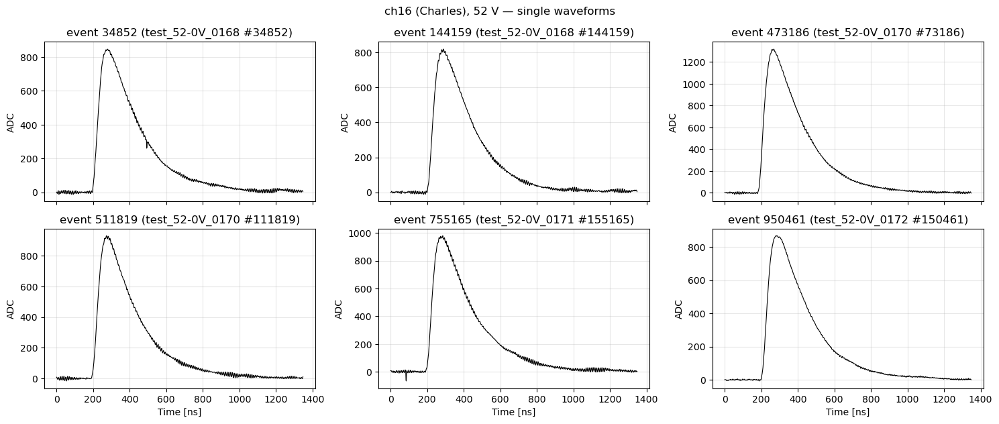

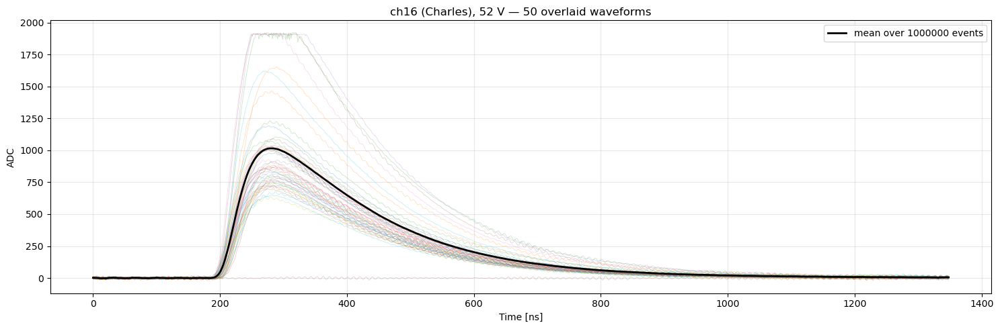

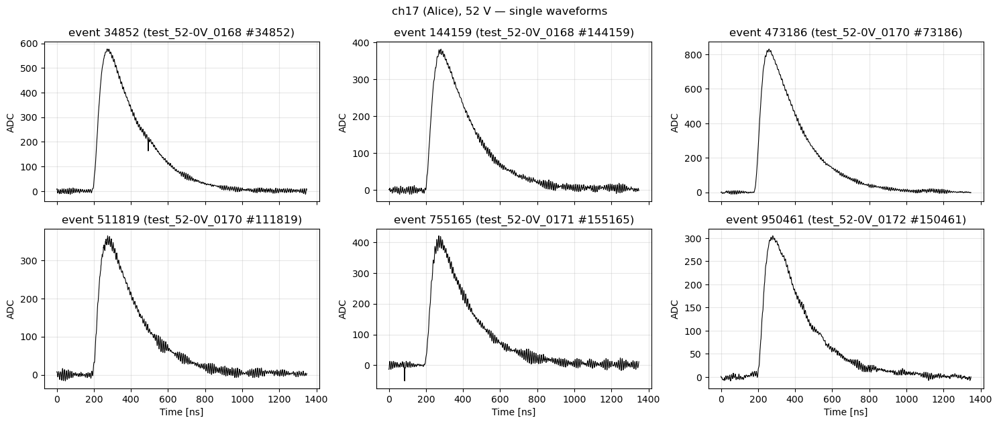

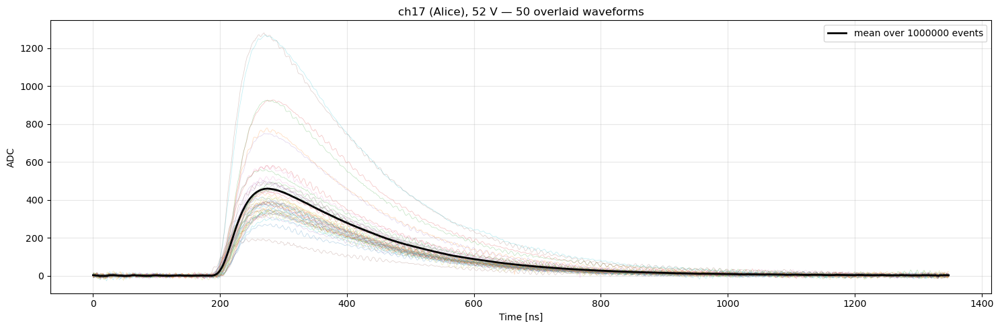

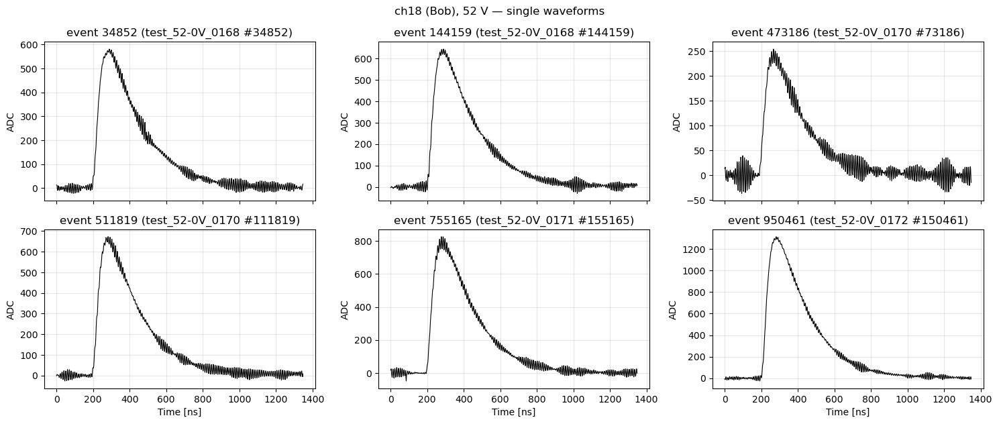

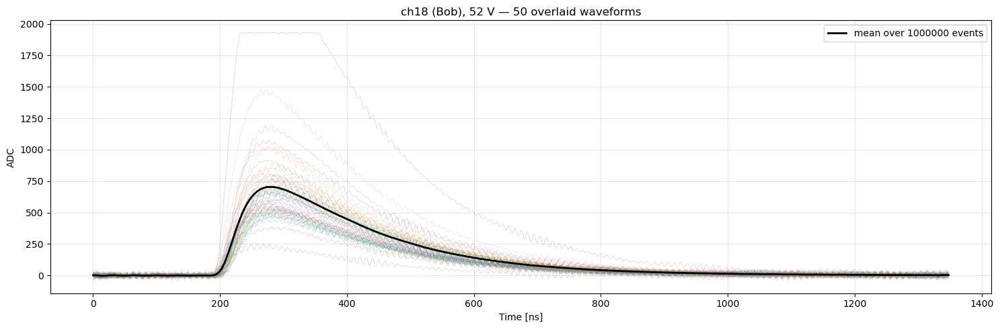

In [91]:
# === Alcune waveform di ogni canale, per vedere come sono i segnali ===
N_WF_SINGOLE = 6          # waveform mostrate una per pannello
N_WF_SOVRAPPOSTE = 50     # waveform sovrapposte nel pannello finale
EVENTI_SCELTI = None      # lista di indici, es. [0, 10, 250]; None = a caso
SEED = 1                  # cambiarlo per vedere altri eventi a caso

t_wf = np.arange(N_SAMPLES) * SAMPLING_TIME
eventi_per_run = {}       # gli stessi eventi si riusano nella cella del filtro
# Stesso SEED per ogni canale: gli eventi mostrati sono gli stessi trigger
# visti dai tre rivelatori, e i pannelli si confrontano fra loro

for lab in wf_canali:
    wf_run = wf_canali[lab]
    rng = np.random.default_rng(SEED)
    eventi = (list(EVENTI_SCELTI) if EVENTI_SCELTI is not None
              else sorted(rng.choice(len(wf_run), N_WF_SINGOLE, replace=False)))
    eventi_per_run[lab] = eventi
    if not mostra(lab):
        continue

    ncol = 3
    nrow = int(np.ceil(len(eventi) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, eventi):
        ax.plot(t_wf, wf_run[ev], lw=0.8, color="k")
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]})")
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    for ax in axes.flat[len(eventi):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(f"{DESCRIZIONE[lab]} — single waveforms")
    plt.tight_layout()
    plt.show()

    # Sovrapposte + media su tutti gli eventi: la media mostra dove cade il segnale
    # (media in float64 senza copiare la matrice: a run intera sono milioni di eventi)
    sovr = rng.choice(len(wf_run), min(N_WF_SOVRAPPOSTE, len(wf_run)), replace=False)
    fig, ax = plt.subplots(figsize=(15, 5))
    for ev in sovr:
        ax.plot(t_wf, wf_run[ev], lw=0.5, alpha=0.3)
    ax.plot(t_wf, wf_run.mean(axis=0, dtype=np.float64), lw=2, color="k", label=f"mean over {len(wf_run)} events")
    ax.set_xlabel("Time [ns]")
    ax.set_ylabel("ADC")
    ax.set_title(f"{DESCRIZIONE[lab]} — {len(sovr)} overlaid waveforms")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

Filtro: low-pass 50 MHz
[ch16 (Charles), 52 V] rumore rms per evento (mediana su 50000 eventi): grezza 269.04 ADC, filtrata 268.99 ADC


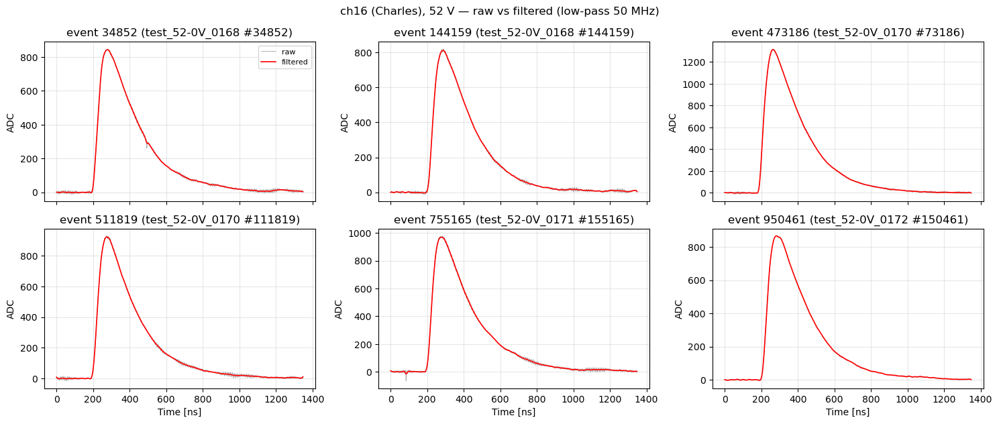

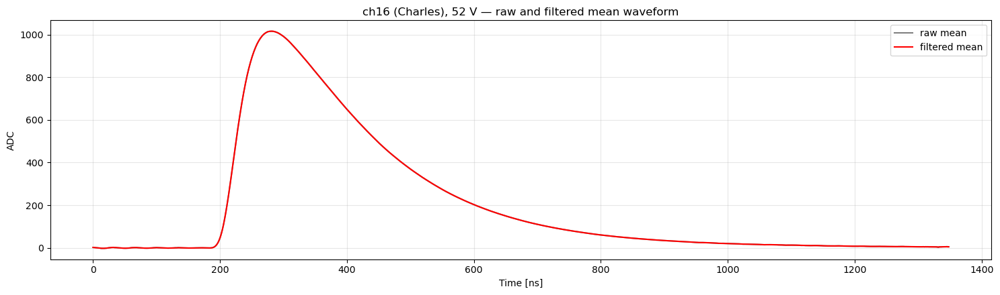

[ch17 (Alice), 52 V] rumore rms per evento (mediana su 50000 eventi): grezza 119.80 ADC, filtrata 119.68 ADC


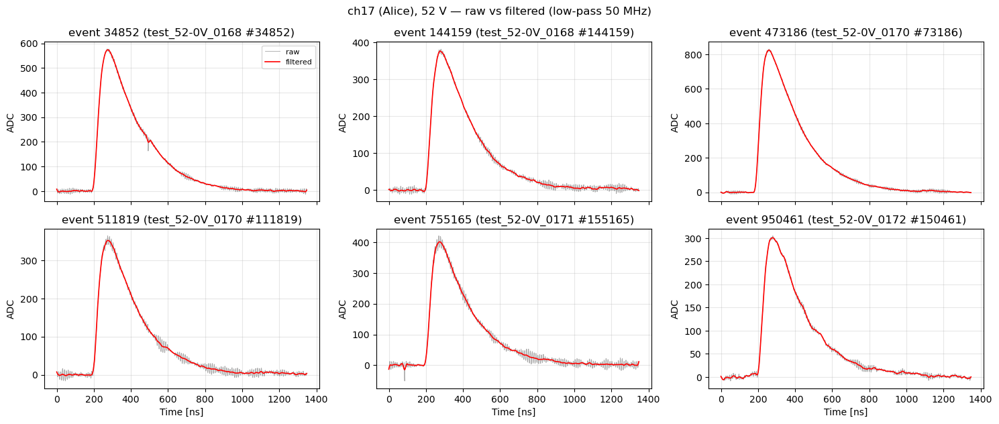

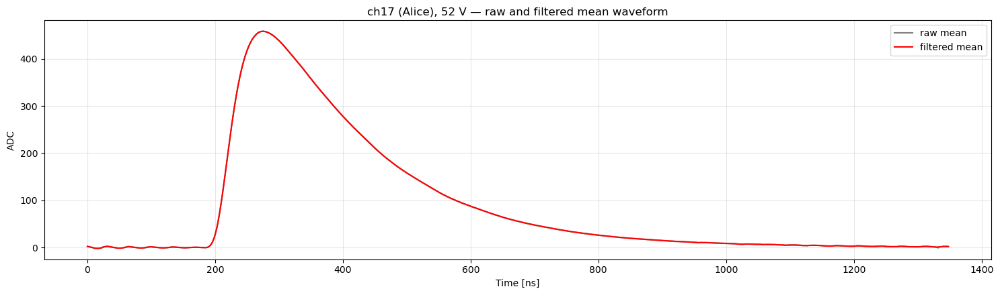

[ch18 (Bob), 52 V] rumore rms per evento (mediana su 50000 eventi): grezza 184.91 ADC, filtrata 184.50 ADC


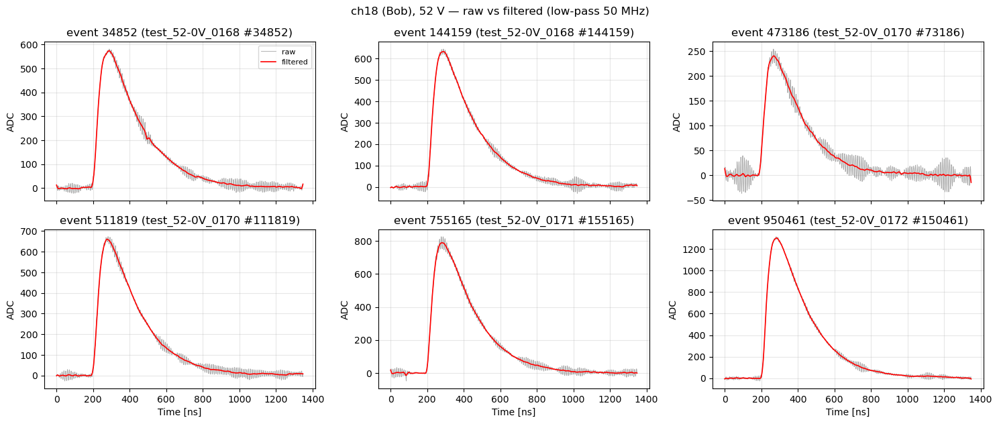

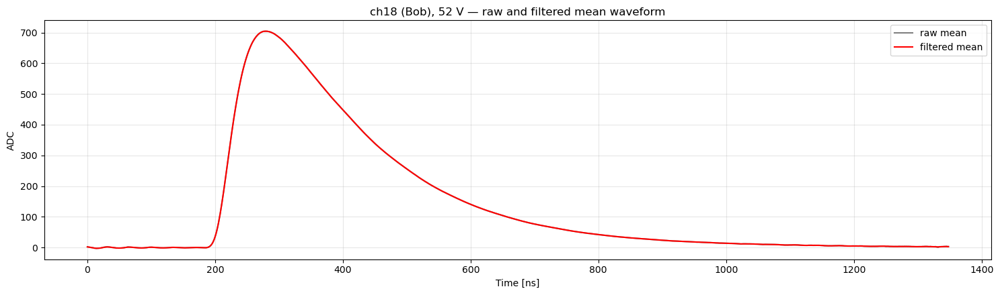

In [92]:
# === Filtro delle waveform: grezza e filtrata a confronto ===
from scipy.signal import butter, iirnotch, sosfiltfilt, filtfilt

# Lo spettro del rumore (run 54 V senza LED) ha una riga dominante a ~98 MHz,
# larga una decina di MHz, e una minore a ~188 MHz; il segnale del SiPM sta
# sotto ~30 MHz (salita ~20 ns, discesa di centinaia di ns). Un passa-basso a
# 50 MHz toglie entrambe le righe senza toccare l'impulso. I notch sono
# l'alternativa se si vuole lasciare intatto il resto della banda: con Q alto
# pero' sono piu' stretti della riga a 98 MHz, che e' larga.
# Si filtra con filtfilt (avanti e indietro): fase nulla, quindi l'impulso non
# si sposta nel tempo e l'inizio della salita resta dov'e'.
# Lo stesso filtro si applica a tutti i canali.
FILTRO_LOWPASS = True
LP_CUTOFF_MHZ = 50.0
LP_ORDINE = 4

FILTRO_NOTCH = False
NOTCH_MHZ = [97.5, 187.5]
NOTCH_Q = 10                  # Q = f0 / larghezza: 10 a 98 MHz -> ~10 MHz

USA_FILTRATE = True           # le celle successive analizzano le WF filtrate

fs_hz = 1e9 / SAMPLING_TIME   # SAMPLING_TIME e' in ns


BLOCCO_EVENTI = 50000         # il filtro lavora in float64: a blocchi la memoria resta limitata


def filtra_waveform(wf):
    """Filtra una matrice (eventi, campioni) lungo i campioni; restituisce float32.

    A blocchi di BLOCCO_EVENTI: tutta la run in float64 in un colpo solo
    vorrebbe decine di GB per canale, fra copie e padding di filtfilt.
    Il filtro agisce su ogni evento separatamente, quindi il risultato non
    dipende dal blocco.
    """
    out = np.empty(wf.shape, dtype=np.float32)
    sos = butter(LP_ORDINE, LP_CUTOFF_MHZ * 1e6, btype="low", fs=fs_hz, output="sos") if FILTRO_LOWPASS else None
    for i0 in range(0, wf.shape[0], BLOCCO_EVENTI):
        x = wf[i0:i0 + BLOCCO_EVENTI].astype(np.float64)
        if FILTRO_NOTCH:
            for f0 in NOTCH_MHZ:
                b, a = iirnotch(f0 * 1e6, NOTCH_Q, fs_hz)
                x = filtfilt(b, a, x, axis=1)
        if FILTRO_LOWPASS:
            x = sosfiltfilt(sos, x, axis=1)
        out[i0:i0 + BLOCCO_EVENTI] = x
    return out


wf_filt_canali = {ch: filtra_waveform(wf_canali[ch]) for ch in wf_canali}
wf_analisi = wf_filt_canali if USA_FILTRATE else wf_canali

t_f = np.arange(N_SAMPLES) * SAMPLING_TIME
filtri = " + ".join(([f"low-pass {LP_CUTOFF_MHZ:g} MHz"] if FILTRO_LOWPASS else []) +
                    ([f"notch {NOTCH_MHZ} MHz (Q={NOTCH_Q})"] if FILTRO_NOTCH else [])) or "none"
print(f"Filtro: {filtri}")

for lab in wf_canali:
    raw, filt = wf_canali[lab], wf_filt_canali[lab]
    # rms su un sottoinsieme: la mediana e' stabile gia' con decine di migliaia di eventi,
    # e su tutta la run std() creerebbe copie in float64 da GB
    sub = slice(0, min(len(raw), 50000))
    print(f"[{DESCRIZIONE[lab]}] rumore rms per evento (mediana su {sub.stop} eventi): "
          f"grezza {np.median(raw[sub].std(axis=1)):.2f} ADC, filtrata {np.median(filt[sub].std(axis=1)):.2f} ADC")

    if not mostra(lab):
        continue

    # --- Stessi eventi della cella delle waveform, grezza e filtrata sovrapposte ---
    eventi = eventi_per_run[lab]
    ncol = 3
    nrow = int(np.ceil(len(eventi) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, eventi):
        ax.plot(t_f, raw[ev], lw=0.6, color="gray", alpha=0.7, label="raw")
        ax.plot(t_f, filt[ev], lw=1.2, color="red", label="filtered")
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]})")
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    for ax in axes.flat[len(eventi):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    axes.flat[0].legend(loc="upper right", fontsize=8)
    fig.suptitle(f"{DESCRIZIONE[lab]} — raw vs filtered ({filtri})")
    plt.tight_layout()
    plt.show()

    # --- Waveform media, prima e dopo: mostra se il filtro deforma l'impulso ---
    fig, ax = plt.subplots(figsize=(15, 4.5))
    ax.plot(t_f, raw.mean(axis=0, dtype=np.float64), color="gray", label="raw mean")
    ax.plot(t_f, filt.mean(axis=0, dtype=np.float64), color="red", label="filtered mean")
    ax.set_xlabel("Time [ns]"); ax.set_ylabel("ADC"); ax.grid(True, alpha=0.3); ax.legend()
    ax.set_title(f"{DESCRIZIONE[lab]} — raw and filtered mean waveform")
    plt.tight_layout()
    plt.show()

=== ch16 (Charles), 52 V ===
Risoluzione in frequenza: 0.741 MHz  (Nyquist 375 MHz)
 riga [MHz]  larghezza [MHz]  sopra il fondo  attenuazione filtro
      103.0             12.5            994x             2.4e+05x


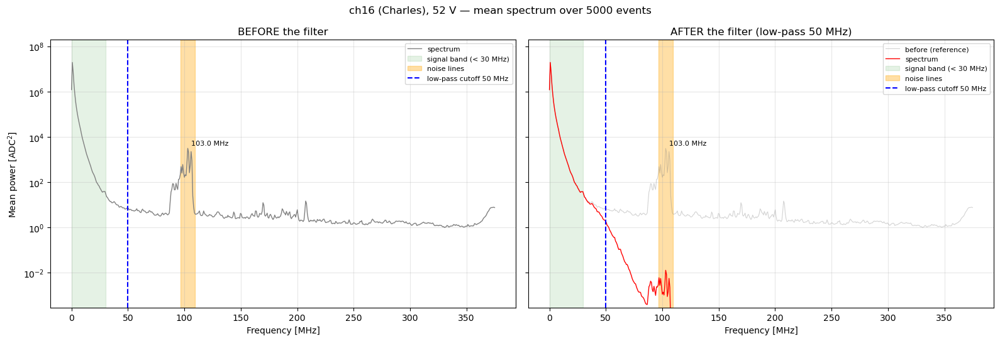

=== ch17 (Alice), 52 V ===
Risoluzione in frequenza: 0.741 MHz  (Nyquist 375 MHz)
 riga [MHz]  larghezza [MHz]  sopra il fondo  attenuazione filtro
      103.0             19.0            614x             2.4e+05x
      106.0              1.4             13x             4.0e+05x


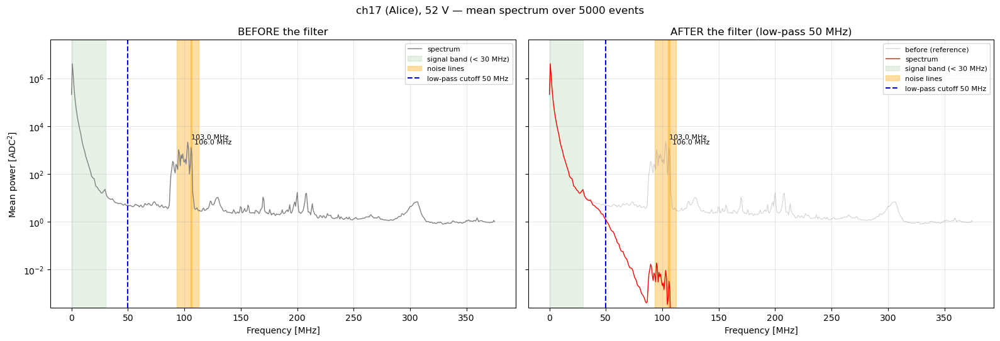

=== ch18 (Bob), 52 V ===
Risoluzione in frequenza: 0.741 MHz  (Nyquist 375 MHz)
 riga [MHz]  larghezza [MHz]  sopra il fondo  attenuazione filtro
      103.0             13.5           3183x             2.4e+05x


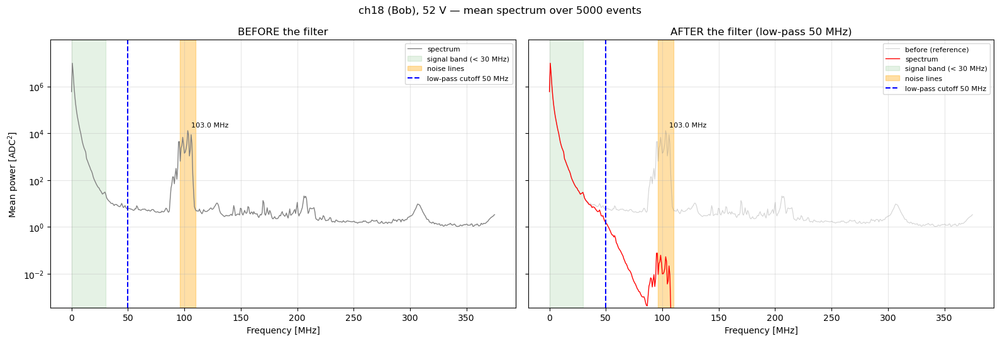

In [93]:
# === Spettro del rumore: dove sono le bande, prima e dopo il filtro ===
# Come si legge: la FFT scompone ogni waveform in sinusoidi; la potenza media
# su molti eventi dice quanta ampiezza c'e' a ogni frequenza. Il segnale del
# SiPM e' lento e sta tutto in basso (sotto ~30 MHz). Un rumore periodico
# compare invece come un picco stretto che spicca sul fondo: e' una "riga".
# Le righe si trovano da sole (find_peaks sul logaritmo della potenza grezza)
# e si marcano in tutti e due i pannelli, cosi' si vede quanto le ha tolte il filtro.
from scipy.signal import find_peaks, peak_widths

N_EVENTI_SPETTRO = 5000      # bastano per una media stabile
PROMINENZA_DECADI = 1.0      # una riga deve spiccare di 10x sul fondo vicino; con 3x
                             # si prendono anche le fluttuazioni del fondo
F_MIN_RIGHE_MHZ = 35.0       # sotto c'e' il segnale: non lo si cerca come rumore
BANDA_SEGNALE_MHZ = 30.0


def spettro_medio(wf):
    """(frequenze [MHz], potenza media [ADC^2]) su N_EVENTI_SPETTRO eventi.

    Si toglie la media di ogni evento (se no domina la frequenza zero) e si
    applica una finestra di Hann, che evita che i bordi della traccia, tagliati
    di netto, spargano potenza su tutte le frequenze.
    """
    x = wf[:N_EVENTI_SPETTRO].astype(np.float64)
    finestra = np.hanning(x.shape[1])
    x = (x - x.mean(axis=1, keepdims=True)) * finestra
    pot = (np.abs(np.fft.rfft(x, axis=1)) ** 2).mean(axis=0) / (finestra ** 2).sum()
    freq = np.fft.rfftfreq(x.shape[1], d=SAMPLING_TIME * 1e-9) / 1e6
    return freq, pot


for lab in wf_canali:
    freq, pot_raw = spettro_medio(wf_canali[lab])
    _, pot_filt = spettro_medio(wf_filt_canali[lab])
    df_mhz = freq[1] - freq[0]

    # Righe di rumore sullo spettro grezzo
    cerca = freq >= F_MIN_RIGHE_MHZ
    idx, prop = find_peaks(np.log10(pot_raw[cerca]), prominence=PROMINENZA_DECADI)
    idx = np.flatnonzero(cerca)[idx]
    # larghezza a meta' altezza in scala logaritmica, convertita in MHz
    larg = peak_widths(np.log10(pot_raw), idx, rel_height=0.5)[0] * df_mhz

    print(f"=== {DESCRIZIONE[lab]} ===")
    print(f"Risoluzione in frequenza: {df_mhz:.3f} MHz  (Nyquist {freq[-1]:.0f} MHz)")
    print(f"{'riga [MHz]':>11} {'larghezza [MHz]':>16} {'sopra il fondo':>15} {'attenuazione filtro':>20}")
    for i, w, prom in zip(idx, larg, prop["prominences"]):
        att = pot_raw[i] / pot_filt[i]
        # oltre ~1e6 il filtrato e' sul pavimento numerico (float32): il numero non e' una misura
        att_txt = f"{att:19.1e}x" if att < 1e6 else f"{'> 1e6x':>20}"
        print(f"{freq[i]:11.1f} {w:16.1f} {10 ** prom:14.0f}x {att_txt}")

    if not mostra(lab):
        continue
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
    for ax, pot, titolo, colore in [(axes[0], pot_raw, "BEFORE the filter", "gray"),
                                    (axes[1], pot_filt, f"AFTER the filter ({filtri})", "red")]:
        if pot is pot_filt:
            ax.semilogy(freq, pot_raw, color="gray", lw=0.8, alpha=0.35, label="before (reference)")
        ax.semilogy(freq, pot, color=colore, lw=1, label="spectrum")
        ax.axvspan(0, BANDA_SEGNALE_MHZ, color="green", alpha=0.10, label=f"signal band (< {BANDA_SEGNALE_MHZ:g} MHz)")
        for k, (i, w) in enumerate(zip(idx, larg)):
            ax.axvspan(freq[i] - w / 2, freq[i] + w / 2, color="orange", alpha=0.35,
                       label="noise lines" if k == 0 else None)
            ax.annotate(f"{freq[i]:.1f} MHz", (freq[i], pot_raw[i]), textcoords="offset points",
                        xytext=(4, 4), fontsize=8)
        if FILTRO_LOWPASS:
            ax.axvline(LP_CUTOFF_MHZ, color="blue", ls="--", label=f"low-pass cutoff {LP_CUTOFF_MHZ:g} MHz")
        if FILTRO_NOTCH:
            for k, f0 in enumerate(NOTCH_MHZ):
                ax.axvline(f0, color="purple", ls=":", label="notch" if k == 0 else None)
        ax.set_title(titolo)
        ax.set_xlabel("Frequency [MHz]")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8, loc="upper right")
    axes[0].set_ylabel("Mean power [ADC$^2$]")
    # Sotto ~1e-4 del fondo grezzo il filtrato tocca la precisione dei float32:
    # mostrarlo schiaccerebbe tutto il resto senza aggiungere informazione
    axes[0].set_ylim(np.median(pot_raw) * 1e-4, pot_raw.max() * 10)
    fig.suptitle(f"{DESCRIZIONE[lab]} — mean spectrum over {min(N_EVENTI_SPETTRO, len(wf_canali[lab]))} events")
    plt.tight_layout()
    plt.show()

[ch16 (Charles), 52 V] finestra lunga della carica [180, 1000] ns (cumulata al 99% a 992 ns, crescita nella coda 1.0%); finestra dell'impulso [205, 1149] ns (massimo medio 1016 ADC a 281 ns; inizio al 10%, fine al 1% del massimo), 1000000 eventi
    Q_segnale : media       264734  mediana       234876  std     101128 ADC ns
    Q_baseline: media           -0  mediana           -0  std         10 ADC ns
[ch17 (Alice), 52 V] finestra lunga della carica [180, 1000] ns (cumulata al 99% a 977 ns, crescita nella coda 0.8%); finestra dell'impulso [204, 1116] ns (massimo medio 458 ADC a 275 ns; inizio al 10%, fine al 1% del massimo), 1000000 eventi
    Q_segnale : media       116720  mediana       103024  std      50024 ADC ns
    Q_baseline: media           -1  mediana           -0  std         10 ADC ns
[ch18 (Bob), 52 V] finestra lunga della carica [180, 1000] ns (cumulata al 99% a 988 ns, crescita nella coda 0.9%); finestra dell'impulso [205, 1149] ns (massimo medio 704 ADC a 279 ns; inizi

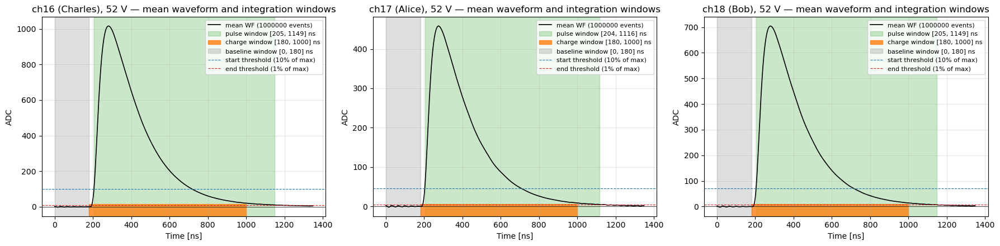

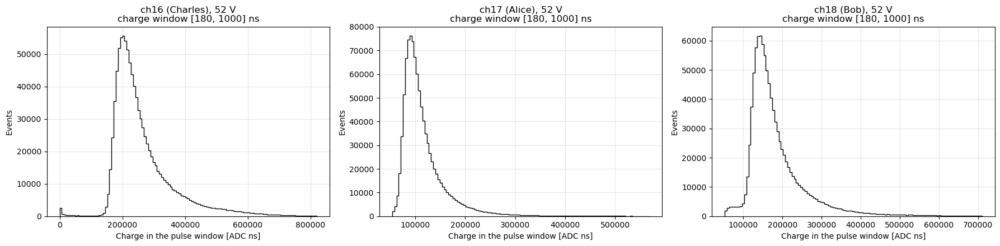

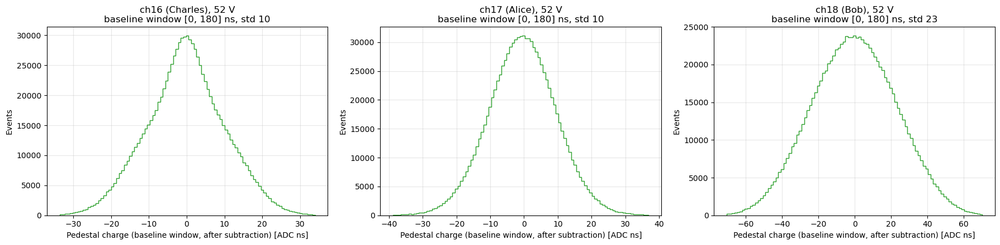

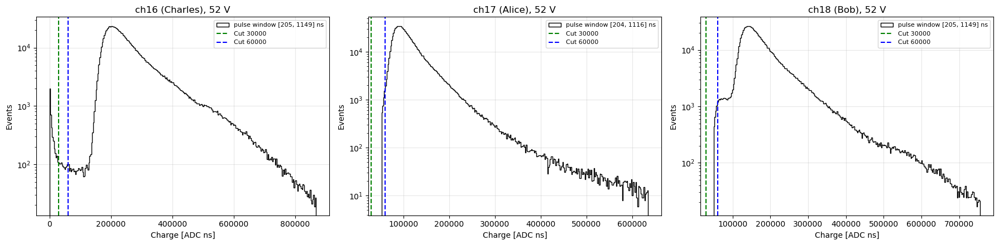

In [94]:
# === Carica per evento: nella finestra dell'impulso e piedistallo, per ogni rivelatore ===
# Sulle WF FILTRATE (wf_filt_canali), con la baseline per evento gia' sottratta.
# Carica = SOMMA DEI CAMPIONI x dt [ADC ns]. Il dt e' necessario: la somma dei campioni
# da sola scala come 1/dt (a 1 GS/s e' 1.33 volte quella a 750 MS/s per lo stesso impulso),
# mentre somma x dt e' l'integrale dell'impulso e non dipende dalla frequenza (l'impulso
# e' filtrato a 50 MHz, campionato molto sopra Nyquist). Il notebook del guadagno somma
# i campioni senza dt: Qpe_tot nel JSON e' in ADC campione a dt = sampling_time_ns del
# JSON, e la cella dell'equalizzazione lo porta in ADC ns moltiplicando per quel dt,
# cosi' Q_SEGNALE / Qpe_tot e' un rapporto fra grandezze nella stessa unita'.
# Due cariche per evento e per canale:
#  - Q_segnale: nella FINESTRA LUNGA della carica (FINESTRA_Q_NS, vedi sotto);
#  - Q_baseline: nella finestra della baseline (BASELINE_NS), dopo la sottrazione: il piedistallo.
#
# FINESTRA LUNGA DELLA CARICA: stesso criterio di SiPM_Characterization_Gain_Study
# (cella della finestra lunga), cosi' Q_segnale / Qpe_tot non porta un errore di
# finestra. Dalla fine della baseline al primo istante in cui la carica cumulata
# della WF media raggiunge FRAZ_CARICA_FINESTRA del suo valore finale (media della
# cumulata negli ultimi CODA_PLATEAU_NS della traccia), arrotondato per eccesso a
# 50 ns. Si misura in ns sulla WF media del canale, quindi non dipende dalla
# frequenza di campionamento; dipende dal segnale, per questo e' per canale.
# NON si integra "fino a fine traccia": la lunghezza della traccia e' N*dt (410 ns a
# 2.5 GS/s, 1365 ns a 750 MS/s) e la frazione di coda contenuta cambierebbe con la
# frequenza; e la coda del SiPM a fine traccia non e' ancora zero (~+0.5% del massimo
# a 750 MS/s). Se la fine cade oltre la traccia la cella lo dice: la carica e' troncata
# rispetto a Qpe_tot e la run va trattata a parte.
#
# Il picco della carica non cambia di piu' dell'1-3% fra 900 ns e fine traccia
# (run 0168), ma per il light yield conta che le due finestre contengano la stessa
# frazione dell'impulso.
#
# FINESTRA_CARICA_NS (10% -> 1% della WF media, sotto) resta la finestra dove le
# celle dell'efficienza cercano il segnale sopra soglia: non si tocca, l'efficienza
# non cambia.
#
# Finestra dell'impulso, dalla WF media di ogni canale (la stessa finestra per
# tutti gli eventi): comincia dove la media supera FRAZ_INIZIO_FINESTRA del suo
# massimo (cercato dal massimo all'indietro, cosi' il rumore prima della salita
# non la sposta) e finisce dove, dopo il massimo, scende sotto
# FRAZ_FINE_FINESTRA del massimo.
# "Scende fino alla baseline" non e' un incrocio dello zero: misurato sulle run
# 0168-0171 la coda decade come un esponenziale (~200 ns) e non scavalca mai la
# baseline, a fine traccia e' ancora allo 0.4% del massimo. Come "baseline" si
# prende quindi una frazione piccola del massimo, ma sopra il rumore della
# media (~1 ADC, cioe' ~0.1% del massimo): con 1% la finestra finisce a ~1150 ns.
# Abbassarla allunga la finestra fin quasi a fine traccia.
FRAZ_INIZIO_FINESTRA = 0.10   # X
FRAZ_FINE_FINESTRA = 0.01     # Y

# Finestra lunga della carica (stessi valori del notebook del guadagno)
FRAZ_CARICA_FINESTRA = 0.99
CODA_PLATEAU_NS = 300
# Controllo: nell'ultimo tratto (CODA_PLATEAU_NS) la cumulata deve essere gia' piatta, se no
# il "valore finale" e' sottostimato e il 99% cade troppo presto (traccia troppo corta:
# misurato sulla run 0190, 1 GS/s, il criterio dava 800 ns e la carica risultava il 3-5%
# piu' bassa di quella a 750 MS/s; integrando fino a fine traccia, 1011 ns, i due
# coincidono entro 0.5%). In quel caso la finestra va fino a fine traccia: e' tutta la coda
# che c'e'. Soglia sulla crescita della cumulata, relativa al suo valore finale, nell'ultimo tratto.
CRESCITA_CODA_MAX = 0.02

# Q_baseline e' la somma sulla WF filtrata DOPO la sottrazione della baseline
# per evento, nella finestra BASELINE_NS: e' il piedistallo che resta. La baseline
# e' stata tolta dai campioni grezzi di quella stessa finestra, quindi la somma
# vale ~0 per costruzione: l'unico residuo e' quello che il filtro sposta (il
# filtro e' lineare, ma agisce sui campioni vicini ai bordi della finestra).
# E' una somma su BASELINE_NS (meno campioni di quella sull'impulso).
dt_q = SAMPLING_TIME
t_q = np.arange(N_SAMPLES) * dt_q
mask_bl_q = (t_q >= BASELINE_NS[0]) & (t_q <= BASELINE_NS[1])

WF_MEDIA_Q = {}              # canale -> WF media filtrata (per il grafico delle finestre)
FINESTRA_CARICA_NS = {}      # canale -> (inizio, fine) della finestra dell'impulso [ns] (efficienza)
FINESTRA_Q_NS = {}           # canale -> (inizio, fine) della finestra lunga della carica [ns]
Q_SEGNALE, Q_BASELINE = {}, {}   # canale -> carica per evento [ADC ns]
for ch in CANALI:
    wf = wf_filt_canali[ch]
    media = wf.mean(axis=0, dtype=np.float64)
    i_max = int(np.argmax(media))
    amp = media[i_max]
    WF_MEDIA_Q[ch] = media
    sotto = np.flatnonzero(media[:i_max + 1] < FRAZ_INIZIO_FINESTRA * amp)
    j0 = sotto[-1] + 1 if len(sotto) else 0
    ritorno = np.flatnonzero(media[i_max:] <= FRAZ_FINE_FINESTRA * amp)
    if len(ritorno):
        j1 = i_max + int(ritorno[0])
    else:
        j1 = N_SAMPLES - 1
        print(f"ATTENZIONE {DESCRIZIONE[ch]}: la WF media non scende sotto il {100 * FRAZ_FINE_FINESTRA:g}% "
              f"del massimo prima della fine della traccia: la finestra finisce a {t_q[j1]:.0f} ns")
    FINESTRA_CARICA_NS[ch] = (float(t_q[j0]), float(t_q[j1]))
    # Finestra lunga: stesso calcolo del notebook del guadagno, sulla WF media del canale
    i_bl_fine = np.searchsorted(t_q, BASELINE_NS[1])
    m_q = media - media[mask_bl_q].mean()
    cum = np.cumsum(m_q[i_bl_fine:])
    plateau = cum[t_q[i_bl_fine:] >= t_q[-1] - CODA_PLATEAU_NS].mean()
    t_frac = t_q[i_bl_fine:][np.argmax(cum >= FRAZ_CARICA_FINESTRA * plateau)]
    fine_q = float(np.ceil(t_frac / 50) * 50)
    i_coda = np.searchsorted(t_q[i_bl_fine:], t_q[-1] - CODA_PLATEAU_NS)
    crescita_coda = (cum[-1] - cum[i_coda]) / cum[-1]
    if crescita_coda > CRESCITA_CODA_MAX:
        print(f"ATTENZIONE {DESCRIZIONE[ch]}: la carica cumulata cresce ancora del {100 * crescita_coda:.1f}% "
              f"negli ultimi {CODA_PLATEAU_NS} ns della traccia: il criterio (99% a {fine_q:.0f} ns) non e' "
              f"affidabile, si integra fino a fine traccia ({t_q[-1]:.0f} ns, {t_q[-1] - t_frac:.0f} ns dopo il 99%). "
              f"Confrontare con la finestra del LED: la coda oltre la traccia manca")
        fine_q = float(t_q[-1])
    if fine_q > t_q[-1]:
        print(f"ATTENZIONE {DESCRIZIONE[ch]}: la finestra lunga finirebbe a {fine_q:.0f} ns, oltre la traccia "
              f"({t_q[-1]:.0f} ns): la carica e' troncata rispetto a Qpe_tot")
        fine_q = float(t_q[-1])
    FINESTRA_Q_NS[ch] = (float(BASELINE_NS[1]), fine_q)
    mask_sig = (t_q >= FINESTRA_Q_NS[ch][0]) & (t_q <= FINESTRA_Q_NS[ch][1])

    n_ev = wf.shape[0]
    qs, qb = np.empty(n_ev), np.empty(n_ev)
    for k in range(0, n_ev, BLOCCO_EVENTI):
        blocco = wf[k:k + BLOCCO_EVENTI]
        qs[k:k + BLOCCO_EVENTI] = blocco[:, mask_sig].sum(axis=1, dtype=np.float64) * dt_q
        qb[k:k + BLOCCO_EVENTI] = blocco[:, mask_bl_q].sum(axis=1, dtype=np.float64) * dt_q
    Q_SEGNALE[ch], Q_BASELINE[ch] = qs, qb

    print(f"[{DESCRIZIONE[ch]}] finestra lunga della carica [{FINESTRA_Q_NS[ch][0]:.0f}, {FINESTRA_Q_NS[ch][1]:.0f}] ns "
          f"(cumulata al {100 * FRAZ_CARICA_FINESTRA:g}% a {t_frac:.0f} ns, crescita nella coda {100 * crescita_coda:.1f}%); finestra dell'impulso [{t_q[j0]:.0f}, {t_q[j1]:.0f}] ns "
          f"(massimo medio {amp:.0f} ADC a {t_q[i_max]:.0f} ns; inizio al {100 * FRAZ_INIZIO_FINESTRA:g}%, "
          f"fine al {100 * FRAZ_FINE_FINESTRA:g}% del massimo), {n_ev} eventi")
    for nome, q in (("segnale ", qs), ("baseline", qb)):
        print(f"    Q_{nome}: media {q.mean():12.0f}  mediana {np.median(q):12.0f}  std {q.std():10.0f} ADC ns")

canali_q = [ch for ch in CANALI if mostra(ch)]
if canali_q:
    def figura_per_canale():
        fig, assi = plt.subplots(1, len(canali_q), figsize=(6 * len(canali_q), 4.5), squeeze=False)
        return fig, assi[0]

    # --- WF media con le finestre di integrazione ---
    # Verde: finestra dell'impulso (Q_segnale). Grigio: finestra della baseline
    # (la stessa di cui e' stata tolta la media evento per evento). Le linee
    # tratteggiate sono le soglie che definiscono inizio e fine della finestra.
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        media = WF_MEDIA_Q[ch]
        amp = media.max()
        j0_ns, j1_ns = FINESTRA_CARICA_NS[ch]
        ax.plot(t_q, media, color="k", lw=1.2, label=f"mean WF ({len(wf_filt_canali[ch])} events)")
        ax.axvspan(j0_ns, j1_ns, color="tab:green", alpha=0.25,
                   label=f"pulse window [{j0_ns:.0f}, {j1_ns:.0f}] ns")
        ax.axvspan(*FINESTRA_Q_NS[ch], ymin=0, ymax=0.06, color="tab:orange", alpha=0.8,
                   label=f"charge window [{FINESTRA_Q_NS[ch][0]:.0f}, {FINESTRA_Q_NS[ch][1]:.0f}] ns")
        ax.axvspan(BASELINE_NS[0], BASELINE_NS[1], color="tab:gray", alpha=0.25,
                   label=f"baseline window [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns")
        ax.axhline(FRAZ_INIZIO_FINESTRA * amp, color="tab:blue", ls="--", lw=0.8,
                   label=f"start threshold ({100 * FRAZ_INIZIO_FINESTRA:g}% of max)")
        ax.axhline(FRAZ_FINE_FINESTRA * amp, color="tab:red", ls="--", lw=0.8,
                   label=f"end threshold ({100 * FRAZ_FINE_FINESTRA:g}% of max)")
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("Time [ns]"); ax.set_ylabel("ADC")
        ax.set_title(f"{DESCRIZIONE[ch]} — mean waveform and integration windows")
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    # --- Distribuzione della carica del segnale, per canale ---
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        lo, hi = np.percentile(Q_SEGNALE[ch], (0.1, 99.9))
        ax.hist(Q_SEGNALE[ch], bins=np.linspace(lo, hi, 120), histtype="step", color="k")
        ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
        ax.set_title(f"{DESCRIZIONE[ch]}\ncharge window [{FINESTRA_Q_NS[ch][0]:.0f}, {FINESTRA_Q_NS[ch][1]:.0f}] ns")
        ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Distribuzione della carica nella finestra della baseline, per canale ---
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        lo, hi = np.percentile(Q_BASELINE[ch], (0.05, 99.95))
        ax.hist(Q_BASELINE[ch], bins=np.linspace(lo, hi, 100), histtype="step", color="tab:green")
        ax.set_xlabel("Pedestal charge (baseline window, after subtraction) [ADC ns]"); ax.set_ylabel("Events")
        ax.set_title(f"{DESCRIZIONE[ch]}\nbaseline window [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns, std {Q_BASELINE[ch].std():.0f}")
        ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Carica nella finestra dell'impulso, con i tagli in carica provati (la baseline ha i suoi plot) ---
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        lo, hi = np.percentile(Q_SEGNALE[ch], (0.05, 99.95))
        bins = np.linspace(lo, hi, 300)
        ax.hist(Q_SEGNALE[ch], bins=bins, histtype="step", color="k",
                label=f"pulse window [{FINESTRA_CARICA_NS[ch][0]:.0f}, {FINESTRA_CARICA_NS[ch][1]:.0f}] ns")
        ax.axvline(30000, color='green', ls='--', lw=1.5,
                        label=f'Cut 30000')
        ax.axvline(60000, color='blue', ls='--', lw=1.5,
                                label=f'Cut 60000')
        ax.set_yscale("log")
        ax.set_xlabel("Charge [ADC ns]"); ax.set_ylabel("Events")
        ax.set_title(DESCRIZIONE[ch])
        # ax.set_xlim(-10000,200000)
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

PDE datasheet: PDE_max = 68.0%, V0 = 2.20 V
SiPM_001 (Bob): G(52 V) = 0.833 +- 0.030 1e6 e/p.e.; Qpe_tot = 327.9 +- 12.0 ADC campione = 437.2 ADC ns (dt LED 1.333 ns)  (fit su 10 punti 52-56.5 V, chi2/ndf 3.13); dV = 0.61 V, PDE datasheet 16.5% +- 2.4
    chi2/ndf = 3.1 > 1: errore del fit moltiplicato per sqrt(chi2/ndf)
SiPM_002 (Alice): G(52 V) = 0.937 +- 0.020 1e6 e/p.e.; Qpe_tot = 369.0 +- 8.0 ADC campione = 492.1 ADC ns (dt LED 1.333 ns)  (fit su 10 punti 52-56.5 V, chi2/ndf 1.52); dV = 0.65 V, PDE datasheet 17.4% +- 2.3
    chi2/ndf = 1.5 > 1: errore del fit moltiplicato per sqrt(chi2/ndf)
SiPM_003 (Charles): G(52 V) = 1.485 +- 0.023 1e6 e/p.e.; Qpe_tot = 584.6 +- 8.9 ADC campione = 779.5 ADC ns (dt LED 1.333 ns)  (fit su 10 punti 52-56.5 V, chi2/ndf 4.64); dV = 1.06 V, PDE datasheet 26.0% +- 1.9
    chi2/ndf = 4.6 > 1: errore del fit moltiplicato per sqrt(chi2/ndf)
SiPM_001 (Bob): f_G = 0.5608 +- 0.0222 (da Qpe_tot: 0.5608); f_PDE = 0.634 +- 0.105; fattore usato = 0.5608 +- 0.02

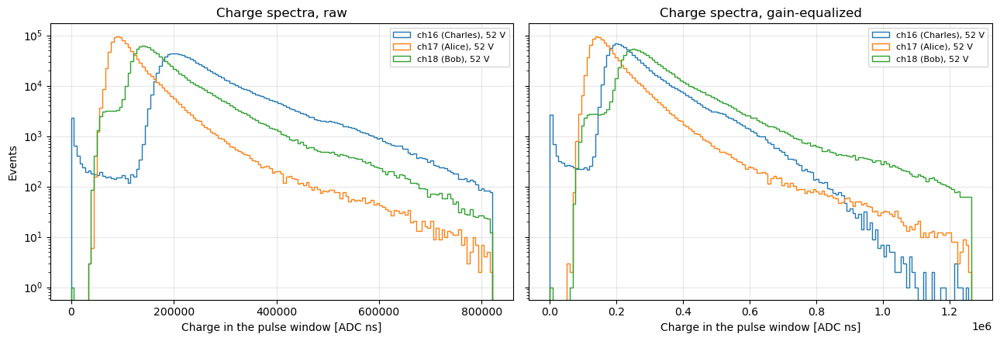

In [104]:
# === Equalizzazione dei guadagni dei tre SiPM: fattori = rapporto dei guadagni x rapporto delle PDE a 52 V, salvataggio e applicazione agli spettri ===
# I tre SiPM non si possono alimentare a tensioni diverse (V_BIAS e' una sola), e a
# parita' di tensione la carica per fotoelettrone e' diversa: la V_bd cambia da uno
# all'altro e con lei la sovratensione. Qui si porta la scala di carica di ognuno su
# quella del SiPM di riferimento, cosi' gli spettri si confrontano in unita' comuni.
#
# GUADAGNO G = elettroni per fotoelettrone (campo `guadagno` dei JSON del LED), misurato
# in `SiPM_Characterization_Gain_Study` a 52-56.5 V: un punto per tensione, in
# measurements/sipm_gain_led_SiPM_00N_*.json (per_run). G = Qpe_tot x (elettroni per
# ADC campione della catena), con Qpe_tot la carica per p.e. sull'intero impulso (finestra
# lunga). Si prende il valore a V_EQ dal FIT lineare G(V) pesato su tutte le tensioni, non dal
# punto singolo: il punto a 52 V e' il piu' vicino a V_bd e quello con l'errore piu' grande
# (26% su SiPM_001, 13% su SiPM_002, 0.8% su SiPM_003); il fit usa tutti e 10 i punti.
#
# Fattore di guadagno f_G = G(SiPM) / G(riferimento). Per portare uno spettro sulla scala del
# riferimento si DIVIDE per f (un SiPM con meno guadagno ha il p.e. piu' in basso e va
# alzato). Il guadagno equalizza la carica per p.e., NON la probabilita' di rivelare un fotone.
#
# PDE (USA_PDE_EQ): a 52 V i tre SiPM hanno sovratensioni diverse (V_bd 50.94 / 51.35 /
# 51.39 V: 1.06 / 0.65 / 0.61 V) e la PDE sale ripida con la sovratensione, quindi a parita'
# di luce SiPM_003 rivela di piu'. Solo col guadagno l'Alice dei dati nuovi esce a 0.72 volte
# Charles, mentre coi dati Yale (stesso SiPM su tutti i pannelli) esce a 0.95: la differenza
# e' la PDE. Si usa la PDE del datasheet S13360-6075PE come nel notebook del guadagno
# (stessi punti digitalizzati e stesso modello PDE_max (1 - exp(-dV/V0)), ESTRAPOLATO sotto
# 2 V, dove cadono tutti e tre i SiPM). dV = V_EQ - V_bd, con V_bd misurato nei JSON del LED.
# Di quella curva serve solo il rapporto fra SiPM: la lunghezza d'onda si semplifica se la
# forma in dV e' la stessa a ogni lambda (ipotesi non verificata). L'errore tiene conto
# solo dell'incertezza su V_bd (statistica e sistematica del JSON): circa il 13% sulla PDE
# di SiPM_001 e SiPM_002, e NON include l'errore del modello sotto i 2 V.
# Fattore totale F = f_G x f_PDE, e lo spettro si divide per F.
# Nei JSON di oggi G e Qpe_tot differiscono per la stessa costante (stessa catena e stesso
# dt per i tre SiPM: 2539.68 e/ADC campione), quindi f e' identico; la cella lo verifica.
# G e' la definizione fisica e non dipende dal dt, Qpe_tot si': e' per questo che f si
# fa sul guadagno. Qpe_tot (in ADC ns) resta per convertire la carica dei muoni in celle accese.
#
# Si scrive il JSON e poi lo si RILEGGE, cosi' quello che si applica e' quello che
# resta su disco. Serve Q_SEGNALE (cella della carica) per gli spettri equalizzati.
import glob, json, datetime

V_EQ = 52.0                   # [V] tensione a cui si valuta Qpe_tot (e' VBIAS dei run)
USA_PDE_EQ = False            # True = fattore di guadagno x fattore di PDE; False = solo guadagno (scelta attuale)
SIPM_RIFERIMENTO = "SiPM_003"
# SiPM -> pannello (indicato dall'utente il 2026-10-19; non verificato fisicamente)
SIPM_PANNELLO = {"SiPM_001": "Bob", "SiPM_002": "Alice", "SiPM_003": "Charles"}
DATA_GAIN = "10072026"        # parte finale dei nomi sipm_gain_led_<SiPM>_<DATA>.json


def fit_vs_V(path, v_eq, campo, campo_err):
    """Valore a v_eq di `campo` (per_run) dal fit lineare pesato 1/errore^2 in V.

    Ritorna (valore a v_eq, errore, pendenza, chi2 ridotto, n punti, intervallo V).
    L'errore e' quello della matrice di covarianza, moltiplicato per sqrt(chi2
    ridotto) se questo e' > 1: i punti non stanno su una retta entro gli errori
    dichiarati (misurato: chi2/ndf 1.5-4.6), e senza la correzione l'errore e'
    troppo piccolo.
    """
    with open(path) as f:
        d = json.load(f)
    V = np.array(sorted(float(k) for k in d["per_run"]))
    chiave = lambda v: next(k for k in d["per_run"] if float(k) == v)
    q = np.array([d["per_run"][chiave(v)][campo] for v in V])
    e = np.array([d["per_run"][chiave(v)][campo_err] for v in V])
    # parametri: pendenza e valore a v_eq (cosi' l'errore di Q(v_eq) e' un parametro)
    A = np.vstack([V - v_eq, np.ones_like(V)]).T
    w = 1.0 / e ** 2
    cov = np.linalg.inv(A.T @ (A * w[:, None]))
    pend, q_eq = cov @ (A.T @ (w * q))
    chi2r = float(np.sum(((q - A @ [pend, q_eq]) / e) ** 2) / (len(V) - 2))
    return q_eq, float(np.sqrt(cov[1, 1] * max(1.0, chi2r))), pend, chi2r, len(V), (V[0], V[-1])


# PDE del datasheet (450 nm), punti digitalizzati nel notebook del guadagno (grafico a pag. 6)
PDE_DV_V = np.array([2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 7.85])
PDE_450_PERC = np.array([41.0, 46.9, 50.4, 53.4, 55.8, 59.1, 61.3, 62.7, 63.9, 64.7, 65.3, 65.6, 65.8])
modello_pde = lambda dv, pde_max, v0: pde_max * (1 - np.exp(-dv / v0))
p_pde, _ = curve_fit(modello_pde, PDE_DV_V, PDE_450_PERC, p0=[66, 2])
print(f"PDE datasheet: PDE_max = {p_pde[0]:.1f}%, V0 = {p_pde[1]:.2f} V")

fit = {}
for sipm in SIPM_PANNELLO:
    pj = os.path.join(DIR_MISURE, f"sipm_gain_led_{sipm}_{DATA_GAIN}.json")
    q_eq, e_q, pend, chi2r, n, (v0, v1) = fit_vs_V(pj, V_EQ, "q_pe_tot_adc", "e_q_pe_tot_adc")
    g_eq, e_g, pend_g, chi2r_g, _, _ = fit_vs_V(pj, V_EQ, "guadagno", "e_guadagno")
    # Qpe_tot nel JSON e' una somma di campioni a dt = sampling_time_ns: moltiplicato per
    # quel dt e' in ADC ns, come Q_SEGNALE. Il notebook del guadagno non si rigira.
    with open(pj) as _f:
        dt_led = json.load(_f)["sampling_time_ns"]
    with open(pj) as _f:
        _d = json.load(_f)
    v_bd, e_vbd = _d["v_bd_V"], float(np.hypot(_d["e_v_bd_stat_V"], _d["e_v_bd_sist_V"]))
    ov = V_EQ - v_bd
    pde = float(modello_pde(ov, *p_pde))
    # errore sulla PDE da quello su V_bd: derivata del modello rispetto a dV
    e_pde = float(p_pde[0] / p_pde[1] * np.exp(-ov / p_pde[1]) * e_vbd)
    fit[sipm] = dict(v_bd_V=v_bd, e_v_bd_V=e_vbd, sovratensione_V=ov, pde_datasheet_perc=pde, e_pde_datasheet_perc=e_pde,
                     guadagno_52V=g_eq, e_guadagno_52V=e_g, pendenza_guadagno_per_V=pend_g,
                     q_pe_tot_adc=q_eq, e_q_pe_tot_adc=e_q, pendenza_adc_per_V=pend,
                     dt_led_ns=dt_led, q_pe_tot_adc_ns=q_eq * dt_led, e_q_pe_tot_adc_ns=e_q * dt_led,
                     chi2_ridotto=chi2r, n_punti=n, v_min=v0, v_max=v1,
                     file=os.path.basename(pj))
    print(f"{sipm} ({SIPM_PANNELLO[sipm]}): G({V_EQ:g} V) = {g_eq / 1e6:.3f} +- {e_g / 1e6:.3f} 1e6 e/p.e.; "
          f"Qpe_tot = {q_eq:.1f} +- {e_q:.1f} ADC campione = {q_eq * dt_led:.1f} ADC ns (dt LED {dt_led:.3f} ns)  "
          f"(fit su {n} punti {v0:g}-{v1:g} V, chi2/ndf {chi2r_g:.2f}); dV = {ov:.2f} V, PDE datasheet {pde:.1f}% +- {e_pde:.1f}")
    if chi2r > 1:
        print(f"    chi2/ndf = {chi2r:.1f} > 1: errore del fit moltiplicato per sqrt(chi2/ndf)")

# Rapporti dei guadagni al riferimento; errore da propagazione (SiPM e riferimento sono misure indipendenti)
rif = fit[SIPM_RIFERIMENTO]
for sipm, r in fit.items():
    f = r["guadagno_52V"] / rif["guadagno_52V"]
    e_f = 0.0 if sipm == SIPM_RIFERIMENTO else f * np.hypot(
        r["e_guadagno_52V"] / r["guadagno_52V"], rif["e_guadagno_52V"] / rif["guadagno_52V"])
    f_pde = r["pde_datasheet_perc"] / rif["pde_datasheet_perc"]
    e_f_pde = 0.0 if sipm == SIPM_RIFERIMENTO else f_pde * np.hypot(
        r["e_pde_datasheet_perc"] / r["pde_datasheet_perc"], rif["e_pde_datasheet_perc"] / rif["pde_datasheet_perc"])
    r["fattore_guadagno"], r["e_fattore_guadagno"] = f, e_f
    r["fattore_pde"], r["e_fattore_pde"] = f_pde, e_f_pde
    r["fattore"] = f * f_pde if USA_PDE_EQ else f
    r["e_fattore"] = r["fattore"] * np.hypot(e_f / f, e_f_pde / f_pde) if USA_PDE_EQ else e_f
    r["fattore_da_qpe_tot"] = r["q_pe_tot_adc"] / rif["q_pe_tot_adc"]
    r["pannello"] = SIPM_PANNELLO[sipm]
    print(f"{sipm} ({r['pannello']}): f_G = {f:.4f} +- {e_f:.4f} (da Qpe_tot: {r['fattore_da_qpe_tot']:.4f}); "
          f"f_PDE = {f_pde:.3f} +- {e_f_pde:.3f}; fattore usato = {r['fattore']:.4f} +- {r['e_fattore']:.4f}"
          + ("" if USA_PDE_EQ else "  (solo guadagno)"))
    if abs(f / r["fattore_da_qpe_tot"] - 1) > 1e-3:
        print("    ATTENZIONE: f dai guadagni e da Qpe_tot differiscono: catena o dt diversi fra i SiPM")

nome_eq = os.path.join(DIR_MISURE, "mv_panels_equalizzazione_sipm.json")
with open(nome_eq, "w") as fj:
    json.dump({
        "cosa": "fattori di equalizzazione dei SiPM a V_EQ: G(SiPM)/G(riferimento) (G in elettroni per p.e.) x PDE(SiPM)/PDE(riferimento) se usa_pde; lo spettro di carica si DIVIDE per `fattore`",
        "usa_pde": bool(USA_PDE_EQ),
        "scritto_il": datetime.datetime.now().isoformat(timespec="seconds"),
        "notebook": "tools/MV_Panels_Analysis.ipynb",
        "tensione_V": V_EQ, "riferimento": SIPM_RIFERIMENTO,
        "metodo": "guadagno: fit lineare pesato di guadagno(V) sui punti di per_run, valutato a tensione_V; PDE: modello PDE_max(1-exp(-dV/V0)) fittato sul datasheet S13360-6075PE (450 nm), dV = tensione_V - v_bd_V, estrapolato sotto 2 V",
        "sipm": fit,
    }, fj, indent=1, ensure_ascii=False)
print(f"Scritto {os.path.relpath(nome_eq, os.path.abspath('..'))}")

# --- Rilettura e applicazione: Q_SEGNALE_EQ[ch] = Q_SEGNALE[ch] / f ---
with open(nome_eq) as fj:
    eq = json.load(fj)
FATTORE_PANNELLO = {r["pannello"]: r["fattore"] for r in eq["sipm"].values()}
if abs(eq["tensione_V"] - VBIAS) > 1e-6:
    print(f"ATTENZIONE: i fattori valgono a {eq['tensione_V']:g} V, la run e' a {VBIAS:g} V")

Q_SEGNALE_EQ = {}
for ch in CANALI:
    Q_SEGNALE_EQ[ch] = Q_SEGNALE[ch] / FATTORE_PANNELLO[RIVELATORI[ch]]

# Q_SEGNALE (somma x dt) e Qpe_tot x dt_LED sono entrambe in ADC ns: il rapporto non
# dipende dalla frequenza di campionamento della run.
# picco dei muoni / Qpe_tot = celle accese per muone. Picco = massimo dell'istogramma
# smussato (la moda), non la media, che la coda di Landau sposta.
from scipy.ndimage import gaussian_filter1d
_sipm_di = {p: s for s, p in SIPM_PANNELLO.items()}
print("\nPicco dei muoni e celle accese per muone (picco / Qpe_tot a V_EQ):")
for ch in CANALI:
    q = Q_SEGNALE[ch]
    lo, hi = np.percentile(q, (0.5, 99.5))
    h, e_ = np.histogram(q, bins=np.linspace(lo, hi, 150))
    k_ = int(np.argmax(gaussian_filter1d(h.astype(float), 2)[10:])) + 10
    picco = 0.5 * (e_[k_] + e_[k_ + 1])
    qpe = fit[_sipm_di[RIVELATORI[ch]]]["q_pe_tot_adc_ns"]
    print(f"  {DESCRIZIONE[ch]}: picco {picco:9.0f} ADC ns = {picco / qpe:6.1f} celle accese")

# Picchi equalizzati rispetto al riferimento: da confrontare con Yale (stesso SiPM su tutti i pannelli)
_picchi = {}
for ch in CANALI:
    q = Q_SEGNALE_EQ[ch]
    lo, hi = np.percentile(q, (0.5, 99.5))
    h, e_ = np.histogram(q, bins=np.linspace(lo, hi, 150))
    k_ = int(np.argmax(gaussian_filter1d(h.astype(float), 2)[10:])) + 10
    _picchi[RIVELATORI[ch]] = 0.5 * (e_[k_] + e_[k_ + 1])
_ref = _picchi[SIPM_PANNELLO[SIPM_RIFERIMENTO]]
print("\nPicco equalizzato / picco del riferimento (" + ("guadagno x PDE" if USA_PDE_EQ else "solo guadagno") + "):  "
      + "  ".join(f"{n} {v / _ref:.2f}" for n, v in _picchi.items()))

# Controllo: la mediana della carica (dominata dal picco a pochi p.e.) deve avvicinarsi fra i canali
print("\nMediana di Q_segnale [ADC ns], prima -> dopo l'equalizzazione:")
for ch in CANALI:
    print(f"  {DESCRIZIONE[ch]}: {np.median(Q_SEGNALE[ch]):10.0f} -> {np.median(Q_SEGNALE_EQ[ch]):10.0f}")

if any(mostra(ch) for ch in CANALI):
    fig, assi = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    colori = dict(zip(CANALI, ("tab:blue", "tab:orange", "tab:green")))
    for ax, (titolo, Q) in zip(assi, (("raw", Q_SEGNALE), ("gain-equalized", Q_SEGNALE_EQ))):
        lo = min(np.percentile(Q[ch], 0.1) for ch in CANALI)
        hi = max(np.percentile(Q[ch], 99.9) for ch in CANALI)
        for ch in CANALI:
            ax.hist(Q[ch], bins=np.linspace(lo, hi, 150), histtype="step", color=colori[ch],
                    label=DESCRIZIONE[ch])
        ax.set_yscale("log"); ax.set_xlabel("Charge in the pulse window [ADC ns]")
        ax.set_title(f"Charge spectra, {titolo}"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    assi[0].set_ylabel("Events")
    plt.tight_layout(); plt.show()


LNF: fit sugli spettri EQUALIZZATI (solo guadagno); fit Landau (x) gaussiana dei muoni, Q >= 0.65 x moda dell'istogramma fino a fine spettro (overflow compreso), verosimiglianza di Poisson
  Charles : picco    205486 ADC ns (moda istogramma 203092), FWHM/picco 0.42; MPV 202127 +- 49, xi 20112 +- 37, sigma gauss 11635 +- 106
            fit sopra Q = 132010: 991833 eventi su 1000000 (1000 nell'overflow, oltre 820824); devianza/ndf = 80119/164 = 488.53, Pearson chi2/ndf = 50882/164 = 310.26; eventi di muoni stimati sull'intero spettro: 992159
            picco con soglia a  0.5: 206854,  0.6: 205486,  0.65: 205486,  0.7: 205486,  0.8: 208907  (frazione della moda: picco)
  Alice   : picco    146896 ADC ns (moda istogramma 144520), FWHM/picco 0.44; MPV 141142 +- 40, xi 12397 +- 30, sigma gauss 15538 +- 81
            fit sopra Q = 93938: 993807 eventi su 1000000 (1000 nell'overflow, oltre 900197); devianza/ndf = 51072/194 = 263.26, Pearson chi2/ndf = 37179/194 = 191.64; eventi di muoni st

/tmp/ipykernel_693935/191669774.py:257: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


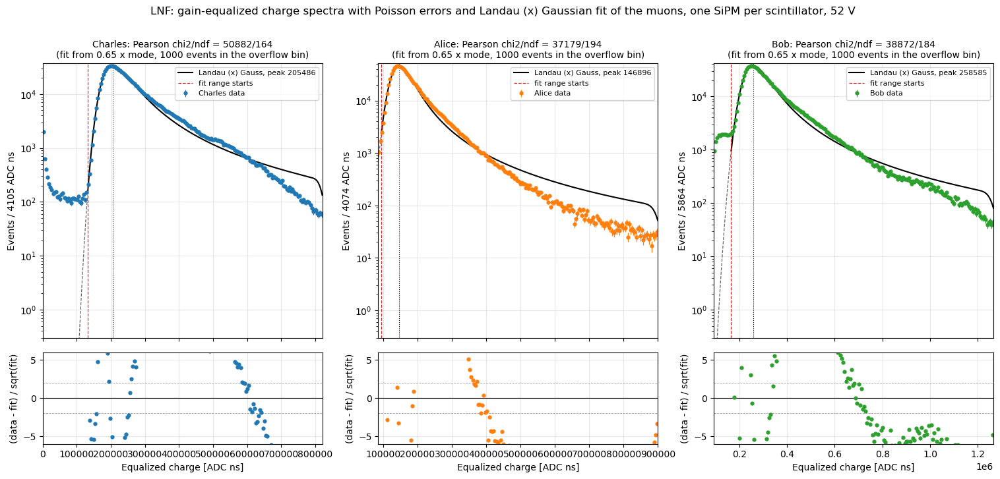

In [105]:
# === LNF: spettro di carica di ogni scintillatore con incertezze e fit Landau (x) gaussiana dei muoni ===
# COPIA della cella Yale, stesso calcolo, sui dati nuovi. Qui ogni scintillatore ha un SiPM diverso,
# a Yale lo stesso. I risultati stanno in FIT_LG_LNF, cosi' non si sovrascrivono quelli Yale.
#
# Quale spettro si fitta (FIT_SU_EQUALIZZATI):
#  - True: Q_SEGNALE_EQ della cella dell'equalizzazione, cioe' Q_SEGNALE / F con F = guadagno
#    (x PDE se USA_PDE_EQ). Tutti i pannelli stanno sulla scala del SiPM di riferimento e i picchi
#    si confrontano direttamente. Dividere per una costante cambia solo la scala orizzontale: la
#    forma del fit e la sua qualita' non cambiano, cambiano i numeri.
#  - False: Q_SEGNALE, il picco fisico di ogni pannello col suo SiPM.
# Per ogni pannello: istogramma di Q_SEGNALE (somma x dt, ADC ns, finestra lunga) disegnato come
# PUNTI con barre d'errore poissoniane sqrt(N) per bin, e fit del contributo dei MUONI:
#     f(Q) = A * [ Landau(MPV, xi) (x) Gauss(sigma) ](Q)
# Landau = perdita di energia del muone, gaussiana = tutto cio' che la allarga con una risposta
# gaussiana (statistica dei fotoelettroni, posizione lungo la fibra, guadagno). MPV e xi sono i
# parametri della Landau PRIMA della convoluzione; il picco della curva convoluta, quello da
# confrontare, si calcola numericamente.
#
# NON si fittano gli eventi a carica bassa: il piedistallo (eventi senza segnale, Q ~ 0) e gli
# eventi fra il piedistallo e il picco non sono muoni che attraversano lo scintillatore (luce
# parziale, impulsi fuori finestra) e nessuna Landau li descrive. Il fit parte da
# FRAZ_MIN_FIT x la moda dell'istogramma e prende TUTTO quello che sta sopra, coda compresa,
# overflow compreso (gli eventi oltre RANGE_PERC entrano in un bin aggiuntivo col numero di
# eventi atteso dal modello oltre il bordo). I bin sotto soglia restano disegnati, in grigio, e
# la curva li attraversa tratteggiata: e' un'estrapolazione, non un fit. La soglia si sceglie
# guardando dove finisce la componente di muoni; la cella stampa quanto cambia il picco
# spostandola (SCAN_FRAZ_MIN) e conviene che sia stabile.
#
# Fit di verosimiglianza di Poisson sui conteggi per bin (minimizza la devianza
# 2 * somma [mu - n + n ln(n/mu)]): vale anche per i bin con pochi eventi o vuoti, dove il
# chi-quadro con errori sqrt(N) non e' definito o e' distorto. Errori sui parametri dalla
# matrice hessiana della devianza. Bonta' del fit: devianza/ndf e chi-quadro di Pearson/ndf con
# ndf = bin nel fit (overflow compreso) - parametri; nel chi-quadro di Pearson il denominatore e'
# max(mu, 1) per non far esplodere i bin di coda con mu ~ 0. I residui sotto il grafico sono
# (n - mu) / sqrt(mu) (Pearson).
#
# La Landau e' calcolata qui, non con scipy.stats.landau (esiste solo da scipy 1.15):
#     phi(x) = 1/(2 pi i) * integrale di exp(x s + s ln s) ds  lungo Re(s) = c,
# con la regola dei trapezi sulla retta e c vicino al punto di sella. Controllata contro la
# formula 1/pi * integrale exp(-t ln t - x t) sin(pi t) dt (scarto < 1e-9) e contro
# scipy.stats.landau. La densita' standard si calcola una volta su una griglia e poi si
# interpola: il fit ne chiede decine di migliaia di valutazioni.
from scipy.optimize import minimize, minimize_scalar
from scipy.ndimage import gaussian_filter1d

FIT_SU_EQUALIZZATI = True       # True = fit su Q_SEGNALE_EQ (scala del SiPM di riferimento); False = su Q_SEGNALE
N_BIN_FIT = 200                 # bin dell'istogramma (esclusi underflow e overflow)
RANGE_PERC = (0.1, 99.9)        # l'istogramma copre questi percentili di Q; oltre, underflow e overflow
FRAZ_MIN_FIT = 0.65             # il fit parte da questa frazione della moda dell'istogramma
SCAN_FRAZ_MIN = [0.5, 0.6, 0.65, 0.7, 0.8]   # soglie provate per vedere quanto cambia il picco
LOG_Y_FIT = True
ORDINE_FIT = ["Charles", "Alice", "Bob"]
COLORI_FIT = {"Charles": "tab:blue", "Alice": "tab:orange", "Bob": "tab:green"}

_DY = 0.01
_Y = np.arange(0.0, 30.0, _DY)
_W = np.full_like(_Y, _DY); _W[0] = _DY / 2


def landau_std(x):
    """Densita' di Landau standard phi(x) (integrale 1, moda a -0.2228)."""
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.zeros_like(x)
    mid = (x > -6.0) & (x <= 100.0)
    xv = x[mid]
    c = np.clip(np.exp(-1.0 - xv), 0.05, 6.0)[:, None]
    s = c + 1j * _Y[None, :]
    out[mid] = np.maximum(((np.exp(xv[:, None] * s + s * np.log(s)).real) * _W[None, :]).sum(axis=1) / np.pi, 0.0)
    big = x > 100.0
    u = 1.0 / (x[big] - x[big] * np.log(x[big]) / (x[big] + 1.0))
    out[big] = u * u * (1.0 + (-1.845568670 - 4.284640743 * u) * u)
    return out


_LAMBDA0 = float(minimize_scalar(lambda v: -landau_std(v)[0], bounds=(-1.0, 1.0), method="bounded",
                                 options={"xatol": 1e-8}).x)      # moda della densita' standard (~ -0.2228)
_LGRID = np.arange(-6.0, 100.0, 0.01)
_LPHI = landau_std(_LGRID)                                         # una volta sola
_PHI_ALTO = lambda l: landau_std(l)                                # sopra 100 e' l'asintotica


def landau_interp(lam):
    lam = np.asarray(lam, dtype=float)
    out = np.interp(lam, _LGRID, _LPHI, left=0.0)
    alto = lam > _LGRID[-1]
    if alto.any():
        out[alto] = _PHI_ALTO(lam[alto])
    return out


def modello_bin(par, ctx):
    """Conteggi attesi dei muoni: [underflow, bin..., overflow]. par in unita' della moda: A, mpv, xi, sg."""
    A, mpv, xi, sg = par
    q = ctx["q_fine"]
    dens = landau_interp((q - mpv) / xi + _LAMBDA0) / xi
    h = ctx["h"]
    nk = int(np.ceil(6 * sg / h))                           # sg >= 0.01 (bound), h < 0.003
    k = np.arange(-nk, nk + 1) * h
    ker = np.exp(-0.5 * (k / sg) ** 2); ker /= ker.sum()
    conv = np.convolve(dens, ker, mode="same")
    lg = conv[ctx["i0"]:ctx["i1"]].reshape(ctx["nbin"], ctx["r"]).sum(axis=1) * h
    lg_sotto = conv[:ctx["i0"]].sum() * h                   # massa sotto il bordo basso dell'istogramma
    lg_sopra = max(1.0 - lg_sotto - lg.sum(), 0.0)          # il resto della densita' normalizzata e' sopra il bordo alto
    return A * np.concatenate([[lg_sotto], lg, [lg_sopra]])


def devianza(par, n, ctx, usati=None):
    """Devianza di Poisson sui soli bin `usati` (maschera su underflow, bin, overflow)."""
    mu = np.maximum(modello_bin(par, ctx), 1e-12)
    termine = np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / mu), 0.0)
    d = 2.0 * (mu - n + termine)
    return float(np.sum(d if usati is None else d[usati]))


def hessiana(f, x, passi):
    """Hessiana per differenze finite centrali."""
    n = len(x); H = np.zeros((n, n)); f0 = f(x); E = np.eye(n)
    for i in range(n):
        H[i, i] = (f(x + E[i] * passi[i]) - 2 * f0 + f(x - E[i] * passi[i])) / passi[i] ** 2
        for j in range(i + 1, n):
            H[i, j] = H[j, i] = (f(x + E[i] * passi[i] + E[j] * passi[j]) - f(x + E[i] * passi[i] - E[j] * passi[j])
                                 - f(x - E[i] * passi[i] + E[j] * passi[j]) + f(x - E[i] * passi[i] - E[j] * passi[j])) \
                                / (4 * passi[i] * passi[j])
    return H


_ch_di = {nome: ch for ch, nome in RIVELATORI.items()}
_pannelli = [n for n in ORDINE_FIT if n in _ch_di]


def fit_muoni(n, ctx, usati, N):
    """Fit di Landau (x) gaussiana sui bin `usati`. Ritorna (parametri fisici, errori, successo)."""
    # Parametri tutti di ordine 1 (l'ampiezza in frazione di N): con A ~ 1e4 contro 1 degli altri
    # il gradiente numerico non la muoverebbe.
    scala_par = np.array([N, 1, 1, 1], dtype=float)
    x0 = np.array([0.95, 1.0, 0.07, 0.05])
    lim = [(0, 2), (0.5, 1.5), (0.005, 0.5), (0.01, 0.5)]
    f_int = lambda xi: devianza(xi * scala_par, n, ctx, usati)
    ris = minimize(f_int, x0, method="L-BFGS-B", bounds=lim)
    for _ in range(3):                                         # altri giri dal minimo trovato
        ris = minimize(f_int, ris.x, method="L-BFGS-B", bounds=lim)
    ris_nm = minimize(f_int, ris.x, method="Nelder-Mead", options=dict(xatol=1e-7, fatol=1e-6, maxiter=4000))
    if ris_nm.fun < ris.fun:
        ris = ris_nm
    try:
        passi = np.maximum(1e-3 * np.abs(ris.x), 1e-3)
        cov_int = 2.0 * np.linalg.inv(hessiana(f_int, np.asarray(ris.x), passi))
        e_p = np.sqrt(np.where(np.diag(cov_int) > 0, np.diag(cov_int), np.nan)) * scala_par
    except np.linalg.LinAlgError:
        e_p = np.full(4, np.nan)
    return np.asarray(ris.x) * scala_par, e_p, ris


def curva_conv(p, ctx):
    """Landau (x) gaussiana sulla griglia fine (densita' per unita' scalata, integrale 1)."""
    dens = landau_interp((ctx["q_fine"] - p[1]) / p[2] + _LAMBDA0) / p[2]
    nk = int(np.ceil(6 * p[3] / ctx["h"])); kk = np.arange(-nk, nk + 1) * ctx["h"]
    ker = np.exp(-0.5 * (kk / p[3]) ** 2); ker /= ker.sum()
    return np.convolve(dens, ker, mode="same")


FIT_LG_LNF = {}
fig = plt.figure(figsize=(6.2 * len(_pannelli), 7.5))
gs = fig.add_gridspec(2, len(_pannelli), height_ratios=[3, 1], hspace=0.08)
print(f"LNF: fit sugli spettri {'EQUALIZZATI (' + ('guadagno x PDE' if USA_PDE_EQ else 'solo guadagno') + ')' if FIT_SU_EQUALIZZATI else 'NON equalizzati'}; "
      f"fit Landau (x) gaussiana dei muoni, Q >= {FRAZ_MIN_FIT:g} x moda dell'istogramma fino a fine spettro "
      f"(overflow compreso), verosimiglianza di Poisson")
for j, nome in enumerate(_pannelli):
    q = (Q_SEGNALE_EQ if FIT_SU_EQUALIZZATI else Q_SEGNALE)[_ch_di[nome]]
    N = len(q)
    lo, hi = (float(v) for v in np.percentile(q, RANGE_PERC))
    n_reg, bordi = np.histogram(q, bins=np.linspace(lo, hi, N_BIN_FIT + 1))
    n_sotto, n_sopra = int((q < lo).sum()), int((q > hi).sum())
    n = np.concatenate([[n_sotto], n_reg, [n_sopra]]).astype(float)   # underflow, bin, overflow
    bw = bordi[1] - bordi[0]
    c = 0.5 * (bordi[1:] + bordi[:-1])
    sel_moda = c > 0.25 * np.median(q)
    moda_h = c[sel_moda][int(np.argmax(gaussian_filter1d(n_reg.astype(float), 1)[sel_moda]))]
    sc = moda_h                                          # unita' interne: la moda dell'istogramma
    r = 6
    h = bw / r
    n_ext = int(np.ceil(0.5 * moda_h / h))
    n_tot = n_ext + N_BIN_FIT * r
    ctx = dict(h=h / sc, r=r, nbin=N_BIN_FIT, i0=n_ext, i1=n_ext + N_BIN_FIT * r,
               q_fine=((lo - n_ext * h) + (np.arange(n_tot) + 0.5) * h) / sc, bordi=bordi / sc)

    def maschera(frazione):
        """Bin nel fit: quelli col bordo basso sopra frazione*moda, piu' l'overflow. L'underflow no."""
        m = np.zeros(len(n), dtype=bool)
        m[1:-1] = bordi[:-1] >= frazione * moda_h
        m[-1] = True
        return m

    usati = maschera(FRAZ_MIN_FIT)
    p, e_p, ris = fit_muoni(n, ctx, usati, N)
    mu = modello_bin(p, ctx)
    dev = devianza(p, n, ctx, usati)
    pearson = float(np.sum(((n - mu) ** 2 / np.maximum(mu, 1.0))[usati]))
    ndf = int(usati.sum()) - len(p)
    conv = curva_conv(p, ctx)
    picco = float(ctx["q_fine"][np.argmax(conv)] * sc)
    sopra_meta = ctx["q_fine"][conv >= conv.max() / 2] * sc
    fwhm = float(sopra_meta[-1] - sopra_meta[0])
    n_fit = int(n[usati].sum())
    FIT_LG_LNF[nome] = dict(equalizzato=FIT_SU_EQUALIZZATI, parametri=p, errori=e_p, devianza=dev, pearson=pearson, ndf=ndf, picco=picco, fwhm=fwhm,
                        e_picco=float(e_p[1] * sc),      # errore dell'MPV, usato come errore del picco
                        sc=sc,
                        soglia_fit=FRAZ_MIN_FIT * moda_h, n_eventi_fit=n_fit)
    s_err = lambda k: f"{p[k] * sc:.0f} +- " + (f"{e_p[k] * sc:.0f}" if np.isfinite(e_p[k]) else "n.d.")
    print(f"  {nome:8s}: picco {picco:9.0f} ADC ns (moda istogramma {moda_h:.0f}), FWHM/picco {fwhm / picco:.2f}; "
          f"MPV {s_err(1)}, xi {s_err(2)}, sigma gauss {s_err(3)}\n"
          f"{'':10s}  fit sopra Q = {FRAZ_MIN_FIT * moda_h:.0f}: {n_fit} eventi su {N} ({n_sopra} nell'overflow, oltre {hi:.0f}); "
          f"devianza/ndf = {dev:.0f}/{ndf} = {dev / ndf:.2f}, Pearson chi2/ndf = {pearson:.0f}/{ndf} = {pearson / ndf:.2f}; "
          f"eventi di muoni stimati sull'intero spettro: {p[0]:.0f}")

    # stabilita' del picco rispetto alla soglia del fit
    riga = []
    for fr in SCAN_FRAZ_MIN:
        m_ = maschera(fr)
        p_, _, _ = fit_muoni(n, ctx, m_, N)
        cv = curva_conv(p_, ctx)
        riga.append(f"{fr:g}: {ctx['q_fine'][np.argmax(cv)] * sc:.0f}")
    print(f"{'':10s}  picco con soglia a  " + ",  ".join(riga) + "  (frazione della moda: picco)")

    ax = fig.add_subplot(gs[0, j])
    err = np.sqrt(np.maximum(n_reg, 1))
    nel = usati[1:-1]
    # Tutti i punti dello stesso colore, fittati o no: si vede dalla linea rossa dove parte il fit
    ax.errorbar(c, n_reg, yerr=err, fmt="o", ms=3.5, color=COLORI_FIT[nome], lw=0.9, label=f"{nome} data")
    qf = ctx["q_fine"] * sc
    curva = p[0] * conv / sc * bw                          # eventi per bin
    dentro = qf >= FRAZ_MIN_FIT * moda_h
    ax.plot(qf[dentro], curva[dentro], "k-", lw=1.5, label=f"Landau (x) Gauss, peak {picco:.0f}")
    ax.plot(qf[~dentro], curva[~dentro], "k--", lw=0.9, alpha=0.6)    # la curva a sinistra della soglia, dove non c'e' fit
    ax.axvline(picco, color="k", ls=":", lw=0.8)
    ax.axvline(FRAZ_MIN_FIT * moda_h, color="tab:red", ls="--", lw=0.9, label="fit range starts")
    ax.set_xlim(lo, hi)
    ax.set_ylim(top=1.12 * n_reg.max())
    if LOG_Y_FIT:
        ax.set_yscale("log"); ax.set_ylim(bottom=0.3)
    ax.set_ylabel(f"Events / {bw:.0f} ADC ns")
    ax.set_title(f"{nome}: Pearson chi2/ndf = {pearson:.0f}/{ndf}\n(fit from {FRAZ_MIN_FIT:g} x mode, {n_sopra} events in the overflow bin)", fontsize=10)
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8); ax.tick_params(labelbottom=False)

    axr = fig.add_subplot(gs[1, j], sharex=ax)
    pull = (n_reg - mu[1:-1]) / np.sqrt(np.maximum(mu[1:-1], 1.0))
    axr.axhline(0, color="k", lw=0.8)
    for y in (-2, 2):
        axr.axhline(y, color="0.6", ls="--", lw=0.6)
    axr.plot(c[nel], pull[nel], "o", ms=3.5, color=COLORI_FIT[nome])     # solo i bin fittati
    axr.set_ylim(-6, 6)
    axr.set_xlabel("Equalized charge [ADC ns]" if FIT_SU_EQUALIZZATI else "Charge in the pulse window [ADC ns]")
    axr.set_ylabel("(data - fit) / sqrt(fit)")
    axr.grid(True, alpha=0.3)
fig.suptitle(f"LNF: {'gain-equalized ' if FIT_SU_EQUALIZZATI else ''}charge spectra with Poisson errors and Landau (x) Gaussian fit of the muons, "
             f"one SiPM per scintillator, {VBIAS:g} V", y=0.995)
plt.tight_layout(); plt.show()


DELTA_E = 8.87 MeV (calcolata: 5 cm, muone da 4 GeV)
Picchi equalizzati (solo guadagno): Qpe_tot e crosstalk del SiPM di riferimento SiPM_003 per tutti i pannelli

 pannello      SiPM   Qpe_tot [ADC ns]  picco [ADC ns]   N pe misurati     Pct     N pe reali    LY [pe/MeV]
  Charles  SiPM_003        779.5 +- 11.8          205486     263.6 +-  4.0   0.034    272.8 +-  4.6     30.8 +-  0.5
    Alice  SiPM_003        779.5 +- 11.8          146896     188.5 +-  2.9   0.034    195.0 +-  3.3     22.0 +-  0.4
      Bob  SiPM_003        779.5 +- 11.8          258585     331.7 +-  5.0   0.034    343.3 +-  5.8     38.7 +-  0.6
(errori: picco = errore dell'MPV del fit, Qpe_tot dal fit lineare, Pct dal JSON; NON inclusi: l'errore su DELTA_E, e la mappa SiPM-pannello non verificata)


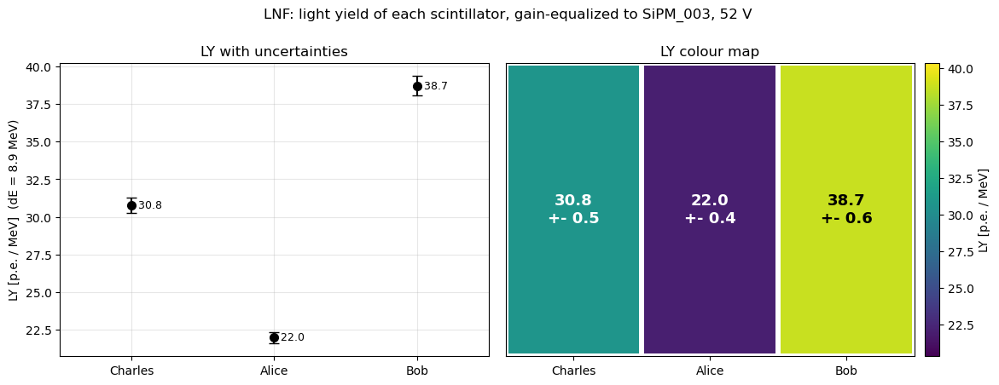

In [106]:
# === LNF: light yield di ogni scintillatore ===
# Stesso calcolo della cella Yale, sui dati nuovi, per ogni pannello:
#   N_pe misurati = picco / Qpe_tot                 fotoelettroni (celle accese) al picco
#   N_pe reali    = N_pe misurati / (1 - Pct)       con Pct = probabilita' di crosstalk (CT_DIVIDI = True)
#   LY            = N_pe reali / DELTA_E            fotoelettroni per MeV depositato al picco
# Differenza con Yale: qui ogni scintillatore ha il SUO SiPM (mappa SIPM_PANNELLO della cella
# dell'equalizzazione). Cosa si divide per cosa dipende da FIT_SU_EQUALIZZATI (cella del fit):
#  - False (picco fisico di ogni pannello): Qpe_tot e crosstalk del SiPM di quel pannello.
#    Misura i fotoelettroni davvero visti da quel SiPM.
#  - True (spettri equalizzati): il picco e' sulla scala del SiPM di RIFERIMENTO, quindi si usano
#    Qpe_tot e crosstalk del riferimento (SIPM_RIFERIMENTO) per tutti i pannelli. Il LY e' quello che
#    si leggerebbe con il SiPM di riferimento al posto del proprio: con solo il guadagno
#    (USA_PDE_EQ = False) coincide coi fotoelettroni misurati, con USA_PDE_EQ = True contiene
#    anche la correzione di PDE del datasheet (estrapolata sotto 2 V), cioe' non e' piu' una
#    misura diretta ma una misura riportata a PDE di riferimento, con la sua incertezza.
# - Picco: della Landau (x) gaussiana della cella precedente (ADC ns).
# - Qpe_tot: carica per fotoelettrone sull'intero impulso, col LED (notebook del guadagno),
#   dal fit lineare in V a V_EQ, in ADC ns: si legge dal JSON mv_panels_equalizzazione_sipm.json
#   scritto dalla cella dell'equalizzazione (quindi stessa unita' del picco).
# - Pct: crosstalk `lambda` del JSON del LED a 52 V (il punto singolo di per_run). Per SiPM_001 e
#   SiPM_002 a quella tensione vale 0.000 (segnato non affidabile quando e' cosi'): con una
#   sovratensione di 0.6 V il crosstalk e' piccolo e il fit non lo separa. Si puo' imporre con
#   PCT_OVERRIDE.
#   ATTENZIONE alla direzione: se il segnale misurato conta anche le celle del crosstalk, i
#   fotoelettroni primari sono MENO di quelli misurati (il notebook del guadagno scrive primari
#   ~ misurati x (1 - lambda)). Qui, come richiesto, si divide per (1 - Pct); con CT_DIVIDI = False
#   si moltiplica. La differenza e' ~2 Pct.
# - DELTA_E: energia attesa al picco, perdita di energia piu' probabile di un muone minimo in
#   SPESSORE_CM di scintillatore plastico (Landau-Vavilov, PDG), come nella cella Yale
#   (EJ-200: rho = 1.023 g/cm3, Z/A = 0.541, I = 64.7 eV). Vale per un muone verticale: a LNF i
#   pannelli sono uno sopra l'altro, con trigger sulla coincidenza di due pannelli adiacenti e
#   accettanza angolare larga; un muone inclinato attraversa x / cos(theta) e depone di piu',
#   quindi la ΔE vera al picco e' un po' maggiore e questo LY e' sovrastimato per lo stesso
#   motivo (non quantificato qui).
# - Trigger: il pannello sotto esame non e' nel trigger (CFD sugli altri due), gli altri due si': i
#   loro spettri sono tagliati in basso dalla soglia del CFD, il picco no (stabile entro il 4%
#   fra le run 0057, 0168, 0173).
import json

CT_DIVIDI = True                # True: N reali = N misurati / (1 - Pct); False: x (1 - Pct)
PCT_OVERRIDE = None             # es. {"Charles": 0.03}: crosstalk per pannello al posto di quello del JSON
SPESSORE_CM, RHO_G_CM3, Z_SU_A, I_EV, E_MU_GEV = 5.0, 1.023, 0.5408, 64.7, 4.0
DELTA_E_MEV = None              # None = calcolata qui


def mpv_perdita_energia(x_cm, rho, z_su_a, i_ev, e_mu_gev):
    """Perdita di energia piu' probabile [MeV] di un muone in x_cm di materiale (Landau-Vavilov, PDG)."""
    K, ME_EV, M_MU_MEV = 0.307075, 0.511e6, 105.658     # MeV cm2/mol, eV, MeV
    gam = e_mu_gev * 1000.0 / M_MU_MEV
    bg2 = gam ** 2 - 1.0
    b2 = bg2 / gam ** 2
    xi = 0.5 * K * z_su_a * rho * x_cm / b2             # MeV
    hw_p = 28.816 * np.sqrt(rho * z_su_a)               # energia di plasma [eV]
    delta = np.log(bg2) + 2.0 * np.log(hw_p / i_ev) - 1.0          # limite asintotico, 2 ln(bg) = ln(bg2)
    return xi * (np.log(2 * ME_EV * bg2 / i_ev) + np.log(xi * 1e6 / i_ev) + 0.200 - b2 - delta)


delta_e = DELTA_E_MEV if DELTA_E_MEV is not None else mpv_perdita_energia(SPESSORE_CM, RHO_G_CM3, Z_SU_A, I_EV, E_MU_GEV)
print(f"DELTA_E = {delta_e:.2f} MeV ({'imposta' if DELTA_E_MEV is not None else f'calcolata: {SPESSORE_CM:g} cm, muone da {E_MU_GEV:g} GeV'})")

nome_eq_ly = os.path.join(DIR_MISURE, "mv_panels_equalizzazione_sipm.json")
if not os.path.exists(nome_eq_ly):
    raise FileNotFoundError("manca mv_panels_equalizzazione_sipm.json: eseguire una volta la cella dell'equalizzazione dei SiPM")
with open(nome_eq_ly) as f_:
    eq_ly = json.load(f_)
if abs(eq_ly["tensione_V"] - VBIAS) > 1e-6:
    print(f"ATTENZIONE: Qpe_tot e crosstalk valgono a {eq_ly['tensione_V']:g} V, la run e' a {VBIAS:g} V")
_sipm_di_ly = {p: s_ for s_, p in SIPM_PANNELLO.items()}
if FIT_SU_EQUALIZZATI:
    print(f"Picchi equalizzati ({'guadagno x PDE' if USA_PDE_EQ else 'solo guadagno'}): Qpe_tot e crosstalk del SiPM di "
          f"riferimento {SIPM_RIFERIMENTO} per tutti i pannelli")
else:
    print("Picchi fisici: Qpe_tot e crosstalk del SiPM di ogni pannello")
_chiave_v = str(int(eq_ly["tensione_V"]))

LY_LNF = {}
print(f"\n{'pannello':>9} {'SiPM':>9} {'Qpe_tot [ADC ns]':>18} {'picco [ADC ns]':>15} {'N pe misurati':>15} {'Pct':>7} "
      f"{'N pe reali':>14} {'LY [pe/MeV]':>14}")
for nome in [n for n in ["Charles", "Alice", "Bob"] if n in FIT_LG_LNF]:
    sipm = SIPM_RIFERIMENTO if FIT_SU_EQUALIZZATI else _sipm_di_ly[nome]
    qpe_tot = eq_ly["sipm"][sipm]["q_pe_tot_adc_ns"]
    e_qpe_tot = eq_ly["sipm"][sipm]["e_q_pe_tot_adc_ns"]
    with open(os.path.join(DIR_MISURE, f"sipm_gain_led_{sipm}_{DATA_GAIN}.json")) as f_:
        pr_ly = json.load(f_)["per_run"][_chiave_v]
    if PCT_OVERRIDE and nome in PCT_OVERRIDE:
        pct, e_pct = PCT_OVERRIDE[nome], 0.0
    else:
        pct, e_pct = pr_ly["lambda"], pr_ly["e_lambda"]
    picco, e_picco = FIT_LG_LNF[nome]["picco"], FIT_LG_LNF[nome]["e_picco"]
    n_mis = picco / qpe_tot
    e_n_mis = n_mis * np.hypot(e_picco / picco, e_qpe_tot / qpe_tot)
    if CT_DIVIDI:
        n_reali = n_mis / (1.0 - pct)
    else:
        n_reali = n_mis * (1.0 - pct)
    e_n_reali = n_reali * np.hypot(e_n_mis / n_mis, e_pct / (1.0 - pct))
    ly = n_reali / delta_e
    e_ly = e_n_reali / delta_e                   # senza l'errore su DELTA_E (sistematico, non stimato)
    LY_LNF[nome] = dict(sipm=sipm, qpe_tot_adc_ns=qpe_tot, picco=picco, n_pe_misurati=n_mis, e_n_pe_misurati=e_n_mis,
                        pct=pct, n_pe_reali=n_reali, e_n_pe_reali=e_n_reali, delta_e_mev=delta_e,
                        ly_pe_per_mev=ly, e_ly=e_ly)
    print(f"{nome:>9} {sipm:>9} {qpe_tot:>12.1f} +- {e_qpe_tot:4.1f} {picco:>15.0f} {n_mis:>9.1f} +- {e_n_mis:4.1f} "
          f"{pct:>7.3f} {n_reali:>8.1f} +- {e_n_reali:4.1f} {ly:>8.1f} +- {e_ly:4.1f}")
print("(errori: picco = errore dell'MPV del fit, Qpe_tot dal fit lineare, Pct dal JSON; "
      "NON inclusi: l'errore su DELTA_E, e la mappa SiPM-pannello non verificata)")

# Due grafici affiancati: a sinistra LY con incertezze, a destra gli stessi valori come mappa di colore
# (un riquadro per scintillatore, nello stesso ordine; il colore e' il LY, scritto nel riquadro).
CMAP_LY = "viridis"
LY_RANGE = None                 # (min, max) della scala di colore; None = dai dati, con un po' di margine
nomi = list(LY_LNF)
valori = np.array([LY_LNF[n]["ly_pe_per_mev"] for n in nomi])
errori = np.array([LY_LNF[n]["e_ly"] for n in nomi])

fig, (ax, axm) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax.errorbar(range(len(nomi)), valori, yerr=errori, fmt="o", ms=7, capsize=4, color="k")
for k, v in enumerate(valori):
    ax.text(k, v, f"  {v:.1f}", va="center", ha="left", fontsize=9)
ax.set_xticks(range(len(nomi))); ax.set_xticklabels(nomi)
ax.set_xlim(-0.5, len(nomi) - 0.5)
ax.set_ylabel(f"LY [p.e. / MeV]  (dE = {delta_e:.1f} MeV)")
ax.set_title("LY with uncertainties")
ax.grid(True, alpha=0.3)

vmin, vmax = LY_RANGE if LY_RANGE is not None else (valori.min() - 0.1 * np.ptp(valori) - 1e-9, valori.max() + 0.1 * np.ptp(valori) + 1e-9)
im = axm.pcolormesh(np.arange(len(nomi) + 1), [0, 1], valori[None, :], cmap=CMAP_LY, vmin=vmin, vmax=vmax,
                    edgecolors="w", linewidth=3)
for k, (v, e) in enumerate(zip(valori, errori)):
    # testo chiaro sui colori scuri e scuro sui chiari
    chiaro = plt.get_cmap(CMAP_LY)((v - vmin) / (vmax - vmin))[:3]
    col = "k" if (0.299 * chiaro[0] + 0.587 * chiaro[1] + 0.114 * chiaro[2]) > 0.5 else "w"
    axm.text(k + 0.5, 0.5, f"{v:.1f}\n+- {e:.1f}", ha="center", va="center", fontsize=13, color=col, fontweight="bold")
axm.set_xticks(np.arange(len(nomi)) + 0.5); axm.set_xticklabels(nomi)
axm.set_yticks([])
axm.set_title("LY colour map")
cb = fig.colorbar(im, ax=axm, pad=0.02)
cb.set_label("LY [p.e. / MeV]")
fig.suptitle(f"LNF: light yield of each scintillator, " + (f"gain-equalized to {SIPM_RIFERIMENTO}" if FIT_SU_EQUALIZZATI
             else "one SiPM per scintillator") + f", {VBIAS:g} V", y=0.995)
plt.tight_layout(); plt.show()


In [ ]:
# === Eventi con Q fino a una soglia: waveform degli eventi selezionati ===
# Carica = quella nella finestra dell'impulso (Q_SEGNALE, cella della carica).
# Si guardano gli eventi con Q <= Q_MAX_EVENTI, per vedere che forma
# hanno. Per guardare una fascia, impostare anche Q_MIN_EVENTI; per la coda
# alta, invertire i due limiti (min = soglia, max = None).
Q_MIN_EVENTI = None       # [ADC ns]; None = nessun limite inferiore
# Un limite per rivelatore (gli spettri non partono dallo stesso valore); None = nessun limite
Q_MAX_EVENTI = {"Charles": 100000, "Alice": 60000, "Bob": 60000}
N_EVENTI_ALTA_Q = 12          # waveform mostrate per canale (a caso fra quelle selezionate)
SEED_ALTA_Q = 1

for ch in canali_q:
    q = Q_SEGNALE[ch]
    sel = np.ones(len(q), dtype=bool)
    if Q_MIN_EVENTI is not None:
        sel &= q >= Q_MIN_EVENTI
    q_max = Q_MAX_EVENTI.get(RIVELATORI[ch])
    if q_max is not None:
        sel &= q <= q_max
    idx = np.flatnonzero(sel)
    lim = " e ".join(([f">= {Q_MIN_EVENTI:g}"] if Q_MIN_EVENTI is not None else [])
                     + ([f"<= {q_max:g}"] if q_max is not None else []))
    print(f"[{DESCRIZIONE[ch]}] eventi con Q {lim}"
          + f": {len(idx)} su {len(q)} ({100 * len(idx) / len(q):.3f}%); Q massima {q.max():.0f} ADC ns")
    if len(idx) == 0:
        continue
    rng = np.random.default_rng(SEED_ALTA_Q)
    scelti = np.sort(rng.choice(idx, min(N_EVENTI_ALTA_Q, len(idx)), replace=False))

    ncol = 3
    nrow = int(np.ceil(len(scelti) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, scelti):
        ax.plot(t_q, wf_canali[ch][ev], lw=0.6, color="tab:gray", alpha=0.7, label="raw")
        ax.plot(t_q, wf_filt_canali[ch][ev], lw=0.9, color="k", label="filtered")
        ax.axvspan(*FINESTRA_CARICA_NS[ch], color="tab:green", alpha=0.15)
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]}), Q = {q[ev]:.0f}", fontsize=9)
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    axes.flat[0].legend(fontsize=8)
    for ax in axes.flat[len(scelti):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(f"{DESCRIZIONE[ch]} — {len(scelti)} of {len(idx)} events with selected Q (green: pulse window)")
    plt.tight_layout()
    plt.show()


In [37]:
# === PARAMETRI DELL'ANALISI: soglia e tagli sugli impulsi ===
# Cella da modificare per provare soglie e tagli diversi. Non legge nessun file:
# dopo averla cambiata si riesegue da QUESTA cella in poi (distribuzione delle
# ampiezze, efficienza, scan...), senza rileggere i dati. Vale SOLO per i dati
# nuovi: i dati Yale hanno la loro cella dei parametri (NSIGMA_YALE, ...), cosi' cambiare
# questi non tocca Yale e viceversa.

# Soglia di rivelazione di ogni canale: mu + NSIGMA_SOGLIA*sigma del fit gaussiano
# della distribuzione delle ampiezze senza segnale. Si disegna sul grafico di
# quella distribuzione e la usano le celle dell'efficienza.
NSIGMA_SOGLIA = 6

# Condizioni di impulso "valido". Un massimo sopra mu + N*sigma non basta: uno
# spike di rumore stretto, o un'oscillazione elettronica, lo supera senza essere
# un segnale. Valgono per TUTTI i canali, i due di riferimento (il trigger
# esterno) compresi, e anche nello scan in soglia. Tutte spente di serie: si
# fissano guardando la cella "Come scegliere i tagli", non a occhio.
#  - T_MIN_LARGHEZZA_NS: il segnale deve restare sopra soglia per almeno questo
#    tempo CONSECUTIVO [ns] (il tratto piu' lungo nella regione del segnale).
#    0 = nessun taglio.
#  - AMP_MAX_ADC: massimo ammesso nella regione del segnale [ADC]. Un evento
#    col massimo oltre non e' un impulso del rivelatore (rumore elettronico di
#    centinaia di ADC) e NON conta ne' come riferimento ne' come pannello sotto
#    esame. None = nessun limite.
#  - DT_COINC_MAX_NS: i due riferimenti devono avere il massimo entro questo
#    tempo uno dall'altro [ns]. Toglie le false coincidenze: uno spike su un
#    riferimento a un istante a caso con un impulso vero sull'altro.
#    None = nessun taglio. Solo dati nuovi: i file Yale hanno un pannello ciascuno.
T_MIN_LARGHEZZA_NS = 5.3
# Larghezza minima nello scan in soglia. La larghezza sopra soglia dipende dalla
# soglia (piu' e' alta, piu' sono stretti sia gli impulsi sia il rumore), quindi
# un T solo non vale per tutte le N. Con T_SCAN_PER_SOGLIA = True, nello scan
# ogni soglia mu + N*sigma usa il SUO T: il piu' piccolo per cui il rumore
# residuo, stimato nella finestra di baseline e riportato a tutta la regione del
# segnale, sta sotto RUMORE_RESIDUO_MAX. Con False lo scan usa T_MIN_LARGHEZZA_NS
# per tutte le N.
T_SCAN_PER_SOGLIA = True
RUMORE_RESIDUO_MAX = 0.01     # frazione di eventi in cui il solo rumore sarebbe "valido" (1%)
AMP_MAX_ADC = None
DT_COINC_MAX_NS = 34

# Carica positiva: un evento e' "sopra soglia" valido solo se la carica nella
# finestra dell'impulso (Q_SEGNALE) e' > 0. Vale per tutti i canali, riferimenti
# compresi, e anche nello scan. Un impulso vero ha carica positiva; carica <= 0
# con un massimo sopra soglia e' rumore (oscillazione, spike con undershoot).
RICHIEDI_Q_POSITIVA = True

print(f"NSIGMA_SOGLIA = {NSIGMA_SOGLIA}, T_MIN_LARGHEZZA_NS = {T_MIN_LARGHEZZA_NS}, "
      f"AMP_MAX_ADC = {AMP_MAX_ADC}, DT_COINC_MAX_NS = {DT_COINC_MAX_NS}, "
      f"T_SCAN_PER_SOGLIA = {T_SCAN_PER_SOGLIA}, RUMORE_RESIDUO_MAX = {RUMORE_RESIDUO_MAX}, "
      f"RICHIEDI_Q_POSITIVA = {RICHIEDI_Q_POSITIVA}")


def frazione_ge(x, valori):
    """Frazione degli elementi di x che sono >= ciascun valore."""
    xs = np.sort(x)
    return 1.0 - np.searchsorted(xs, valori, side="left") / len(xs)


NSIGMA_SOGLIA = 6, T_MIN_LARGHEZZA_NS = 5.3, AMP_MAX_ADC = None, DT_COINC_MAX_NS = 34, T_SCAN_PER_SOGLIA = True, RUMORE_RESIDUO_MAX = 0.01, RICHIEDI_Q_POSITIVA = True


In [ ]:
# === Distribuzione delle ampiezze nella finestra prima del segnale, su tutti gli eventi, con fit gaussiano ===
# Sulle WF FILTRATE (wf_filt_canali), sempre, indipendentemente da
# USA_FILTRATE: il filtro cambia molto la sigma -- su ch18 la riga a ~95 MHz
# da' ~15 ADC grezzi contro ~2.5 filtrati -- e le ampiezze dei vari run vanno
# confrontate tutte nello stesso modo.
# La baseline di ogni evento e' gia' tolta (cella della baseline). Se la
# finestra e' la stessa della baseline, ogni evento ha media zero per
# costruzione: la sigma e' il rumore DENTRO l'evento, senza lo spostamento
# della baseline da un evento all'altro.
FINESTRA_AMP_NS = BASELINE_NS

# Range dell'istogramma: esplicito, per la ragione scritta nell'originale (con
# il range automatico pochi campioni anomali lo allargano, i bin si svuotano e
# la covarianza di curve_fit degenera). Ma non fisso per tutti: si prende
# +-AMP_RANGE_NSIGMA sigma robuste (dalla MAD) attorno a zero, perche' la
# sigma cambia fra canali. AMP_RANGE = (-10, 10) lo impone fisso.
AMP_RANGE = None
AMP_RANGE_NSIGMA = 6
n_bins_amp = 100
N_EVENTI_STIMA = 50000       # eventi per stimare la larghezza; l'istogramma usa tutti gli eventi


def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))


t_amp = np.arange(N_SAMPLES) * SAMPLING_TIME
mask_t_amp = (t_amp >= FINESTRA_AMP_NS[0]) & (t_amp <= FINESTRA_AMP_NS[1])
print(f"Finestra [{FINESTRA_AMP_NS[0]:g}, {FINESTRA_AMP_NS[1]:g}] ns: {mask_t_amp.sum()} campioni per evento; "
      f"WF filtrate ({filtri}), baseline per evento sottratta")

fit_amp = {}                 # canale -> (mu, err_mu, sigma, err_sigma) [ADC]
for ch in wf_filt_canali:
    wf = wf_filt_canali[ch]

    if AMP_RANGE is not None:
        amp_range = AMP_RANGE
    else:
        stima = wf[:N_EVENTI_STIMA, mask_t_amp].astype(np.float64).ravel()
        sigma_mad = 1.4826 * np.median(np.abs(stima - np.median(stima)))
        del stima
        mezzo = max(AMP_RANGE_NSIGMA * sigma_mad, 5.0)
        amp_range = (-mezzo, mezzo)
    edges_amp = np.linspace(amp_range[0], amp_range[1], n_bins_amp + 1)
    centers_amp = 0.5 * (edges_amp[:-1] + edges_amp[1:])

    # Istogramma a blocchi: a run intera i campioni nella finestra sono ~2e8 per
    # canale, e appiattirli tutti in float64 vorrebbe GB. I blocchi sommano gli stessi conteggi.
    counts_amp = np.zeros(n_bins_amp)
    n_tot = n_fuori = 0
    for i0 in range(0, wf.shape[0], BLOCCO_EVENTI):
        v = wf[i0:i0 + BLOCCO_EVENTI, mask_t_amp].astype(np.float64).ravel()
        counts_amp += np.histogram(v, bins=edges_amp)[0]
        n_tot += v.size
        n_fuori += np.count_nonzero((v < edges_amp[0]) | (v > edges_amp[-1]))

    # p0 dai momenti dell'istogramma: e' l'equivalente di media e std dei valori nel range
    m1 = np.average(centers_amp, weights=counts_amp)
    m2 = np.average(centers_amp ** 2, weights=counts_amp)
    p0_amp = [counts_amp.max(), m1, np.sqrt(m2 - m1 ** 2)]
    popt_amp, pcov_amp = curve_fit(gauss, centers_amp, counts_amp, p0=p0_amp)
    A_amp_fit, mu_amp_fit, sigma_amp_fit = popt_amp
    sigma_amp_fit = abs(sigma_amp_fit)     # la gaussiana e' pari in sigma: il fit puo' darla negativa
    mu_amp_err, sigma_amp_err = np.sqrt(np.diag(pcov_amp))[1:]
    fit_amp[ch] = (mu_amp_fit, mu_amp_err, sigma_amp_fit, sigma_amp_err)

    print(f"[{DESCRIZIONE[ch]}] {n_tot} campioni ({100 * n_fuori / n_tot:.2f}% fuori dal range "
          f"{edges_amp[0]:.1f}, {edges_amp[-1]:.1f})")
    print(f"    Fit gaussiano: mu = {mu_amp_fit:.3f} +- {mu_amp_err:.3f} ADC   "
          f"sigma = {sigma_amp_fit:.3f} +- {sigma_amp_err:.3f} ADC")

    if not mostra(ch):
        continue
    plt.figure()
    plt.stairs(counts_amp, edges_amp, color='k', label='data')
    x_fit_amp = np.linspace(edges_amp[0], edges_amp[-1], 1000)
    plt.plot(x_fit_amp, gauss(x_fit_amp, *popt_amp), color='red', lw=1.5,
             label=f'fit gauss: mu={mu_amp_fit:.2f}+-{mu_amp_err:.2f}, sigma={sigma_amp_fit:.2f}+-{sigma_amp_err:.2f}')
    # soglia di rivelazione del canale (NSIGMA_SOGLIA e' nella cella di config)
    soglia_amp = mu_amp_fit + NSIGMA_SOGLIA * sigma_amp_fit
    plt.axvline(soglia_amp, color='green', ls='--', lw=1.5,
                label=f'threshold mu + {NSIGMA_SOGLIA} sigma = {soglia_amp:.2f} ADC')
    plt.xlabel('Amplitude - event baseline [ADC]')
    plt.ylabel('Counts')
    plt.xlim(edges_amp[0], edges_amp[-1])
    plt.title(f"{DESCRIZIONE[ch]} — filtered, window [{FINESTRA_AMP_NS[0]:g}, {FINESTRA_AMP_NS[1]:g}] ns, {wf.shape[0]} events")
    plt.legend(loc='upper right', fontsize='small')
    plt.tight_layout()
    plt.show()

In [ ]:
# === Selezione degli eventi: soglie mu + N*sigma, impulso valido, coincidenza dei riferimenti ===
# (L'efficienza vera e propria, con errori e grafico, e' nella cella prima del salvataggio.)
# Si contano gli eventi in cui gli altri due pannelli hanno il segnale sopra la
# propria soglia (il campione di riferimento, selezionato senza guardare il
# pannello sotto esame), e fra questi quelli in cui anche quello sotto esame e'
# sopra la sua. Il rapporto e' l'efficienza del pannello (PANNELLO, config).
# Soglia di ogni canale = mu + NSIGMA_SOGLIA*sigma del suo fit gaussiano
# (fit_amp, WF filtrate, baseline per evento sottratta). Sopra soglia vuol
# dire che il massimo nella finestra dell'impulso (quella dove si integra la
# carica, FINESTRA_CARICA_NS, per canale) la supera E che l'impulso e'
# valido: largo almeno T_MIN_LARGHEZZA_NS, con massimo non oltre AMP_MAX_ADC e
# carica nella finestra positiva (RICHIEDI_Q_POSITIVA)
# (cella dei parametri); i due riferimenti devono inoltre avere il massimo entro
# DT_COINC_MAX_NS (cella dei parametri). Spenti, il criterio e' il solo massimo sopra soglia.
CANALE_TEST = [ch for ch, nome in RIVELATORI.items() if nome == PANNELLO][0]
CANALI_RIF = [ch for ch in CANALI if ch != CANALE_TEST]
t_sig = np.arange(N_SAMPLES) * SAMPLING_TIME
# Finestra dell'impulso di ogni canale: la STESSA su cui si integra la carica
# (cella della carica). Fuori da questa finestra niente conta: ne' il massimo, ne'
# la larghezza, ne' l'istante del picco.
mask_finestra = {ch: (t_sig >= FINESTRA_CARICA_NS[ch][0]) & (t_sig <= FINESTRA_CARICA_NS[ch][1]) for ch in CANALI}

soglia_sig = {}              # canale -> soglia [ADC]
massimo_sig = {}             # canale -> massimo nel segnale per evento [ADC], riusato dallo scan in soglia
sopra = {}                   # canale -> bool per evento: impulso valido sopra soglia
larghezza_sig = {}           # canale -> tratto piu' lungo sopra soglia nel segnale per evento [ns]
t_picco_sig = {}             # canale -> istante del massimo nel segnale per evento [ns]
for ch in [CANALE_TEST] + CANALI_RIF:
    wf = wf_filt_canali[ch]
    mu_amp_fit, _, sigma_amp_fit, _ = fit_amp[ch]
    soglia_sig[ch] = mu_amp_fit + NSIGMA_SOGLIA * sigma_amp_fit
    # Massimo a blocchi: wf[:, mask].max() copierebbe la sezione di tutta la run (GB)
    massimo = np.empty(wf.shape[0], dtype=np.float32)
    t_picco = np.empty(wf.shape[0], dtype=np.float32)
    t_fin = t_sig[mask_finestra[ch]]
    for i0 in range(0, wf.shape[0], BLOCCO_EVENTI):
        blocco = wf[i0:i0 + BLOCCO_EVENTI, mask_finestra[ch]]
        i_max = blocco.argmax(axis=-1)
        massimo[i0:i0 + BLOCCO_EVENTI] = blocco[np.arange(len(blocco)), i_max]
        t_picco[i0:i0 + BLOCCO_EVENTI] = t_fin[i_max]
    massimo_sig[ch] = massimo
    t_picco_sig[ch] = t_picco
    larghezza_sig[ch] = larghezza_massima_ns(wf, soglia_sig[ch], mask_finestra[ch])
    sopra_max = massimo > soglia_sig[ch]
    sopra_larg = sopra_max & (larghezza_sig[ch] >= T_MIN_LARGHEZZA_NS)
    sopra_amp = sopra_larg & (massimo <= AMP_MAX_ADC) if AMP_MAX_ADC is not None else sopra_larg
    sopra[ch] = sopra_amp & (Q_SEGNALE[ch] > 0) if RICHIEDI_Q_POSITIVA else sopra_amp
    print(f"ch{ch} ({RIVELATORI[ch]}): soglia (mu + {NSIGMA_SOGLIA}*sigma) = {soglia_sig[ch]:.3f} ADC "
          f"(mu = {mu_amp_fit:.3f}, sigma = {sigma_amp_fit:.3f}), eventi su {len(massimo)}:")
    print(f"    massimo sopra soglia: {sopra_max.sum()};  "
          f"+ larghezza >= {T_MIN_LARGHEZZA_NS:g} ns: {sopra_larg.sum()};  "
          f"+ massimo <= {AMP_MAX_ADC} ADC: {sopra_amp.sum()};  "
          f"+ carica > 0 ({RICHIEDI_Q_POSITIVA}): {sopra[ch].sum()}  (valido)")

# Coincidenza in tempo dei riferimenti: il massimo dei due entro DT_COINC_MAX_NS.
# Dipende solo dagli istanti dei massimi, non dalla soglia: vale anche nello scan.
if DT_COINC_MAX_NS is None or len(CANALI_RIF) < 2:
    coinc_ok = np.ones(len(massimo), dtype=bool)
else:
    _tp = np.stack([t_picco_sig[ch] for ch in CANALI_RIF])
    coinc_ok = (_tp.max(axis=0) - _tp.min(axis=0)) <= DT_COINC_MAX_NS
    del _tp
    print(f"\nCoincidenza in tempo dei riferimenti (|Dt| <= {DT_COINC_MAX_NS:g} ns): {coinc_ok.sum()} eventi su {len(coinc_ok)}")
mask_rif = np.logical_and.reduce([sopra[ch] for ch in CANALI_RIF]) & coinc_ok
mask_tutti = mask_rif & sopra[CANALE_TEST]
n_rif = int(mask_rif.sum())
n_tutti = int(mask_tutti.sum())

nomi_rif = " & ".join(f"ch{c}" for c in CANALI_RIF)
print(f"\nEventi con {nomi_rif} sopra soglia e in coincidenza: {n_rif} su {len(mask_rif)}")
print(f"  di cui anche ch{CANALE_TEST} sopra soglia: {n_tutti}")


In [ ]:
# === Come scegliere i tagli: larghezza, ampiezza e coincidenza ===
# Questa cella NON cambia nessun risultato: misura e suggerisce i valori dei
# parametri della cella dei parametri (T_MIN_LARGHEZZA_NS, AMP_MAX_ADC, DT_COINC_MAX_NS).
# Per ogni parametro stampa: cosa misura, cosa leggere nel grafico, e un valore
# SUGGERITO. Il valore lo imposti tu nella cella dei parametri.
#
# Domanda di fondo: un evento "sopra soglia" e' un impulso vero o rumore?
#  1) LARGHEZZA (T_MIN_LARGHEZZA_NS): un impulso vero resta sopra soglia a lungo,
#     una fluttuazione di rumore solo per pochi ns. Per ogni T si confronta
#     quanti eventi hanno un tratto sopra soglia lungo almeno T in una zona SENZA
#     segnale (la finestra di baseline: li' ogni evento sopra soglia e' rumore)
#     e nella finestra dell'impulso. Si sceglie il T piu' piccolo che elimina
#     (quasi) tutto il rumore tenendo (quasi) tutto il segnale.
#  2) AMPIEZZA (AMP_MAX_ADC): eventi con un massimo enorme, isolato dagli altri,
#     non sono impulsi del rivelatore ma rumore elettronico.
#  3) COINCIDENZA (DT_COINC_MAX_NS): i due riferimenti devono avere l'impulso
#     nello stesso istante; uno spike su uno e un impulso vero sull'altro a tempi
#     diversi e' una falsa coincidenza.
#
# I grafici sono in inglese come gli altri, le spiegazioni stampate in italiano.

T_TABELLA = [0.4, 2, 4, 6, 8, 10, 15, 20, 30, 40]   # ns, solo per la tabella stampata

t_diag = np.arange(N_SAMPLES) * SAMPLING_TIME
mask_t_baseline = (t_diag >= BASELINE_NS[0]) & (t_diag <= BASELINE_NS[1])
n_camp_bl = int(mask_t_baseline.sum())
n_camp_sig = {ch: int(mask_finestra[ch].sum()) for ch in CANALI}   # campioni della finestra dell'impulso di ogni canale
T_GRIGLIA = np.arange(SAMPLING_TIME, 60.0, SAMPLING_TIME)


T_sugg, amp_sugg, amp_bulk = {}, {}, {}
for ch in [CANALE_TEST] + CANALI_RIF:
    nome = DESCRIZIONE[ch]
    larg_rumore = larghezza_massima_ns(wf_filt_canali[ch], soglia_sig[ch], mask_t_baseline)
    larg_sig = larghezza_sig[ch]
    campione = (mask_rif if ch == CANALE_TEST else np.ones(len(larg_sig), dtype=bool))
    print("=" * 100)
    print(f"{nome}: soglia mu + {NSIGMA_SOGLIA}*sigma = {soglia_sig[ch]:.2f} ADC")

    # ---- 1) larghezza ----
    p_bl = frazione_ge(larg_rumore, T_GRIGLIA)                      # rumore, nella finestra di baseline
    p_reg = 1 - (1 - p_bl) ** (n_camp_sig[ch] / n_camp_bl)              # stima per tutta la finestra dell'impulso
    p_sig = frazione_ge(larg_sig[campione], T_GRIGLIA)              # eventi nella finestra dell'impulso
    print(f"\n  1) LARGHEZZA -> T_MIN_LARGHEZZA_NS")
    print(f"     Frazione di eventi con un tratto sopra soglia lungo ALMENO T.")
    print(f"     'rumore' = finestra di baseline [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns, dove segnale non c'e' (tutti gli eventi sopra soglia sono falsi).")
    print(f"     'rumore, regione segnale' = stima per l'intera finestra dell'impulso ({n_camp_sig[ch]} campioni contro {n_camp_bl}): 1-(1-p)^({n_camp_sig[ch]}/{n_camp_bl}),")
    print(f"        assume campioni di rumore indipendenti, e' una stima.")
    print(f"     'segnale' = finestra dell'impulso, {"gli eventi con i due riferimenti validi" if ch == CANALE_TEST else "tutti gli eventi"}.")
    print(f"     {'T [ns]':>8} {'rumore (baseline)':>19} {'rumore, regione segnale':>25} {'segnale':>10}")
    for t_ in T_TABELLA:
        j = np.argmin(np.abs(T_GRIGLIA - t_))
        print(f"     {T_GRIGLIA[j]:>8.1f} {100 * p_bl[j]:>18.2f}% {100 * p_reg[j]:>24.2f}% {100 * p_sig[j]:>9.1f}%")
    ok = np.flatnonzero(p_reg <= RUMORE_RESIDUO_MAX)
    if len(ok):
        T_sugg[ch] = float(T_GRIGLIA[ok[0]])
        tenuto = p_sig[ok[0]] / p_sig[0] if p_sig[0] > 0 else np.nan
        print(f"     --> T suggerito per questo canale: {T_sugg[ch]:.1f} ns "
              f"(rumore residuo stimato {100 * p_reg[ok[0]]:.2f}% , segnale tenuto {100 * tenuto:.1f}% di quello a T = 1 campione)")
        if tenuto < 0.9:
            print("     !! il taglio toglie piu' del 10% del segnale: la separazione rumore/segnale e' poco netta a questa soglia")
    else:
        T_sugg[ch] = None
        print(f"     --> nessun T fino a {T_GRIGLIA[-1]:.0f} ns porta il rumore stimato sotto {100 * RUMORE_RESIDUO_MAX:g}%")

    # ---- 2) ampiezza ----
    m = massimo_sig[ch]
    sopra_m = np.flatnonzero(m > soglia_sig[ch])
    top = sopra_m[np.argsort(m[sopra_m])[::-1][:10]]
    a = m[top]
    print(f"\n  2) AMPIEZZA -> AMP_MAX_ADC")
    print(f"     Massimo nella finestra dell'impulso degli eventi sopra soglia ({len(sopra_m)} eventi): "
          f"mediana {np.median(m[sopra_m]):.0f}, 99% {np.percentile(m[sopra_m], 99):.0f}, 99.9% {np.percentile(m[sopra_m], 99.9):.0f}, max {m[sopra_m].max():.0f} ADC")
    print(f"     I 10 eventi col massimo piu' alto (se uno e' molto piu' in alto degli altri e' sospetto):")
    for ev, v in zip(top, a):
        print(f"        evento {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]}): massimo {v:.0f} ADC, tratto sopra soglia {larg_sig[ev]:.1f} ns")
    rapporti = a[:-1] / a[1:]
    salto = np.flatnonzero(rapporti >= 2)
    if len(salto):
        i_ = salto[0]
        amp_sugg[ch] = float(np.sqrt(a[i_] * a[i_ + 1]))
        amp_bulk[ch] = float(a[i_ + 1])
        print(f"     --> fra i 10 piu' alti c'e' un salto di un fattore >= 2: {a[i_]:.0f} ADC contro {a[i_ + 1]:.0f} ADC dell'evento dopo. "
              f"Gli eventi sopra il salto sono {i_ + 1}. AMP_MAX_ADC suggerito: {amp_sugg[ch]:.0f} ADC (taglia quei {i_ + 1})")
    else:
        amp_sugg[ch] = None
        amp_bulk[ch] = float(a[0]) if len(a) else 0.0
        print("     --> nessun evento isolato fra i primi 10 (nessun salto di un fattore 2): AMP_MAX_ADC non sembra servire per questo canale")

# ---- 3) coincidenza in tempo dei riferimenti ----
DT_sugg = None
if len(CANALI_RIF) == 2:
    c1, c2 = CANALI_RIF
    entrambi = sopra[c1] & sopra[c2]
    dt_rif = t_picco_sig[c1][entrambi] - t_picco_sig[c2][entrambi]
    centro = float(np.median(dt_rif))
    sigma_dt = 1.4826 * float(np.median(np.abs(dt_rif - centro)))
    DT_sugg = float(np.ceil(abs(centro) + 5 * sigma_dt))   # il taglio e' |Dt| <= DT attorno a 0: se il picco e' spostato va incluso
    print("=" * 100)
    print(f"  3) COINCIDENZA -> DT_COINC_MAX_NS")
    print(f"     Per gli eventi con ENTRAMBI i riferimenti ch{c1} e ch{c2} sopra soglia ({entrambi.sum()}): differenza fra gli istanti dei loro massimi.")
    print(f"     Impulsi veri dello stesso passaggio: Dt in un picco stretto. Rumore su un riferimento: Dt a caso, fondo piatto.")
    print(f"     Picco: centro {centro:.1f} ns, larghezza (sigma robusta dalla MAD) {sigma_dt:.1f} ns")
    print(f"     Il taglio tiene gli eventi con |Dt| <= DT_COINC_MAX_NS, attorno a Dt = 0 (non attorno al centro del picco).")
    for w in (5, 10, 20, 50, 100):
        print(f"        |Dt| <= {w:>3} ns: {100 * np.mean(np.abs(dt_rif) <= w):.2f}% degli eventi")
    print(f"     --> DT_COINC_MAX_NS suggerito: {DT_sugg:.0f} ns (|centro| + 5 sigma del picco: lo tiene tutto)")

# ---- Riepilogo ----
print("=" * 100)
print("RIEPILOGO: valori suggeriti da impostare nella cella dei parametri")
t_vals = [v for v in T_sugg.values() if v is not None]
print(f"  T_MIN_LARGHEZZA_NS = {max(t_vals):.1f}   (il piu' grande fra i canali: {T_sugg}; ora impostato: {T_MIN_LARGHEZZA_NS:g})"
      if t_vals else "  T_MIN_LARGHEZZA_NS: nessun valore suggerito")
con_outlier = {c: v for c, v in amp_sugg.items() if v is not None}
if con_outlier:
    a_min = min(con_outlier.values())
    print(f"  AMP_MAX_ADC = {a_min:.0f}   (ora impostato: {AMP_MAX_ADC})")
    for c, bulk in amp_bulk.items():
        if bulk >= a_min:
            print(f"  !! ch{c} ha eventi normali fino a {bulk:.0f} ADC, sopra questo limite: AMP_MAX e' uno solo per tutti i canali, controllare")
else:
    print(f"  AMP_MAX_ADC: nessun evento isolato fuori scala trovato (ora impostato: {AMP_MAX_ADC})")
print(f"  DT_COINC_MAX_NS = {DT_sugg:.0f}   (ora impostato: {DT_COINC_MAX_NS})" if DT_sugg is not None else "  DT_COINC_MAX_NS: serve con due riferimenti")

# ---- Grafici ----
canali_diag = [ch for ch in [CANALE_TEST] + CANALI_RIF if mostra(ch)]
if canali_diag:
    fig, assi = plt.subplots(2, len(canali_diag), figsize=(6 * len(canali_diag), 8.5), squeeze=False)
    fig.suptitle("Top row: how long a stretch above threshold must last (sets T_MIN_LARGHEZZA_NS). "
                 "Bottom row: largest amplitudes (sets AMP_MAX_ADC)", fontsize=10)
    for col, ch in enumerate(canali_diag):
        ax = assi[0, col]
        larg_rumore = larghezza_massima_ns(wf_filt_canali[ch], soglia_sig[ch], mask_t_baseline)
        campione = (mask_rif if ch == CANALE_TEST else np.ones(len(larg_sig), dtype=bool))
        p_bl = frazione_ge(larg_rumore, T_GRIGLIA)
        p_reg = 1 - (1 - p_bl) ** (n_camp_sig[ch] / n_camp_bl)
        p_sig = frazione_ge(larghezza_sig[ch][campione], T_GRIGLIA)
        ax.plot(T_GRIGLIA, 100 * p_sig, color="k", label="pulse window (real pulses + noise)")
        ax.plot(T_GRIGLIA, 100 * p_reg, color="tab:green", label="noise only, scaled to the pulse window (estimate)")
        ax.plot(T_GRIGLIA, 100 * p_bl, color="tab:green", ls=":", label="noise only, baseline window (measured)")
        if T_sugg.get(ch) is not None:
            ax.axvline(T_sugg[ch], color="tab:blue", ls="--", label=f"suggested T = {T_sugg[ch]:.1f} ns")
        if T_MIN_LARGHEZZA_NS > 0:
            ax.axvline(T_MIN_LARGHEZZA_NS, color="tab:red", ls="-", lw=1, label=f"current T = {T_MIN_LARGHEZZA_NS:g} ns")
        ax.set_xlabel("T: minimum time above threshold [ns]")
        ax.set_ylabel("% of events lasting at least T")
        ax.set_title(f"{DESCRIZIONE[ch]}\nchoose T where the green curve is ~0 and the black one is still high", fontsize=9)
        ax.set_ylim(-3, 103); ax.grid(True, alpha=0.3); ax.legend(fontsize=7)

        ax = assi[1, col]
        m = massimo_sig[ch]
        s_ = m > soglia_sig[ch]
        ax.hist(m[s_], bins=np.logspace(np.log10(soglia_sig[ch]), np.log10(max(m.max(), 2 * soglia_sig[ch])), 150),
                histtype="step", color="k", label="events above threshold")
        if amp_sugg.get(ch) is not None:
            ax.axvline(amp_sugg[ch], color="tab:blue", ls="--", label=f"suggested AMP_MAX = {amp_sugg[ch]:.0f} ADC")
        if AMP_MAX_ADC is not None:
            ax.axvline(AMP_MAX_ADC, color="tab:red", lw=1, label=f"current AMP_MAX = {AMP_MAX_ADC:g} ADC")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("Maximum in the pulse window [ADC]"); ax.set_ylabel("Events")
        ax.set_title("isolated points far to the right of the bulk = electronic noise", fontsize=9)
        ax.grid(True, alpha=0.3, which="both"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

if len(CANALI_RIF) == 2:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
    fig.suptitle("Peak-time difference of the two reference panels (sets DT_COINC_MAX_NS). "
                 "A narrow peak = real coincidences; the flat floor = chance coincidences", fontsize=10)
    for ax_, lim in zip(axs, (None, 100)):
        r = (dt_rif.min(), dt_rif.max()) if lim is None else (centro - lim, centro + lim)
        ax_.hist(dt_rif, bins=200, range=r, histtype="step", color="k")
        ax_.axvspan(-DT_sugg, DT_sugg, color="tab:blue", alpha=0.15,
                    label=f"suggested window |Dt| <= {DT_sugg:.0f} ns")
        if DT_COINC_MAX_NS is not None:
            ax_.axvline(-DT_COINC_MAX_NS, color="tab:red", lw=1, label=f"current |Dt| <= {DT_COINC_MAX_NS:g} ns")
            ax_.axvline(DT_COINC_MAX_NS, color="tab:red", lw=1)
        ax_.set_yscale("log")
        ax_.set_xlabel(f"t_peak(ch{c1}) - t_peak(ch{c2}) [ns]"); ax_.set_ylabel("Events")
        ax_.set_title("whole range" if lim is None else "zoom around the peak")
        ax_.grid(True, alpha=0.3); ax_.legend(fontsize=8)
    plt.tight_layout(); plt.show()


In [ ]:
# === Distribuzioni di Q: tutti gli eventi e eventi che entrano nell'efficienza ===
# Carica nella finestra dell'impulso (Q_SEGNALE), un pannello per rivelatore:
#  - nero: tutti gli eventi;
#  - blu: eventi con i due pannelli di riferimento sopra soglia (mask_rif), cioe'
#    il campione che fa da denominatore dell'efficienza. Per i pannelli di
#    riferimento e' il campione richiesto "B & C sopra soglia";
#  - rosso (solo pannello sotto esame): eventi in cui, oltre ai riferimenti,
#    anche il pannello sotto esame e' sopra soglia (mask_tutti), il numeratore.
# Sono tutte cariche sulla WF filtrata a baseline per evento sottratta, come
# nella cella della carica; le soglie sono quelle di questa cella.
canali_eff = [ch for ch in [CANALE_TEST] + CANALI_RIF if mostra(ch)]
if canali_eff:
    fig, assi = plt.subplots(1, len(canali_eff), figsize=(6 * len(canali_eff), 4.5), squeeze=False)
    for ax, ch in zip(assi[0], canali_eff):
        q = Q_SEGNALE[ch]
        lo, hi = np.percentile(q, (0.05, 99.95))
        bins = np.linspace(lo, hi, 200)
        ax.hist(q, bins=bins, histtype="step", color="k", label=f"all events ({len(q)})")
        ax.hist(q[mask_rif], bins=bins, histtype="step", color="tab:blue",
                label=f"{nomi_rif} above threshold ({n_rif})")
        if ch == CANALE_TEST:
            ax.hist(q[mask_tutti], bins=bins, histtype="step", color="tab:red",
                    label=f"{nomi_rif} and ch{CANALE_TEST} above threshold ({n_tutti})")
        ax.set_yscale("log")
        ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
        ax.set_title(DESCRIZIONE[ch] + (" — panel under test" if ch == CANALE_TEST else " — reference"))
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


In [ ]:
# === Scan in soglia: efficienza del pannello sotto esame in funzione di N in mu + N*sigma ===
# Stessa selezione della cella precedente, con soglia mu + N*sigma (fit_amp) e
# N fra SCAN_NSIGMA. Due versioni:
#  (a) la soglia N*sigma su TUTTI i canali, riferimento compreso: e' la domanda
#      "cosa cambia se alzo la soglia di rivelazione";
#  (b) soglia N*sigma solo sul pannello sotto esame, riferimento fisso a
#      NSIGMA_SOGLIA: separa l'effetto sul campione di riferimento da quello
#      sul pannello.
# Il massimo di ogni evento e' gia' calcolato (massimo_sig). Le condizioni
# di impulso valido (cella dei parametri) valgono anche qui. La larghezza
# dipende dalla soglia, quindi per ogni N e canale si rilegge la WF e, con
# T_SCAN_PER_SOGLIA, ogni soglia ha il suo T (vedi la cella dei parametri);
# l'ampiezza massima e la coincidenza in tempo non dipendono dalla soglia.
# Per giustificare la soglia si stampa, per ogni N, anche quanto rumore ci si
# aspetta nel numeratore: vedi "Giustificazione della soglia" sotto la tabella.
from scipy.stats import beta

SCAN_NSIGMA = [3, 4, 5, 6, 7]

alfa = 1 - 0.682689          # copertura di +-1 sigma


def eff_binomiale(n, n_rif):
    """(efficienza, errore binomiale, CP basso, CP alto) con n successi su n_rif.

    Il binomiale va a zero quando l'efficienza e' vicina a 1, e li' sottostima:
    a fianco l'intervallo di Clopper-Pearson.
    """
    eff = n / n_rif
    err = np.sqrt(eff * (1 - eff) / n_rif)
    lo = beta.ppf(alfa / 2, n, n_rif - n + 1) if n > 0 else 0.0
    hi = beta.ppf(1 - alfa / 2, n + 1, n_rif - n) if n < n_rif else 1.0
    return eff, err, lo, hi


mask_bl_scan = (t_sig >= BASELINE_NS[0]) & (t_sig <= BASELINE_NS[1])
n_camp_bl_scan = int(mask_bl_scan.sum())
n_camp_sig_scan = {ch: int(mask_finestra[ch].sum()) for ch in CANALI}   # campioni della finestra dell'impulso di ogni canale
T_GRIGLIA_SCAN = np.arange(SAMPLING_TIME, 60.0, SAMPLING_TIME)

_larghezza_a = {}            # (canale, N) -> tratto piu' lungo sopra mu + N*sigma nel segnale [ns]
_rumore_a = {}               # (canale, N) -> idem nella finestra di baseline (solo rumore) [ns]
_t_a = {}                    # (canale, N) -> (T usato [ns], P(rumore valido) per evento nella regione del segnale)


def larghezza_a(ch, n_sigma):
    if (ch, n_sigma) not in _larghezza_a:
        mu, _, sigma, _ = fit_amp[ch]
        _larghezza_a[(ch, n_sigma)] = larghezza_massima_ns(wf_filt_canali[ch], mu + n_sigma * sigma, mask_finestra[ch])
    return _larghezza_a[(ch, n_sigma)]


def t_e_rumore_a(ch, n_sigma):
    """(T [ns], probabilita' che il solo rumore dia un impulso valido in un evento) alla soglia N.

    La probabilita' e' misurata nella finestra di baseline (nessun segnale) e
    riportata alla finestra dell'impulso, piu' lunga: 1-(1-p)^(n_sig/n_bl), che
    assume campioni di rumore indipendenti. E' una stima.
    T e' il piu' piccolo con probabilita' <= RUMORE_RESIDUO_MAX (T_SCAN_PER_SOGLIA),
    oppure T_MIN_LARGHEZZA_NS.
    """
    if (ch, n_sigma) not in _t_a:
        mu, _, sigma, _ = fit_amp[ch]
        if (ch, n_sigma) not in _rumore_a:
            _rumore_a[(ch, n_sigma)] = larghezza_massima_ns(wf_filt_canali[ch], mu + n_sigma * sigma, mask_bl_scan)
        larg_r = _rumore_a[(ch, n_sigma)]
        p_reg = 1 - (1 - frazione_ge(larg_r, T_GRIGLIA_SCAN)) ** (n_camp_sig_scan[ch] / n_camp_bl_scan)
        if T_SCAN_PER_SOGLIA:
            ok = np.flatnonzero(p_reg <= RUMORE_RESIDUO_MAX)
            if len(ok):
                j = ok[0]
            else:
                j = len(T_GRIGLIA_SCAN) - 1
                print(f"ATTENZIONE ch{ch}, N = {n_sigma}: nessun T fino a {T_GRIGLIA_SCAN[-1]:.0f} ns porta il rumore sotto "
                      f"{100 * RUMORE_RESIDUO_MAX:g}%: uso {T_GRIGLIA_SCAN[-1]:.0f} ns")
            _t_a[(ch, n_sigma)] = (float(T_GRIGLIA_SCAN[j]), float(p_reg[j]))
        else:
            t_ = max(T_MIN_LARGHEZZA_NS, SAMPLING_TIME)
            _t_a[(ch, n_sigma)] = (float(T_MIN_LARGHEZZA_NS),
                                   float(1 - (1 - frazione_ge(larg_r, [t_])[0]) ** (n_camp_sig_scan[ch] / n_camp_bl_scan)))
    return _t_a[(ch, n_sigma)]


def sopra_a(ch, n_sigma):
    mu, _, sigma, _ = fit_amp[ch]
    s = massimo_sig[ch] > mu + n_sigma * sigma
    t_min = t_e_rumore_a(ch, n_sigma)[0]
    if t_min > 0:
        s &= larghezza_a(ch, n_sigma) >= t_min
    if AMP_MAX_ADC is not None:
        s &= massimo_sig[ch] <= AMP_MAX_ADC
    if RICHIEDI_Q_POSITIVA:
        s &= Q_SEGNALE[ch] > 0
    return s


rif_fisso = np.logical_and.reduce([sopra_a(c, NSIGMA_SOGLIA) for c in CANALI_RIF]) & coinc_ok
SCAN_EFF = []
print(f"Pannello sotto esame: {PANNELLO} (ch{CANALE_TEST}), riferimento: " + " & ".join(f"ch{c}" for c in CANALI_RIF))
print(f"{'N sigma':>7} {'soglia [ADC]':>13} | {'(a) N rif.':>10} {'N sopra':>9} {'efficienza':>20} {'CP 68%':>20} | {'(b) N rif.':>10} {'efficienza':>20}")
for n_sigma in SCAN_NSIGMA:
    rif_a = np.logical_and.reduce([sopra_a(c, n_sigma) for c in CANALI_RIF]) & coinc_ok
    test_a = sopra_a(CANALE_TEST, n_sigma)
    n_rif_a, n_a = int(rif_a.sum()), int((rif_a & test_a).sum())
    ea, era, lo_a, hi_a = eff_binomiale(n_a, n_rif_a)
    n_rif_b, n_b = int(rif_fisso.sum()), int((rif_fisso & test_a).sum())
    eb, erb, lo_b, hi_b = eff_binomiale(n_b, n_rif_b)
    mu_t, _, sigma_t, _ = fit_amp[CANALE_TEST]
    t_test, p_rum_test = t_e_rumore_a(CANALE_TEST, n_sigma)
    # Se i riferimenti sono veri, i falsi nel numeratore sono gli eventi in cui il solo
    # rumore del pannello sotto esame darebbe un impulso valido: p_rum * n_rif
    falsi_b = p_rum_test * n_rif_b
    SCAN_EFF.append(dict(n_sigma=n_sigma, soglia_adc=mu_t + n_sigma * sigma_t,
                         t_min_test_ns=t_test, p_rumore_test=p_rum_test,
                         t_min_rif_ns={str(c): t_e_rumore_a(c, NSIGMA_SOGLIA)[0] for c in CANALI_RIF},
                         falsi_attesi_b=falsi_b, frazione_falsi_b=falsi_b / n_b if n_b > 0 else None,
                         a=dict(eff=ea, err=era, cp_lo=lo_a, cp_hi=hi_a, n_rif=n_rif_a, n_sopra=n_a),
                         b=dict(eff=eb, err=erb, cp_lo=lo_b, cp_hi=hi_b, n_rif=n_rif_b, n_sopra=n_b)))
    print(f"{n_sigma:>7} {mu_t + n_sigma * sigma_t:>13.2f} | {n_rif_a:>10} {n_a:>9} {ea:>13.5f} +- {era:.5f} "
          f"[{lo_a:.5f}, {hi_a:.5f}] | {n_rif_b:>10} {eb:>13.5f} +- {erb:.5f}")

print(f"\nGiustificazione della soglia ({PANNELLO}, versione (b): riferimenti a {NSIGMA_SOGLIA} sigma, soglia N sigma sul solo pannello sotto esame)")
print("  T = larghezza minima usata a quella soglia" + (" (scelta per ogni N)" if T_SCAN_PER_SOGLIA else " (fissa)"))
print("  P(rumore) = probabilita' stimata che il solo rumore dia un impulso valido in un evento")
print("  falsi attesi = P(rumore) x N riferimenti: eventi del numeratore che sarebbero rumore, se i riferimenti sono veri")
print(f"{'N sigma':>7} {'T [ns]':>8} {'P(rumore)':>12} {'N sopra':>9} {'falsi attesi':>13} {'falsi / N sopra':>16} {'efficienza':>11}")
for r in SCAN_EFF:
    fr = r["frazione_falsi_b"]
    print(f"{r['n_sigma']:>7} {r['t_min_test_ns']:>8.1f} {r['p_rumore_test']:>12.2e} {r['b']['n_sopra']:>9} "
          f"{r['falsi_attesi_b']:>13.2f} {(f'{100 * fr:.3f}%' if fr is not None else '-'):>16} {r['b']['eff']:>11.5f}")

n_s = [r["n_sigma"] for r in SCAN_EFF]
fig, (ax, ax_r) = plt.subplots(1, 2, figsize=(13, 4.5))
# ax.errorbar(n_s, [100 * r["a"]["eff"] for r in SCAN_EFF], yerr=[100 * r["a"]["err"] for r in SCAN_EFF],
            # fmt="o-", capsize=4, color="k", label="(a) threshold N sigma on all channels")
ax.errorbar(n_s, [100 * r["b"]["eff"] for r in SCAN_EFF], yerr=[100 * r["b"]["err"] for r in SCAN_EFF],
            fmt="s--", capsize=4, color="tab:blue", mfc="white",
            label=f"(b) N sigma on {PANNELLO} only, reference at {NSIGMA_SOGLIA} sigma")
ax.set_xticks(n_s)
ax.set_xlabel("Threshold: N in mu + N sigma")
ax.set_ylabel(f"{PANNELLO} efficiency [%]")
ax.set_title(f"{PANNELLO} (ch{CANALE_TEST}) — threshold scan, {N_EVENTI} events")
ax.set_ylim(99,100)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

# Probabilita' di rumore per evento: zero vuol dire "meno di uno su N_EVENTI": limite superiore
p_r = np.array([r["p_rumore_test"] for r in SCAN_EFF])
ul = p_r <= 0
p_plot = np.where(ul, n_camp_sig_scan[CANALE_TEST] / n_camp_bl_scan / N_EVENTI, p_r)
ax_r.plot(n_s, p_plot, "o-", color="tab:green")
ax_r.plot(np.array(n_s)[ul], p_plot[ul], "v", color="tab:green", ms=10, label="upper limit (0 noise events seen)")
ax_r.axhline(RUMORE_RESIDUO_MAX, color="tab:gray", ls="--", lw=1, label=f"RUMORE_RESIDUO_MAX = {RUMORE_RESIDUO_MAX:g}")
ax_r.set_yscale("log"); ax_r.set_xticks(n_s)
ax_r.set_xlabel("Threshold: N in mu + N sigma")
ax_r.set_ylabel("P(noise alone gives a valid pulse) per event")
ax_r.set_title(f"{PANNELLO} — noise contamination vs threshold\n(at each N, with that N's T)", fontsize=9)
ax_r.grid(True, alpha=0.3, which="both"); ax_r.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# === Waveform filtrate degli eventi con Q <= soglia, con le soglie mu + N*sigma ===
# Solo WF filtrate (baseline per evento sottratta), un grafico per rivelatore.
# Q e' la carica nella finestra dell'impulso (Q_SEGNALE), selezione inclusiva.
# Le soglie sono quelle della cella dello scan: mu + N*sigma dal fit gaussiano
# delle ampiezze nella finestra di baseline (fit_amp) del canale, per N in
# SCAN_NSIGMA; quella di lavoro (NSIGMA_SOGLIA) e' tratteggiata piu' marcata.
# Limite di Q [ADC ns], incluso, UNO PER RIVELATORE: gli spettri di carica dei
# rivelatori non partono dallo stesso valore (Alice e Bob da ~50000), e con un
# limite solo uno dei tre non avrebbe nessun evento. Valori di partenza: Charles
# 25000, Alice e Bob appena sopra l'inizio dello spettro; da aggiustare guardando
# la Q minima che la cella stampa per ogni rivelatore.
Q_MAX_WF_SOGLIE = {"Charles": 100000, "Alice": 60000, "Bob": 60000}
N_WF_SOGLIE = 12              # waveform mostrate per rivelatore (a caso fra le selezionate)
SEED_WF_SOGLIE = 1

colori_soglie = dict(zip(SCAN_NSIGMA, plt.cm.viridis(np.linspace(0.0, 0.9, len(SCAN_NSIGMA)))))
for ch in canali_eff:
    q = Q_SEGNALE[ch]
    q_max = Q_MAX_WF_SOGLIE.get(RIVELATORI[ch], 25000)
    idx = np.flatnonzero(q <= q_max)
    print(f"[{DESCRIZIONE[ch]}] Q minima {q.min():.0f}, mediana {np.median(q):.0f}; "
          f"eventi con Q <= {q_max:g}: {len(idx)} su {len(q)} ({100 * len(idx) / len(q):.1f}%)")
    if len(idx) == 0:
        print(f"    nessun evento: alzare il limite di {RIVELATORI[ch]} in Q_MAX_WF_SOGLIE sopra {q.min():.0f}")
    if len(idx) == 0:
        continue
    rng = np.random.default_rng(SEED_WF_SOGLIE)
    scelti = np.sort(rng.choice(idx, min(N_WF_SOGLIE, len(idx)), replace=False))
    mu_s, _, sigma_s, _ = fit_amp[ch]

    ncol = 3
    nrow = int(np.ceil(len(scelti) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, scelti):
        ax.plot(t_q, wf_filt_canali[ch][ev], lw=0.9, color="k")
        for n_sigma in SCAN_NSIGMA:
            lavoro = n_sigma == NSIGMA_SOGLIA
            ax.axhline(mu_s + n_sigma * sigma_s, color=colori_soglie[n_sigma], ls="--",
                       lw=1.6 if lavoro else 0.8,
                       label=f"mu + {n_sigma} sigma = {mu_s + n_sigma * sigma_s:.1f} ADC" + (" (working)" if lavoro else ""))
        ax.axvspan(*FINESTRA_CARICA_NS[ch], color="tab:green", alpha=0.12)
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]}), Q = {q[ev]:.0f}", fontsize=9)
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    axes.flat[0].legend(fontsize=7, loc="upper left")
    for ax in axes.flat[len(scelti):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(f"{DESCRIZIONE[ch]} — filtered waveforms, Q <= {q_max:g} "
                 f"({len(scelti)} of {len(idx)} events); green: pulse window")
    plt.tight_layout()
    plt.show()


In [ ]:
# === Distribuzione di Q di ogni rivelatore, divisa in eventi sopra e sotto soglia, in coincidenza ===
# Carica nella finestra dell'impulso (Q_SEGNALE), un pannello per rivelatore. In
# tutti i casi "in coincidenza" = i due pannelli di riferimento (il trigger
# esterno) sopra soglia con impulso valido E coincidenti in tempo (mask_rif, cella
# dell'efficienza: soglia, larghezza T, ampiezza e DT_COINC_MAX_NS).
#  - Pannello sotto esame: il campione e' mask_rif, cioe' gli eventi in cui gli
#    ALTRI DUE sono in coincidenza. Dentro, rosso = il pannello e' sopra soglia
#    (il numeratore dell'efficienza), blu = e' sotto soglia.
#  - Pannelli di riferimento: rosso = eventi in cui i due riferimenti sono in
#    coincidenza (mask_rif, gli eventi di trigger che entrano nell'efficienza);
#    blu = tutti gli altri eventi.
# Nero: tutti gli eventi. Grigio tratteggiato: il campione in coincidenza, cioe'
# il denominatore dell'efficienza (per i riferimenti coincide col rosso).
# Linea verticale: il limite di quel rivelatore in Q_MAX_WF_SOGLIE (cella delle WF con soglie).
for ch in canali_eff:
    q = Q_SEGNALE[ch]
    if ch == CANALE_TEST:
        sopra_ch = mask_tutti                    # riferimenti in coincidenza E pannello sopra soglia
        sotto_ch = mask_rif & ~sopra[ch]         # riferimenti in coincidenza E pannello sotto soglia
        lab_sopra = f"above threshold, {nomi_rif} in coincidence"
        lab_sotto = f"below threshold, {nomi_rif} in coincidence"
    else:
        sopra_ch = mask_rif                      # i due riferimenti in coincidenza
        sotto_ch = ~mask_rif
        lab_sopra = f"{nomi_rif} in coincidence (trigger events)"
        lab_sotto = "all other events"
    lo, hi = np.percentile(q, (0.05, 99.95))
    bins = np.linspace(lo, hi, 200)
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.hist(q[sotto_ch], bins=bins, color="tab:blue", alpha=0.45, label=f"{lab_sotto} ({int(sotto_ch.sum())} events)")
    ax.hist(q[sopra_ch], bins=bins, color="tab:red", alpha=0.45, label=f"{lab_sopra} ({int(sopra_ch.sum())} events)")
    ax.hist(q, bins=bins, histtype="step", color="k", label=f"all events ({len(q)})")
    if ch == CANALE_TEST:
        ax.hist(q[mask_rif], bins=bins, histtype="step", color="tab:gray", ls="--",
                label=f"{nomi_rif} in coincidence ({n_rif} events)")
    q_max = Q_MAX_WF_SOGLIE.get(RIVELATORI[ch], 25000)
    # ax.axvline(q_max, color="tab:gray", ls=":", lw=1, label=f"Q = {q_max:g}")
    ax.set_yscale("log")
    ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
    ax.set_title(f"{DESCRIZIONE[ch]}" + (" — panel under test" if ch == CANALE_TEST else " — reference")
                 + f" — threshold mu + {NSIGMA_SOGLIA} sigma = {soglia_sig[ch]:.2f} ADC", fontsize=10)
    ax.grid(True, alpha=0.3); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()


In [ ]:
# === Eventi del pannello sotto esame: sotto soglia (per motivo) e sopra soglia con carica limitata ===
# Tutti dentro il campione di riferimento mask_rif: i due riferimenti sopra soglia
# con impulso valido e coincidenti in tempo. Quattro gruppi, ciascuno col suo grafico:
#  A) massimo nella finestra dell'impulso <= soglia: nessun impulso sopra soglia;
#  B) massimo sopra soglia ma il tratto sopra soglia dura meno di T_MIN_LARGHEZZA_NS:
#     scartati perche' troppo stretti (spike) -- vuoto se T_MIN_LARGHEZZA_NS = 0;
#  C) massimo sopra AMP_MAX_ADC: scartati perche' fuori scala -- vuoto se AMP_MAX_ADC = None;
#  E) tutte le altre condizioni rispettate ma carica nella finestra <= 0: scartati
#     per RICHIEDI_Q_POSITIVA -- vuoto se False;
#  D) eventi SOPRA soglia (quelli che contano nell'efficienza) con carica <= Q_MAX_SOPRA.
# A+B+C+E sono gli eventi mancati dell'efficienza (mask_rif senza mask_tutti), D fa parte
# del numeratore. Per ogni evento: WF filtrata del pannello sotto esame (nero), soglia
# (rossa), finestra dell'impulso (verde) e, in colore tenue, i due riferimenti.
N_WF_PER_GRUPPO = 12          # waveform mostrate per gruppo (a caso fra quelle del gruppo)
Q_MAX_SOPRA = 100000          # [ADC ns] per il gruppo D, incluso
SEED_SOTTO = 1

m_t, w_t, thr_t = massimo_sig[CANALE_TEST], larghezza_sig[CANALE_TEST], soglia_sig[CANALE_TEST]
q_t = Q_SEGNALE[CANALE_TEST]
gruppo_A = mask_rif & (m_t <= thr_t)
gruppo_B = mask_rif & (m_t > thr_t) & (w_t < T_MIN_LARGHEZZA_NS)
gruppo_C = (mask_rif & (m_t > thr_t) & (w_t >= T_MIN_LARGHEZZA_NS) & (m_t > AMP_MAX_ADC)) if AMP_MAX_ADC is not None else np.zeros(len(m_t), dtype=bool)
gruppo_E = (mask_rif & (m_t > thr_t) & (w_t >= T_MIN_LARGHEZZA_NS) & (q_t <= 0)
            & ((m_t <= AMP_MAX_ADC) if AMP_MAX_ADC is not None else True)) if RICHIEDI_Q_POSITIVA else np.zeros(len(m_t), dtype=bool)
gruppo_D = mask_tutti & (q_t <= Q_MAX_SOPRA)
n_mancati = n_rif - n_tutti
print(f"{PANNELLO} (ch{CANALE_TEST}): {n_rif} eventi con {nomi_rif} in coincidenza, {n_tutti} con il pannello sopra soglia, "
      f"{n_mancati} mancati ({100 * n_mancati / n_rif:.2f}%)")
print(f"  A) massimo nella finestra <= soglia ({thr_t:.2f} ADC): {int(gruppo_A.sum())}")
print(f"  B) massimo sopra soglia, tratto sopra soglia < T_MIN_LARGHEZZA_NS ({T_MIN_LARGHEZZA_NS:g} ns): {int(gruppo_B.sum())}")
print(f"  C) massimo oltre AMP_MAX_ADC ({AMP_MAX_ADC}): {int(gruppo_C.sum())}")
print(f"  E) tutte le condizioni rispettate ma carica <= 0: {int(gruppo_E.sum())}")
print(f"  D) sopra soglia con Q <= {Q_MAX_SOPRA:g}: {int(gruppo_D.sum())} su {n_tutti}")

t_ev = np.arange(N_SAMPLES) * SAMPLING_TIME
colori_rif = ["tab:blue", "tab:orange"]


def plotta_gruppo(maschera, nome, spiegazione):
    idx = np.flatnonzero(maschera)
    if len(idx) == 0:
        print(f"\n{nome}: nessun evento")
        return
    rng = np.random.default_rng(SEED_SOTTO)
    scelti = np.sort(rng.choice(idx, min(N_WF_PER_GRUPPO, len(idx)), replace=False))
    ncol = 3
    nrow = int(np.ceil(len(scelti) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, scelti):
        for c_rif, col in zip(CANALI_RIF, colori_rif):
            ax.plot(t_ev, wf_filt_canali[c_rif][ev], lw=0.7, color=col, alpha=0.45, label=f"{RIVELATORI[c_rif]} (reference)")
        ax.plot(t_ev, wf_filt_canali[CANALE_TEST][ev], lw=1.0, color="k", label=f"{PANNELLO} (under test)")
        ax.axhline(thr_t, color="tab:red", ls="--", lw=1, label=f"{PANNELLO} threshold {thr_t:.1f} ADC")
        ax.axvspan(*FINESTRA_CARICA_NS[CANALE_TEST], color="tab:green", alpha=0.12)
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]}): max {m_t[ev]:.1f} ADC, "
                     f"above thr {w_t[ev]:.1f} ns, Q = {q_t[ev]:.0f}", fontsize=8)
        ax.set_ylabel("ADC"); ax.grid(True, alpha=0.3)
        # ax.set_yscale("log")
    axes.flat[0].legend(fontsize=6, loc="upper left")
    for ax in axes.flat[len(scelti):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(f"{PANNELLO}: {nome} — {len(scelti)} of {len(idx)} events ({spiegazione}); "
                 f"{nomi_rif} above threshold and in coincidence; green: {PANNELLO} pulse window", fontsize=10)
    plt.tight_layout(); plt.show()


plotta_gruppo(gruppo_A, "A) below threshold", f"max in the pulse window <= {thr_t:.1f} ADC")
plotta_gruppo(gruppo_B, "B) above threshold but too narrow", f"above threshold for less than T = {T_MIN_LARGHEZZA_NS:g} ns")
plotta_gruppo(gruppo_C, "C) amplitude too large", f"max above AMP_MAX = {AMP_MAX_ADC}")
plotta_gruppo(gruppo_E, "E) charge <= 0", "everything else passes but the charge in the window is not positive")
plotta_gruppo(gruppo_D, f"D) above threshold, Q <= {Q_MAX_SOPRA:g}", "counted as efficient")


In [ ]:
# === Carica degli eventi con gli altri due sopra soglia e in coincidenza ===
# Carica nella finestra dell'impulso (Q_SEGNALE) degli eventi di mask_rif, cioe' con
# i due pannelli di riferimento sopra soglia, con impulso valido e coincidenti
# in tempo, e di quelli, fra questi, in cui il pannello sotto esame e' sopra soglia:
#  - rosso: pannello sotto esame, eventi sopra soglia (il numeratore dell'efficienza);
#  - grigio tratteggiato: pannello sotto esame, tutti gli eventi in coincidenza dei
#    riferimenti (il denominatore: la differenza col rosso sono gli eventi mancati);
#  - colori tenui: la carica di ciascun pannello di riferimento negli stessi eventi.
# Le cariche sono in ADC ns: guadagni e finestre dei pannelli sono diversi.
lo = min(np.percentile(Q_SEGNALE[ch][mask_rif], 0.05) for ch in [CANALE_TEST] + CANALI_RIF)
hi = max(np.percentile(Q_SEGNALE[ch][mask_rif], 99.95) for ch in [CANALE_TEST] + CANALI_RIF)
bins = np.linspace(lo, hi, 200)
fig, ax = plt.subplots(figsize=(9, 5))
colori_rif = ["tab:blue", "tab:orange"]
for c_rif, col in zip(CANALI_RIF, colori_rif):
    ax.hist(Q_SEGNALE[c_rif][mask_rif], bins=bins, histtype="step", color=col, lw=1, alpha=0.7,
            label=f"{RIVELATORI[c_rif]} (reference), {nomi_rif} in coincidence ({n_rif})")
ax.hist(Q_SEGNALE[CANALE_TEST][mask_rif], bins=bins, histtype="step", color="tab:gray", ls="--",
        label=f"{PANNELLO}, {nomi_rif} in coincidence ({n_rif})")
ax.hist(Q_SEGNALE[CANALE_TEST][mask_tutti], bins=bins, histtype="step", color="tab:red", lw=1.5,
        label=f"{PANNELLO}, above threshold, {nomi_rif} in coincidence ({n_tutti})")
ax.set_yscale("log")
ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
ax.set_title(f"{PANNELLO} under test — events with {nomi_rif} above threshold and in coincidence")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


In [ ]:
# === Efficienza del pannello sotto esame, con la distribuzione di carica di scartati e buoni ===
# Campione di riferimento (denominatore) = mask_rif: i due riferimenti sopra soglia,
# con impulso valido (larghezza T, ampiezza massima, carica nella finestra > 0 se
# RICHIEDI_Q_POSITIVA) e coincidenti in tempo. Eventi buoni (numeratore) = quelli
# del campione in cui anche il pannello sotto esame e' sopra soglia con le stesse
# condizioni di validita'. Scartati = il resto del campione di riferimento.
# Il rapporto e' l'efficienza del pannello (PANNELLO, config).
# Il numeratore e' un sottoinsieme del denominatore: e' un binomiale a n_rif
# prove, e l'errore e' sqrt(eff*(1-eff)/n_rif). Va a zero se eff = 1 o 0:
# con pochi eventi o efficienza vicina a 1 sottostima, e li' serve un
# intervallo di Clopper-Pearson, che si stampa a fianco.
from scipy.stats import beta

eff = n_tutti / n_rif
eff_err = np.sqrt(eff * (1 - eff) / n_rif)
alfa = 1 - 0.682689          # copertura di +-1 sigma
cp_lo = beta.ppf(alfa / 2, n_tutti, n_rif - n_tutti + 1) if n_tutti > 0 else 0.0
cp_hi = beta.ppf(1 - alfa / 2, n_tutti + 1, n_rif - n_tutti) if n_tutti < n_rif else 1.0

q_test = Q_SEGNALE[CANALE_TEST]
buoni = mask_tutti
scartati = mask_rif & ~sopra[CANALE_TEST]
print(f"Eventi con {nomi_rif} sopra soglia e in coincidenza: {n_rif} su {len(mask_rif)}")
print(f"  di cui anche ch{CANALE_TEST} sopra soglia (buoni): {n_tutti}")
print(f"  scartati: {int(scartati.sum())}, di cui con carica <= 0: {int((scartati & (q_test <= 0)).sum())}")
print(f"Efficienza ch{CANALE_TEST} = {n_tutti}/{n_rif} = {eff:.4f} +- {eff_err:.4f}  "
      f"(Clopper-Pearson 68%: [{cp_lo:.4f}, {cp_hi:.4f}])")

# Distribuzione di carica del pannello sotto esame nel campione di riferimento
q_rif = q_test[mask_rif]
lo, hi = np.percentile(q_rif, (0.05, 99.95))
bins = np.linspace(lo, hi, 200)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(q_test[scartati], bins=bins, color="tab:blue", alpha=0.45,
        label=f"discarded ({int(scartati.sum())} events)")
ax.hist(q_test[buoni], bins=bins, color="tab:red", alpha=0.45,
        label=f"good for the efficiency ({int(buoni.sum())} events)")
ax.hist(q_rif, bins=bins, histtype="step", color="k", label=f"{nomi_rif} in coincidence ({n_rif} events)")
ax.axvline(0, color="tab:gray", ls="--", lw=1, label="Q = 0")
ax.set_yscale("log")
ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
ax.set_title(f"{PANNELLO} (ch{CANALE_TEST}) — efficiency {eff:.4f} +- {eff_err:.4f}")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


In [ ]:
# === Salvataggio: efficienza del pannello e scan in soglia in measurements/ ===
# Un JSON per pannello, letto dalla cella di confronto con Yale. Si riscrive a
# ogni esecuzione con lo stesso PANNELLO: il risultato e' quello dell'ultima.
import json, datetime

nome_json = os.path.join(DIR_MISURE, f"mv_panels_eff_{PANNELLO}.json")
riga_main = [r for r in SCAN_EFF if r["n_sigma"] == NSIGMA_SOGLIA]
misura = {
    "cosa": f"efficienza del pannello {PANNELLO}: frazione degli eventi con gli altri due sopra soglia in cui anche lui e' sopra soglia",
    "scritto_il": datetime.datetime.now().isoformat(timespec="seconds"),
    "notebook": "tools/MV_Panels_Analysis.ipynb",
    "pannello": PANNELLO, "canale": CANALE_TEST, "canali_riferimento": CANALI_RIF,
    "rivelatori": {str(ch): nome for ch, nome in RIVELATORI.items()},
    "file": list(RUN_FILES), "n_eventi": int(N_EVENTI), "tensione_V": VBIAS,
    "sampling_time_ns": SAMPLING_TIME,
    "filtro": {"lowpass": FILTRO_LOWPASS, "lp_cutoff_mhz": LP_CUTOFF_MHZ, "lp_ordine": LP_ORDINE,
               "notch": FILTRO_NOTCH},
    "baseline_ns": list(BASELINE_NS), "finestra_impulso_ns": {str(ch): list(FINESTRA_CARICA_NS[ch]) for ch in CANALI},
    "baseline": "media dei campioni nella finestra, per evento",
    "soglia": "mu + N*sigma del fit gaussiano delle ampiezze nella finestra senza segnale, per canale",
    "fit_ampiezze": {str(ch): dict(mu=fit_amp[ch][0], e_mu=fit_amp[ch][1], sigma=fit_amp[ch][2], e_sigma=fit_amp[ch][3])
                     for ch in CANALI},
    "nsigma_soglia": NSIGMA_SOGLIA,
    "selezione_impulso": {"t_min_larghezza_ns": T_MIN_LARGHEZZA_NS, "amp_max_adc": AMP_MAX_ADC,
                          "dt_coinc_max_ns": DT_COINC_MAX_NS,
                          "t_scan_per_soglia": T_SCAN_PER_SOGLIA, "rumore_residuo_max": RUMORE_RESIDUO_MAX},
    "efficienza": riga_main[0]["a"] if riga_main else None,
    "scan_soglia": SCAN_EFF,
}
os.makedirs(DIR_MISURE, exist_ok=True)
with open(nome_json, "w") as fj:
    json.dump(misura, fj, indent=1, ensure_ascii=False)
print(f"Scritto {os.path.relpath(nome_json, os.path.abspath('..'))}")

# Confronto con i dati Yale (`data/Yale/MV_Panels/09252026`)

- **Un file per pannello, sul canale 0.** In ciascun file l'unico canale con segnale e' il ch0; gli altri 31 sono rumore. `firstProt` = Alice = ch17 dei dati nuovi, `secondProt` = Bob = ch18, `thirdProt` = Charles = ch16. Il formato e' il v1 (un dataset per evento): lo legge gia' `leggi_canali`.
- **Le celle di analisi sono COPIE di quelle sopra**, non riscritte: baseline per evento, grafici delle waveform, filtro, spettro, distribuzione delle ampiezze. Girano sugli stessi nomi di variabile (`wf_canali`, `CANALI`, `fit_amp`, ...), che la cella "da qui" riassegna ai dati Yale con la chiave del canale dei dati nuovi (16, 17, 18). L'unica riga cambiata e' la finestra senza segnale ([0, 90] ns, PostTrigger 80), segnalata nel commento della cella.
- **Le celle di efficienza non possono essere identiche.** Sopra l'efficienza di un pannello e' la frazione degli eventi con gli altri due sopra soglia, ed e' possibile perche' i tre canali sono nello stesso evento. Qui i tre pannelli stanno in tre file diversi, con eventi diversi: la coincidenza non si puo' fare a posteriori. L'efficienza e' la frazione di TUTTI gli eventi del file sopra soglia, con soglia e rilevamento del segnale come sopra. **Assunzione da confermare**: che il trigger esterno (`coincidenceTrigg`) di ogni file sia la coincidenza degli altri due pannelli; i file non lo dicono.
- **Dati LNF.** Non sono in memoria: per ogni pannello (Alice, Charles, Bob) si esegue il notebook con `PANNELLO` corrispondente fino alla cella che salva `measurements/mv_panels_eff_<pannello>.json`. La cella di confronto in fondo legge i JSON che trova e disegna solo quei pannelli.
- **Ordine.** Dopo la cella "da qui" i nomi puntano ai dati Yale, e rieseguire una cella dei dati LNF li mescola: per rifare l'analisi LNF si riparte dalla cella di config.

In [54]:
# === Yale: lettura dei tre file ===
YALE_DIR = os.path.abspath(os.path.join("..", "data/Yale/MV_Panels/09252026"))

# pannello -> (file, canale che ha nei dati nuovi). I tre file sono run
# distinti, uno per pannello, tutti con il pannello sul canale 0.
PANNELLI_YALE = {
    "Alice":   ("MV_firstProt_52V_coincidenceTrigg_SiPMoffset80_SiPMampl16_10000N_0000_750Ms_80PT.h5.gz", 17),
    "Bob":     ("MV_secondProt_52V_coincidenceTrigg_SiPMoffset80_SiPMampl16_10000N_0000_750Ms_80PT.h5.gz", 18),
    "Charles": ("MV_thirdProt_52V_coincidenceTrigg_SiPMoffset80_SiPMampl16_10000N_0000_750Ms_80PT.h5.gz", 16),
}
CANALE_YALE = 0              # NUMERO di canale V1742 del pannello in ogni file Yale
MAX_EVENTI_YALE = None       # None = tutti (10000 per file)

wf_yale = {}                 # canale dei dati nuovi -> matrice (eventi, campioni) int16 del suo pannello
for nome, (file, ch_nuovo) in PANNELLI_YALE.items():
    etichetta, v = tensione_da_nome(file)
    if v != VBIAS:
        print(f"ATTENZIONE {nome}: {v:g} V nel nome, {VBIAS:g} V nei dati nuovi")
    wf, dt_ns, attrs = leggi_canali(os.path.join(YALE_DIR, file), [CANALE_YALE], MAX_EVENTI_YALE)
    wf = wf[CANALE_YALE]
    # Il filtro e le finestre in ns dipendono dalla frequenza di campionamento
    if not np.isclose(dt_ns, SAMPLING_TIME):
        raise ValueError(f"{file}: dt = {dt_ns} ns, diverso dai dati nuovi ({SAMPLING_TIME} ns)")
    wf_yale[ch_nuovo] = wf
    print(f"{nome} (ch{ch_nuovo} nei dati nuovi): {wf.shape[0]} eventi x {wf.shape[1]} campioni, "
          f"PostTrigger {attrs.get('PostTriggerSize')}, trigger {attrs.get('TriggerMode')}, {v:g} V")

if len({w.shape for w in wf_yale.values()}) != 1:
    raise ValueError(f"I file Yale hanno forme diverse: {[w.shape for w in wf_yale.values()]}")

Alice (ch17 nei dati nuovi): 10000 eventi x 1012 campioni, PostTrigger 80, trigger External, 52 V
Bob (ch18 nei dati nuovi): 10000 eventi x 1012 campioni, PostTrigger 80, trigger External, 52 V
Charles (ch16 nei dati nuovi): 10000 eventi x 1012 campioni, PostTrigger 80, trigger External, 52 V


In [55]:
# === Da qui le celle sono quelle dei dati nuovi, sui dati Yale ===
# Le riassegnazioni che servono alle celle copiate: stessi nomi, dati Yale,
# chiave = canale che il pannello ha nei dati nuovi. Il titolo degli eventi
# nelle waveform legge RUN_FILES[FILE_EVENTO[ev]]: i tre file hanno eventi
# diversi, quindi si mette una sola etichetta.
CANALI = [16, 17, 18]
wf_canali = {ch: wf_yale[ch] for ch in CANALI}
RIVELATORI = {ch_nuovo: nome for nome, (_, ch_nuovo) in PANNELLI_YALE.items()}
DESCRIZIONE = {ch: f"{RIVELATORI[ch]} (Yale), {VBIAS:g} V" for ch in CANALI}
RUN_FILES = ["Yale 09252026"]
N_EVENTI = next(iter(wf_canali.values())).shape[0]
N_SAMPLES = next(iter(wf_canali.values())).shape[1]
FILE_EVENTO = np.zeros(N_EVENTI, dtype=np.int16)
EVENTO_NEL_FILE = np.arange(N_EVENTI, dtype=np.int32)
print(f"Yale: {N_EVENTI} eventi x {N_SAMPLES} campioni, canali {CANALI} = "
      f"{[RIVELATORI[c] for c in CANALI]}")

Yale: 10000 eventi x 1012 campioni, canali [16, 17, 18] = ['Charles', 'Alice', 'Bob']


In [56]:
# === Sottrazione della baseline evento per evento ===
# Prima di qualunque analisi a ogni evento di ogni canale si toglie la media
# dei SUOI campioni nella finestra senza segnale. Dopo questa cella wf_canali
# e' in ADC rispetto alla baseline, in float32, e tutte le celle successive
# (waveform, filtro, spettro, ampiezze) lavorano su quella.
#
# La finestra: con PostTrigger 50 l'impulso arriva a ~300 ns. Misurato sui
# primi 20000 eventi della 0158, tutti e tre i canali: la mediana delle WF
# resta piatta entro 1 ADC fino a 276 ns e a 301 ns e' gia' salita di
# 36-77 ADC; l'rms nella finestra non cambia fra [0, 90] e [0, 250] ns e
# cresce a [0, 280]. Non si ricava dal PostTrigger per aritmetica: il conto
# (1 - 0.5) x 1349 ns metterebbe il trigger a ~675 ns. Con un altro
# PostTrigger (es. 80) la finestra va rimisurata.
#
# Perche' per evento e non un numero per canale: in una parte degli eventi
# (almeno l'1% sui primi 20000 della 0158) la baseline e' piu' bassa di
# 20-25 ADC su tutta la finestra, negli stessi eventi su tutti i canali
# (correlazione 0.97 fra ch16 e ch17). Con una baseline unica quegli eventi
# farebbero una coda negativa nelle ampiezze e sposterebbero ogni carica.
#
# Il filtro della cella dopo non disfa la sottrazione: e' lineare e lascia
# passare la continua con guadagno 1, quindi sottrarre prima o dopo da' lo
# stesso risultato.
# [YALE] Unica modifica rispetto alla cella dei dati nuovi: PostTrigger 80 invece di 50,
# l'impulso parte a ~100 ns e non a ~300, quindi la finestra senza segnale e' [0, 90] ns
# (come nell'analisi originale di questi file). Il commento sopra parla dei dati nuovi.
BASELINE_NS = (0.0, 90.0)

t_bl = np.arange(N_SAMPLES) * SAMPLING_TIME
mask_bl = (t_bl >= BASELINE_NS[0]) & (t_bl <= BASELINE_NS[1])
BLOCCO_BL = 50000            # a blocchi: in float64 la run intera di un canale sarebbe 8 GB

BASELINE_EVENTO = {}         # canale -> baseline di ogni evento [ADC], prima della sottrazione
for ch in CANALI:
    grezza = wf_canali[ch]
    out = np.empty(grezza.shape, dtype=np.float32)
    bl = np.empty(grezza.shape[0])
    for i0 in range(0, grezza.shape[0], BLOCCO_BL):
        x = grezza[i0:i0 + BLOCCO_BL].astype(np.float64)
        b = x[:, mask_bl].mean(axis=1)
        out[i0:i0 + BLOCCO_BL] = x - b[:, None]
        bl[i0:i0 + BLOCCO_BL] = b
    wf_canali[ch] = out
    BASELINE_EVENTO[ch] = bl
    del grezza
    print(f"[{DESCRIZIONE[ch]}] baseline per evento nella finestra [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns "
          f"({mask_bl.sum()} campioni): mediana {np.median(bl):.2f} ADC, "
          f"percentili 1/99 {np.percentile(bl, 1):.2f} / {np.percentile(bl, 99):.2f} ADC")

[Charles (Yale), 52 V] baseline per evento nella finestra [0, 90] ns (68 campioni): mediana 2015.18 ADC, percentili 1/99 2006.09 / 2021.03 ADC
[Alice (Yale), 52 V] baseline per evento nella finestra [0, 90] ns (68 campioni): mediana 2015.46 ADC, percentili 1/99 2007.93 / 2021.07 ADC
[Bob (Yale), 52 V] baseline per evento nella finestra [0, 90] ns (68 campioni): mediana 2015.43 ADC, percentili 1/99 2006.76 / 2021.51 ADC


In [57]:
# === Canali di cui si mostrano i grafici ===
# Le celle successive calcolano e stampano comunque per TUTTI i canali;
# questa scelta salta solo il disegno.
# Per vederli tutti: commentare la seconda riga e rieseguire questa cella
# (la prima serve proprio a questo: senza, commentando la seconda il kernel
# terrebbe il valore vecchio).
CANALI_DA_MOSTRARE = None          # None = grafici di tutti i canali
CANALI_DA_MOSTRARE = [16, 17, 18]  # numeri di canale V1742

if CANALI_DA_MOSTRARE is not None:
    # Un canale sbagliato non darebbe nessun grafico senza dirlo
    sconosciuti = [c for c in CANALI_DA_MOSTRARE if c not in wf_canali]
    if sconosciuti:
        raise ValueError(f"Canali non letti: {sconosciuti}. Disponibili: {list(wf_canali)}")


def mostra(ch):
    """True se i grafici di questo canale vanno disegnati."""
    return CANALI_DA_MOSTRARE is None or ch in CANALI_DA_MOSTRARE

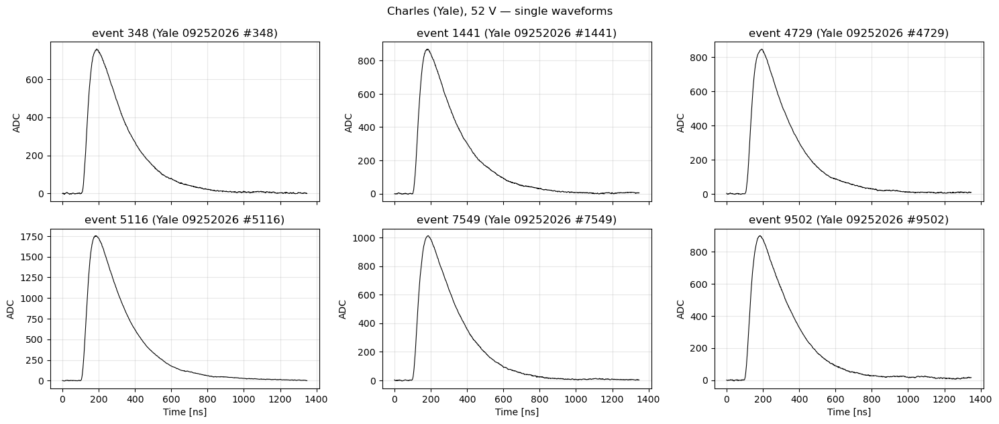

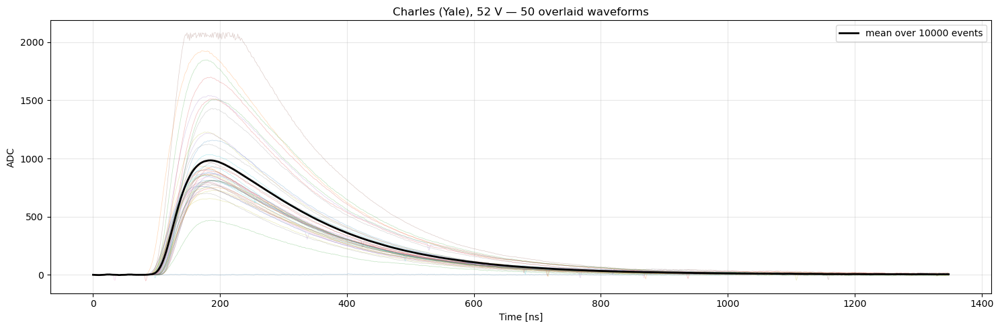

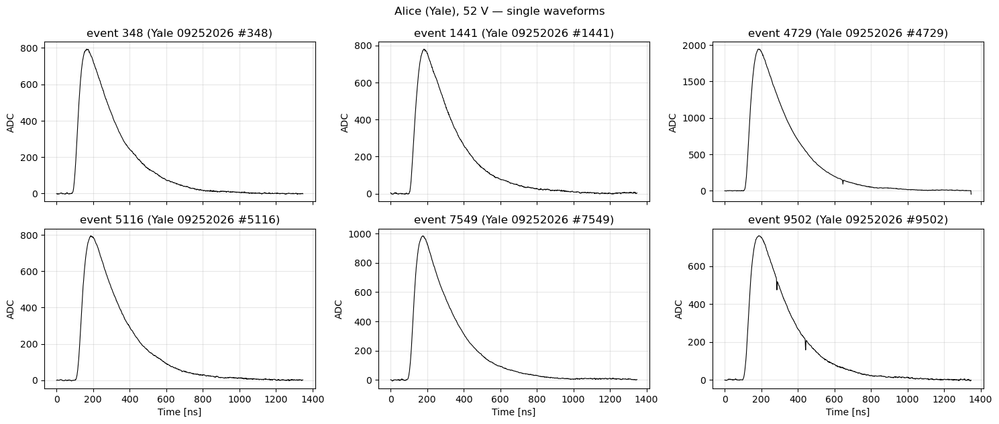

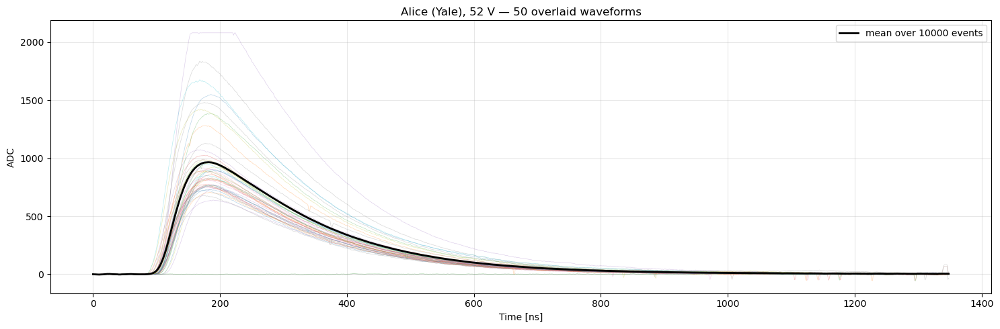

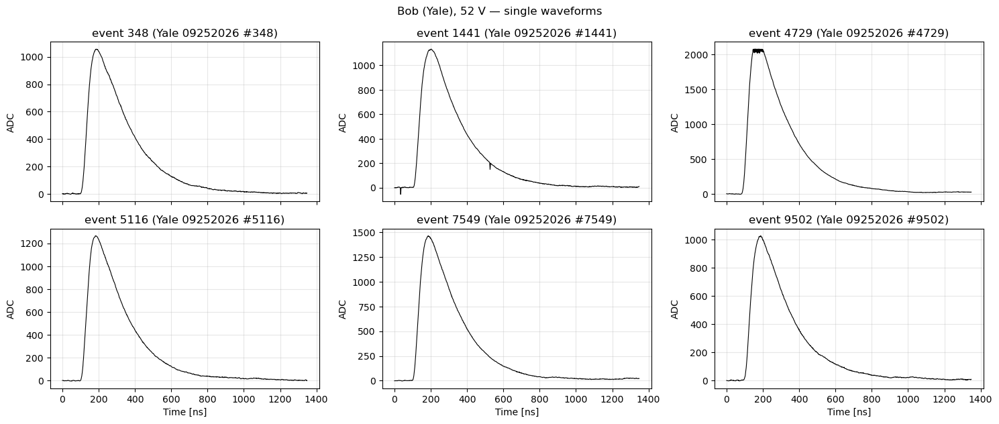

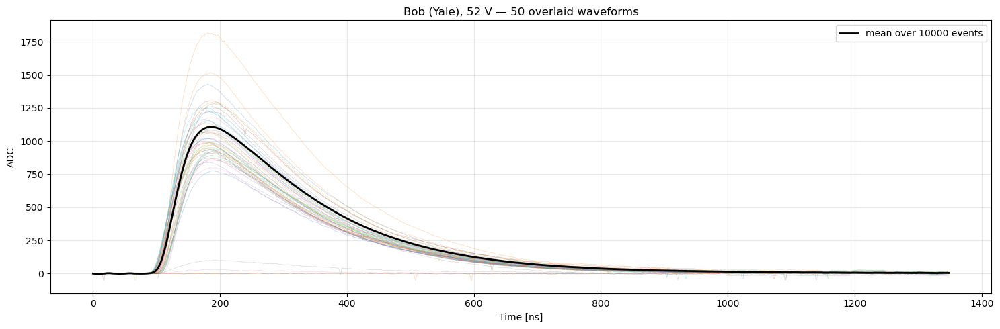

In [58]:
# === Alcune waveform di ogni canale, per vedere come sono i segnali ===
N_WF_SINGOLE = 6          # waveform mostrate una per pannello
N_WF_SOVRAPPOSTE = 50     # waveform sovrapposte nel pannello finale
EVENTI_SCELTI = None      # lista di indici, es. [0, 10, 250]; None = a caso
SEED = 1                  # cambiarlo per vedere altri eventi a caso

t_wf = np.arange(N_SAMPLES) * SAMPLING_TIME
eventi_per_run = {}       # gli stessi eventi si riusano nella cella del filtro
# Stesso SEED per ogni canale: gli eventi mostrati sono gli stessi trigger
# visti dai tre rivelatori, e i pannelli si confrontano fra loro

for lab in wf_canali:
    wf_run = wf_canali[lab]
    rng = np.random.default_rng(SEED)
    eventi = (list(EVENTI_SCELTI) if EVENTI_SCELTI is not None
              else sorted(rng.choice(len(wf_run), N_WF_SINGOLE, replace=False)))
    eventi_per_run[lab] = eventi
    if not mostra(lab):
        continue

    ncol = 3
    nrow = int(np.ceil(len(eventi) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, eventi):
        ax.plot(t_wf, wf_run[ev], lw=0.8, color="k")
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]})")
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    for ax in axes.flat[len(eventi):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(f"{DESCRIZIONE[lab]} — single waveforms")
    plt.tight_layout()
    plt.show()

    # Sovrapposte + media su tutti gli eventi: la media mostra dove cade il segnale
    # (media in float64 senza copiare la matrice: a run intera sono milioni di eventi)
    sovr = rng.choice(len(wf_run), min(N_WF_SOVRAPPOSTE, len(wf_run)), replace=False)
    fig, ax = plt.subplots(figsize=(15, 5))
    for ev in sovr:
        ax.plot(t_wf, wf_run[ev], lw=0.5, alpha=0.3)
    ax.plot(t_wf, wf_run.mean(axis=0, dtype=np.float64), lw=2, color="k", label=f"mean over {len(wf_run)} events")
    ax.set_xlabel("Time [ns]")
    ax.set_ylabel("ADC")
    ax.set_title(f"{DESCRIZIONE[lab]} — {len(sovr)} overlaid waveforms")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

Filtro: low-pass 50 MHz
[Charles (Yale), 52 V] rumore rms per evento (mediana su 10000 eventi): grezza 257.67 ADC, filtrata 257.66 ADC


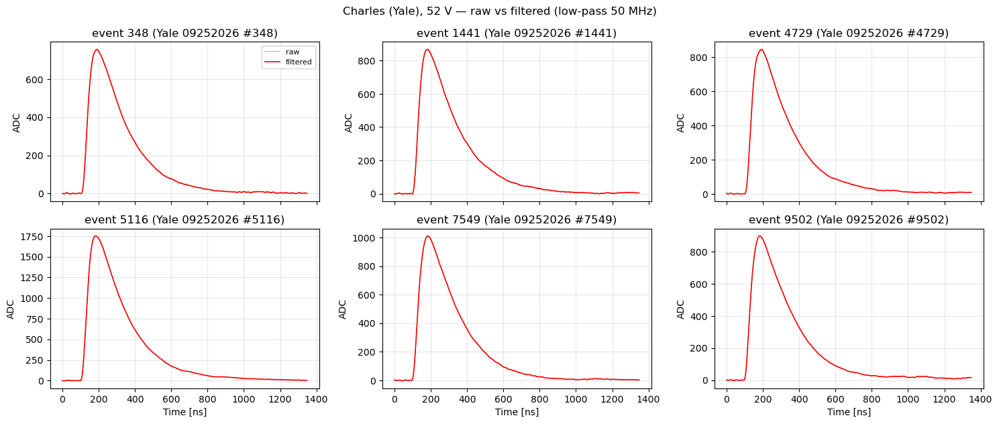

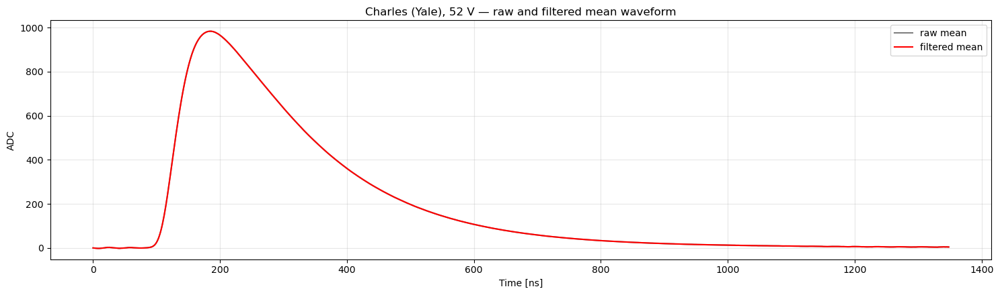

[Alice (Yale), 52 V] rumore rms per evento (mediana su 10000 eventi): grezza 251.08 ADC, filtrata 251.07 ADC


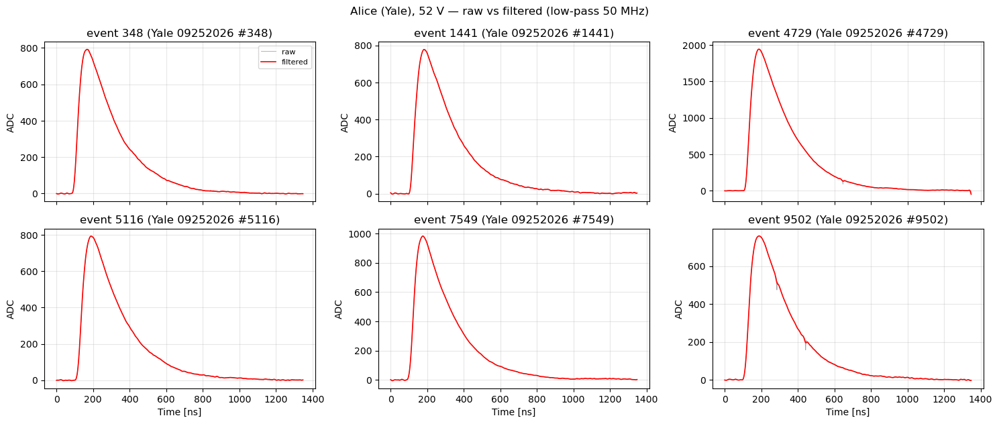

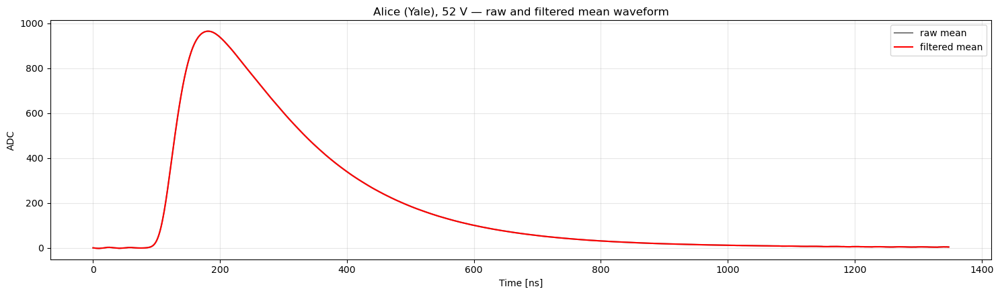

[Bob (Yale), 52 V] rumore rms per evento (mediana su 10000 eventi): grezza 296.46 ADC, filtrata 296.45 ADC


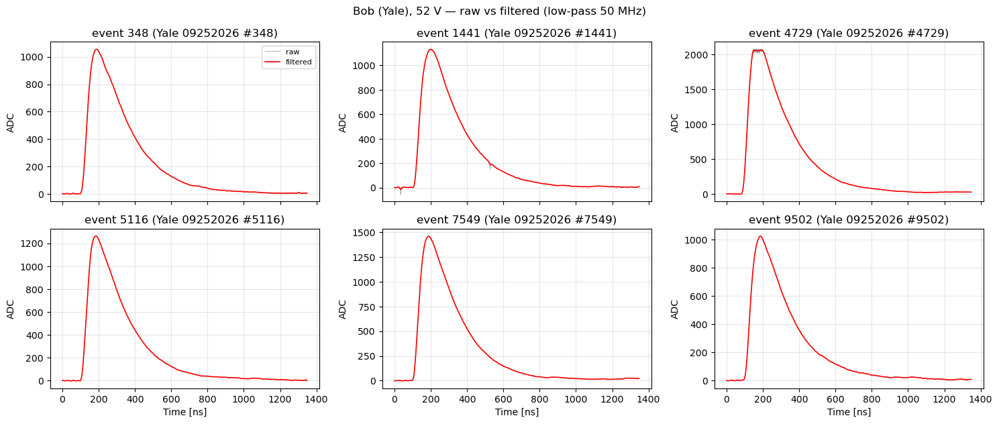

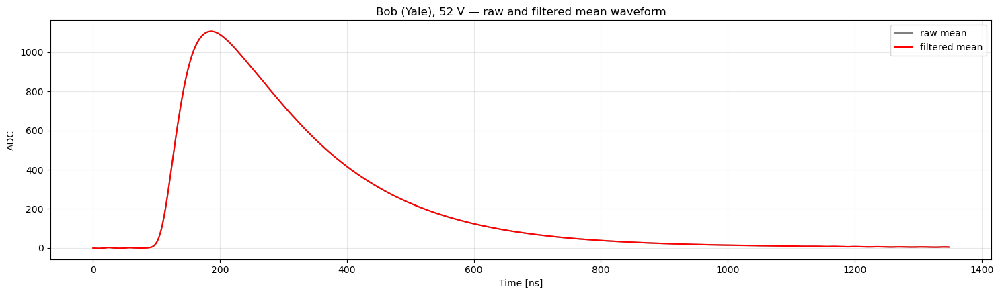

In [59]:
# === Filtro delle waveform: grezza e filtrata a confronto ===
from scipy.signal import butter, iirnotch, sosfiltfilt, filtfilt

# Lo spettro del rumore (run 54 V senza LED) ha una riga dominante a ~98 MHz,
# larga una decina di MHz, e una minore a ~188 MHz; il segnale del SiPM sta
# sotto ~30 MHz (salita ~20 ns, discesa di centinaia di ns). Un passa-basso a
# 50 MHz toglie entrambe le righe senza toccare l'impulso. I notch sono
# l'alternativa se si vuole lasciare intatto il resto della banda: con Q alto
# pero' sono piu' stretti della riga a 98 MHz, che e' larga.
# Si filtra con filtfilt (avanti e indietro): fase nulla, quindi l'impulso non
# si sposta nel tempo e l'inizio della salita resta dov'e'.
# Lo stesso filtro si applica a tutti i canali.
FILTRO_LOWPASS = True
LP_CUTOFF_MHZ = 50.0
LP_ORDINE = 4

FILTRO_NOTCH = False
NOTCH_MHZ = [97.5, 187.5]
NOTCH_Q = 10                  # Q = f0 / larghezza: 10 a 98 MHz -> ~10 MHz

USA_FILTRATE = True           # le celle successive analizzano le WF filtrate

fs_hz = 1e9 / SAMPLING_TIME   # SAMPLING_TIME e' in ns


BLOCCO_EVENTI = 50000         # il filtro lavora in float64: a blocchi la memoria resta limitata


def filtra_waveform(wf):
    """Filtra una matrice (eventi, campioni) lungo i campioni; restituisce float32.

    A blocchi di BLOCCO_EVENTI: tutta la run in float64 in un colpo solo
    vorrebbe decine di GB per canale, fra copie e padding di filtfilt.
    Il filtro agisce su ogni evento separatamente, quindi il risultato non
    dipende dal blocco.
    """
    out = np.empty(wf.shape, dtype=np.float32)
    sos = butter(LP_ORDINE, LP_CUTOFF_MHZ * 1e6, btype="low", fs=fs_hz, output="sos") if FILTRO_LOWPASS else None
    for i0 in range(0, wf.shape[0], BLOCCO_EVENTI):
        x = wf[i0:i0 + BLOCCO_EVENTI].astype(np.float64)
        if FILTRO_NOTCH:
            for f0 in NOTCH_MHZ:
                b, a = iirnotch(f0 * 1e6, NOTCH_Q, fs_hz)
                x = filtfilt(b, a, x, axis=1)
        if FILTRO_LOWPASS:
            x = sosfiltfilt(sos, x, axis=1)
        out[i0:i0 + BLOCCO_EVENTI] = x
    return out


wf_filt_canali = {ch: filtra_waveform(wf_canali[ch]) for ch in wf_canali}
wf_analisi = wf_filt_canali if USA_FILTRATE else wf_canali

t_f = np.arange(N_SAMPLES) * SAMPLING_TIME
filtri = " + ".join(([f"low-pass {LP_CUTOFF_MHZ:g} MHz"] if FILTRO_LOWPASS else []) +
                    ([f"notch {NOTCH_MHZ} MHz (Q={NOTCH_Q})"] if FILTRO_NOTCH else [])) or "none"
print(f"Filtro: {filtri}")

for lab in wf_canali:
    raw, filt = wf_canali[lab], wf_filt_canali[lab]
    # rms su un sottoinsieme: la mediana e' stabile gia' con decine di migliaia di eventi,
    # e su tutta la run std() creerebbe copie in float64 da GB
    sub = slice(0, min(len(raw), 50000))
    print(f"[{DESCRIZIONE[lab]}] rumore rms per evento (mediana su {sub.stop} eventi): "
          f"grezza {np.median(raw[sub].std(axis=1)):.2f} ADC, filtrata {np.median(filt[sub].std(axis=1)):.2f} ADC")

    if not mostra(lab):
        continue

    # --- Stessi eventi della cella delle waveform, grezza e filtrata sovrapposte ---
    eventi = eventi_per_run[lab]
    ncol = 3
    nrow = int(np.ceil(len(eventi) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, eventi):
        ax.plot(t_f, raw[ev], lw=0.6, color="gray", alpha=0.7, label="raw")
        ax.plot(t_f, filt[ev], lw=1.2, color="red", label="filtered")
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]})")
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    for ax in axes.flat[len(eventi):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    axes.flat[0].legend(loc="upper right", fontsize=8)
    fig.suptitle(f"{DESCRIZIONE[lab]} — raw vs filtered ({filtri})")
    plt.tight_layout()
    plt.show()

    # --- Waveform media, prima e dopo: mostra se il filtro deforma l'impulso ---
    fig, ax = plt.subplots(figsize=(15, 4.5))
    ax.plot(t_f, raw.mean(axis=0, dtype=np.float64), color="gray", label="raw mean")
    ax.plot(t_f, filt.mean(axis=0, dtype=np.float64), color="red", label="filtered mean")
    ax.set_xlabel("Time [ns]"); ax.set_ylabel("ADC"); ax.grid(True, alpha=0.3); ax.legend()
    ax.set_title(f"{DESCRIZIONE[lab]} — raw and filtered mean waveform")
    plt.tight_layout()
    plt.show()

=== Charles (Yale), 52 V ===
Risoluzione in frequenza: 0.741 MHz  (Nyquist 375 MHz)
 riga [MHz]  larghezza [MHz]  sopra il fondo  attenuazione filtro


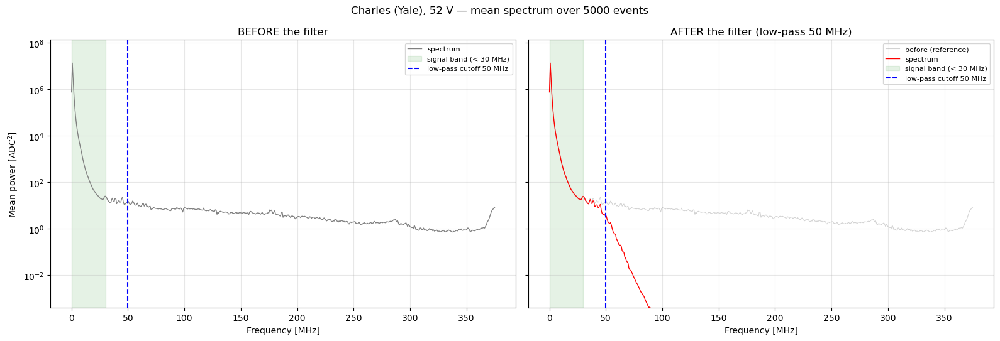

=== Alice (Yale), 52 V ===
Risoluzione in frequenza: 0.741 MHz  (Nyquist 375 MHz)
 riga [MHz]  larghezza [MHz]  sopra il fondo  attenuazione filtro


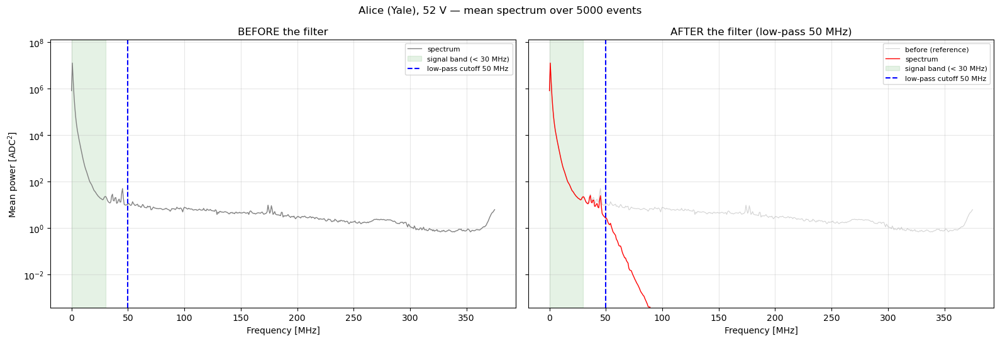

=== Bob (Yale), 52 V ===
Risoluzione in frequenza: 0.741 MHz  (Nyquist 375 MHz)
 riga [MHz]  larghezza [MHz]  sopra il fondo  attenuazione filtro


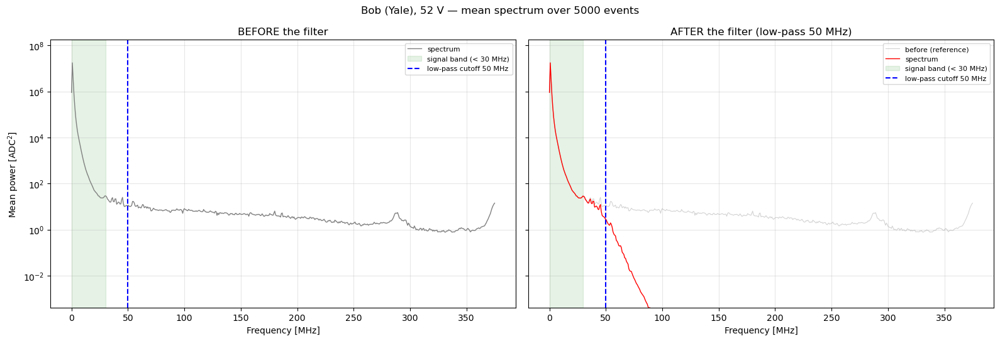

In [60]:
# === Spettro del rumore: dove sono le bande, prima e dopo il filtro ===
# Come si legge: la FFT scompone ogni waveform in sinusoidi; la potenza media
# su molti eventi dice quanta ampiezza c'e' a ogni frequenza. Il segnale del
# SiPM e' lento e sta tutto in basso (sotto ~30 MHz). Un rumore periodico
# compare invece come un picco stretto che spicca sul fondo: e' una "riga".
# Le righe si trovano da sole (find_peaks sul logaritmo della potenza grezza)
# e si marcano in tutti e due i pannelli, cosi' si vede quanto le ha tolte il filtro.
from scipy.signal import find_peaks, peak_widths

N_EVENTI_SPETTRO = 5000      # bastano per una media stabile
PROMINENZA_DECADI = 1.0      # una riga deve spiccare di 10x sul fondo vicino; con 3x
                             # si prendono anche le fluttuazioni del fondo
F_MIN_RIGHE_MHZ = 35.0       # sotto c'e' il segnale: non lo si cerca come rumore
BANDA_SEGNALE_MHZ = 30.0


def spettro_medio(wf):
    """(frequenze [MHz], potenza media [ADC^2]) su N_EVENTI_SPETTRO eventi.

    Si toglie la media di ogni evento (se no domina la frequenza zero) e si
    applica una finestra di Hann, che evita che i bordi della traccia, tagliati
    di netto, spargano potenza su tutte le frequenze.
    """
    x = wf[:N_EVENTI_SPETTRO].astype(np.float64)
    finestra = np.hanning(x.shape[1])
    x = (x - x.mean(axis=1, keepdims=True)) * finestra
    pot = (np.abs(np.fft.rfft(x, axis=1)) ** 2).mean(axis=0) / (finestra ** 2).sum()
    freq = np.fft.rfftfreq(x.shape[1], d=SAMPLING_TIME * 1e-9) / 1e6
    return freq, pot


for lab in wf_canali:
    freq, pot_raw = spettro_medio(wf_canali[lab])
    _, pot_filt = spettro_medio(wf_filt_canali[lab])
    df_mhz = freq[1] - freq[0]

    # Righe di rumore sullo spettro grezzo
    cerca = freq >= F_MIN_RIGHE_MHZ
    idx, prop = find_peaks(np.log10(pot_raw[cerca]), prominence=PROMINENZA_DECADI)
    idx = np.flatnonzero(cerca)[idx]
    # larghezza a meta' altezza in scala logaritmica, convertita in MHz
    larg = peak_widths(np.log10(pot_raw), idx, rel_height=0.5)[0] * df_mhz

    print(f"=== {DESCRIZIONE[lab]} ===")
    print(f"Risoluzione in frequenza: {df_mhz:.3f} MHz  (Nyquist {freq[-1]:.0f} MHz)")
    print(f"{'riga [MHz]':>11} {'larghezza [MHz]':>16} {'sopra il fondo':>15} {'attenuazione filtro':>20}")
    for i, w, prom in zip(idx, larg, prop["prominences"]):
        att = pot_raw[i] / pot_filt[i]
        # oltre ~1e6 il filtrato e' sul pavimento numerico (float32): il numero non e' una misura
        att_txt = f"{att:19.1e}x" if att < 1e6 else f"{'> 1e6x':>20}"
        print(f"{freq[i]:11.1f} {w:16.1f} {10 ** prom:14.0f}x {att_txt}")

    if not mostra(lab):
        continue
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
    for ax, pot, titolo, colore in [(axes[0], pot_raw, "BEFORE the filter", "gray"),
                                    (axes[1], pot_filt, f"AFTER the filter ({filtri})", "red")]:
        if pot is pot_filt:
            ax.semilogy(freq, pot_raw, color="gray", lw=0.8, alpha=0.35, label="before (reference)")
        ax.semilogy(freq, pot, color=colore, lw=1, label="spectrum")
        ax.axvspan(0, BANDA_SEGNALE_MHZ, color="green", alpha=0.10, label=f"signal band (< {BANDA_SEGNALE_MHZ:g} MHz)")
        for k, (i, w) in enumerate(zip(idx, larg)):
            ax.axvspan(freq[i] - w / 2, freq[i] + w / 2, color="orange", alpha=0.35,
                       label="noise lines" if k == 0 else None)
            ax.annotate(f"{freq[i]:.1f} MHz", (freq[i], pot_raw[i]), textcoords="offset points",
                        xytext=(4, 4), fontsize=8)
        if FILTRO_LOWPASS:
            ax.axvline(LP_CUTOFF_MHZ, color="blue", ls="--", label=f"low-pass cutoff {LP_CUTOFF_MHZ:g} MHz")
        if FILTRO_NOTCH:
            for k, f0 in enumerate(NOTCH_MHZ):
                ax.axvline(f0, color="purple", ls=":", label="notch" if k == 0 else None)
        ax.set_title(titolo)
        ax.set_xlabel("Frequency [MHz]")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8, loc="upper right")
    axes[0].set_ylabel("Mean power [ADC$^2$]")
    # Sotto ~1e-4 del fondo grezzo il filtrato tocca la precisione dei float32:
    # mostrarlo schiaccerebbe tutto il resto senza aggiungere informazione
    axes[0].set_ylim(np.median(pot_raw) * 1e-4, pot_raw.max() * 10)
    fig.suptitle(f"{DESCRIZIONE[lab]} — mean spectrum over {min(N_EVENTI_SPETTRO, len(wf_canali[lab]))} events")
    plt.tight_layout()
    plt.show()

[Charles (Yale), 52 V] finestra lunga della carica [90, 950] ns (cumulata al 99% a 933 ns, crescita nella coda 0.7%); finestra dell'impulso [109, 1057] ns (massimo medio 984 ADC a 185 ns; inizio al 10%, fine al 1% del massimo), 10000 eventi
    Q_segnale : media       254844  mediana       228359  std     118196 ADC ns
    Q_baseline: media           -0  mediana           -0  std          3 ADC ns
[Alice (Yale), 52 V] finestra lunga della carica [90, 950] ns (cumulata al 99% a 928 ns, crescita nella coda 0.7%); finestra dell'impulso [108, 1044] ns (massimo medio 965 ADC a 181 ns; inizio al 10%, fine al 1% del massimo), 10000 eventi
    Q_segnale : media       245412  mediana       220616  std     117666 ADC ns
    Q_baseline: media           -0  mediana           -0  std          3 ADC ns
[Bob (Yale), 52 V] finestra lunga della carica [90, 950] ns (cumulata al 99% a 935 ns, crescita nella coda 0.7%); finestra dell'impulso [109, 1065] ns (massimo medio 1107 ADC a 185 ns; inizio al 10%, 

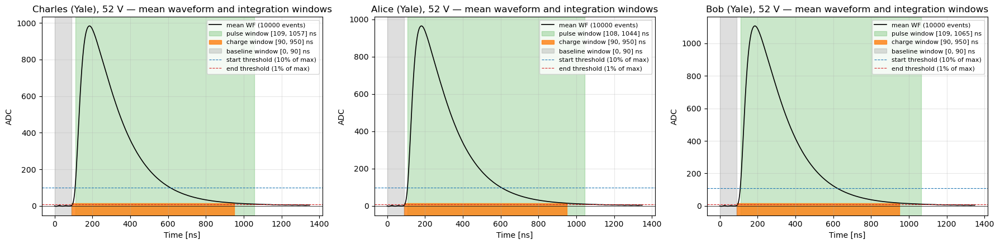

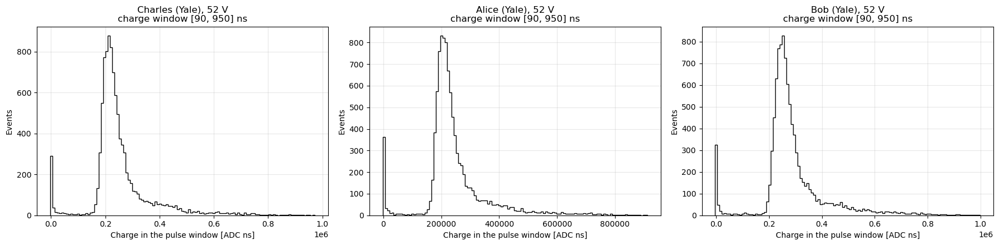

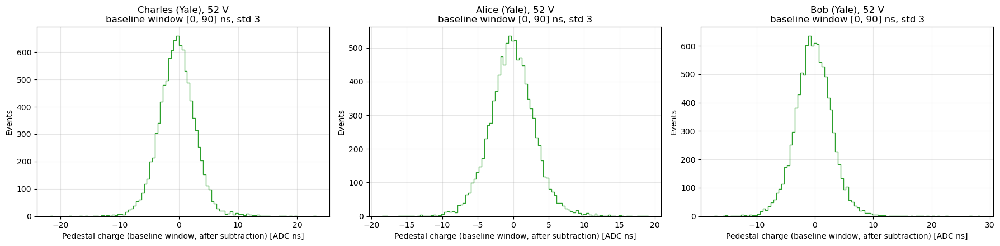

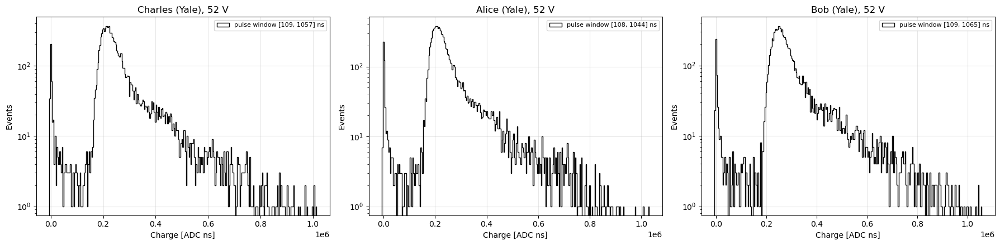

In [61]:
# === Carica per evento: nella finestra lunga e piedistallo, per ogni rivelatore ===
# (COPIA della cella della carica dei dati nuovi: stesso calcolo, stessa finestra lunga, cosi'
# la carica Yale e' confrontabile con quella dei dati nuovi e con la caratterizzazione dei SiPM.)
# Sulle WF FILTRATE (wf_filt_canali), con la baseline per evento gia' sottratta.
# Carica = SOMMA DEI CAMPIONI x dt [ADC ns]. Il dt e' necessario: la somma dei campioni
# da sola scala come 1/dt (a 1 GS/s e' 1.33 volte quella a 750 MS/s per lo stesso impulso),
# mentre somma x dt e' l'integrale dell'impulso e non dipende dalla frequenza (l'impulso
# e' filtrato a 50 MHz, campionato molto sopra Nyquist). Il notebook del guadagno somma
# i campioni senza dt: Qpe_tot nel JSON e' in ADC campione a dt = sampling_time_ns del
# JSON, e la cella dell'equalizzazione lo porta in ADC ns moltiplicando per quel dt,
# cosi' Q_SEGNALE / Qpe_tot e' un rapporto fra grandezze nella stessa unita'.
# Due cariche per evento e per canale:
#  - Q_segnale: nella FINESTRA LUNGA della carica (FINESTRA_Q_NS, vedi sotto);
#  - Q_baseline: nella finestra della baseline (BASELINE_NS), dopo la sottrazione: il piedistallo.
#
# FINESTRA LUNGA DELLA CARICA: stesso criterio di SiPM_Characterization_Gain_Study
# (cella della finestra lunga), cosi' Q_segnale / Qpe_tot non porta un errore di
# finestra. Dalla fine della baseline al primo istante in cui la carica cumulata
# della WF media raggiunge FRAZ_CARICA_FINESTRA del suo valore finale (media della
# cumulata negli ultimi CODA_PLATEAU_NS della traccia), arrotondato per eccesso a
# 50 ns. Si misura in ns sulla WF media del canale, quindi non dipende dalla
# frequenza di campionamento; dipende dal segnale, per questo e' per canale.
# NON si integra "fino a fine traccia": la lunghezza della traccia e' N*dt (410 ns a
# 2.5 GS/s, 1365 ns a 750 MS/s) e la frazione di coda contenuta cambierebbe con la
# frequenza; e la coda del SiPM a fine traccia non e' ancora zero (~+0.5% del massimo
# a 750 MS/s). Se la fine cade oltre la traccia la cella lo dice: la carica e' troncata
# rispetto a Qpe_tot e la run va trattata a parte.
#
# Il picco della carica non cambia di piu' dell'1-3% fra 900 ns e fine traccia
# (run 0168), ma per il light yield conta che le due finestre contengano la stessa
# frazione dell'impulso.
#
# FINESTRA_CARICA_NS (10% -> 1% della WF media, sotto) resta la finestra dove le
# celle dell'efficienza cercano il segnale sopra soglia: non si tocca, l'efficienza
# non cambia.
#
# Finestra dell'impulso, dalla WF media di ogni canale (la stessa finestra per
# tutti gli eventi): comincia dove la media supera FRAZ_INIZIO_FINESTRA del suo
# massimo (cercato dal massimo all'indietro, cosi' il rumore prima della salita
# non la sposta) e finisce dove, dopo il massimo, scende sotto
# FRAZ_FINE_FINESTRA del massimo.
# "Scende fino alla baseline" non e' un incrocio dello zero: misurato sulle run
# 0168-0171 la coda decade come un esponenziale (~200 ns) e non scavalca mai la
# baseline, a fine traccia e' ancora allo 0.4% del massimo. Come "baseline" si
# prende quindi una frazione piccola del massimo, ma sopra il rumore della
# media (~1 ADC, cioe' ~0.1% del massimo): con 1% la finestra finisce a ~1150 ns.
# Abbassarla allunga la finestra fin quasi a fine traccia.
FRAZ_INIZIO_FINESTRA = 0.10   # X
FRAZ_FINE_FINESTRA = 0.01     # Y

# Finestra lunga della carica (stessi valori del notebook del guadagno)
FRAZ_CARICA_FINESTRA = 0.99
CODA_PLATEAU_NS = 300
# Controllo: nell'ultimo tratto (CODA_PLATEAU_NS) la cumulata deve essere gia' piatta, se no
# il "valore finale" e' sottostimato e il 99% cade troppo presto (traccia troppo corta:
# misurato sulla run 0190, 1 GS/s, il criterio dava 800 ns e la carica risultava il 3-5%
# piu' bassa di quella a 750 MS/s; integrando fino a fine traccia, 1011 ns, i due
# coincidono entro 0.5%). In quel caso la finestra va fino a fine traccia: e' tutta la coda
# che c'e'. Soglia sulla crescita della cumulata, relativa al suo valore finale, nell'ultimo tratto.
CRESCITA_CODA_MAX = 0.02

# Q_baseline e' la somma sulla WF filtrata DOPO la sottrazione della baseline
# per evento, nella finestra BASELINE_NS: e' il piedistallo che resta. La baseline
# e' stata tolta dai campioni grezzi di quella stessa finestra, quindi la somma
# vale ~0 per costruzione: l'unico residuo e' quello che il filtro sposta (il
# filtro e' lineare, ma agisce sui campioni vicini ai bordi della finestra).
# E' una somma su BASELINE_NS (meno campioni di quella sull'impulso).
dt_q = SAMPLING_TIME
t_q = np.arange(N_SAMPLES) * dt_q
mask_bl_q = (t_q >= BASELINE_NS[0]) & (t_q <= BASELINE_NS[1])

WF_MEDIA_Q = {}              # canale -> WF media filtrata (per il grafico delle finestre)
FINESTRA_CARICA_NS = {}      # canale -> (inizio, fine) della finestra dell'impulso [ns] (efficienza)
FINESTRA_Q_NS = {}           # canale -> (inizio, fine) della finestra lunga della carica [ns]
Q_SEGNALE, Q_BASELINE = {}, {}   # canale -> carica per evento [ADC ns]
for ch in CANALI:
    wf = wf_filt_canali[ch]
    media = wf.mean(axis=0, dtype=np.float64)
    i_max = int(np.argmax(media))
    amp = media[i_max]
    WF_MEDIA_Q[ch] = media
    sotto = np.flatnonzero(media[:i_max + 1] < FRAZ_INIZIO_FINESTRA * amp)
    j0 = sotto[-1] + 1 if len(sotto) else 0
    ritorno = np.flatnonzero(media[i_max:] <= FRAZ_FINE_FINESTRA * amp)
    if len(ritorno):
        j1 = i_max + int(ritorno[0])
    else:
        j1 = N_SAMPLES - 1
        print(f"ATTENZIONE {DESCRIZIONE[ch]}: la WF media non scende sotto il {100 * FRAZ_FINE_FINESTRA:g}% "
              f"del massimo prima della fine della traccia: la finestra finisce a {t_q[j1]:.0f} ns")
    FINESTRA_CARICA_NS[ch] = (float(t_q[j0]), float(t_q[j1]))
    # Finestra lunga: stesso calcolo del notebook del guadagno, sulla WF media del canale
    i_bl_fine = np.searchsorted(t_q, BASELINE_NS[1])
    m_q = media - media[mask_bl_q].mean()
    cum = np.cumsum(m_q[i_bl_fine:])
    plateau = cum[t_q[i_bl_fine:] >= t_q[-1] - CODA_PLATEAU_NS].mean()
    t_frac = t_q[i_bl_fine:][np.argmax(cum >= FRAZ_CARICA_FINESTRA * plateau)]
    fine_q = float(np.ceil(t_frac / 50) * 50)
    i_coda = np.searchsorted(t_q[i_bl_fine:], t_q[-1] - CODA_PLATEAU_NS)
    crescita_coda = (cum[-1] - cum[i_coda]) / cum[-1]
    if crescita_coda > CRESCITA_CODA_MAX:
        print(f"ATTENZIONE {DESCRIZIONE[ch]}: la carica cumulata cresce ancora del {100 * crescita_coda:.1f}% "
              f"negli ultimi {CODA_PLATEAU_NS} ns della traccia: il criterio (99% a {fine_q:.0f} ns) non e' "
              f"affidabile, si integra fino a fine traccia ({t_q[-1]:.0f} ns, {t_q[-1] - t_frac:.0f} ns dopo il 99%). "
              f"Confrontare con la finestra del LED: la coda oltre la traccia manca")
        fine_q = float(t_q[-1])
    if fine_q > t_q[-1]:
        print(f"ATTENZIONE {DESCRIZIONE[ch]}: la finestra lunga finirebbe a {fine_q:.0f} ns, oltre la traccia "
              f"({t_q[-1]:.0f} ns): la carica e' troncata rispetto a Qpe_tot")
        fine_q = float(t_q[-1])
    FINESTRA_Q_NS[ch] = (float(BASELINE_NS[1]), fine_q)
    mask_sig = (t_q >= FINESTRA_Q_NS[ch][0]) & (t_q <= FINESTRA_Q_NS[ch][1])

    n_ev = wf.shape[0]
    qs, qb = np.empty(n_ev), np.empty(n_ev)
    for k in range(0, n_ev, BLOCCO_EVENTI):
        blocco = wf[k:k + BLOCCO_EVENTI]
        qs[k:k + BLOCCO_EVENTI] = blocco[:, mask_sig].sum(axis=1, dtype=np.float64) * dt_q
        qb[k:k + BLOCCO_EVENTI] = blocco[:, mask_bl_q].sum(axis=1, dtype=np.float64) * dt_q
    Q_SEGNALE[ch], Q_BASELINE[ch] = qs, qb

    print(f"[{DESCRIZIONE[ch]}] finestra lunga della carica [{FINESTRA_Q_NS[ch][0]:.0f}, {FINESTRA_Q_NS[ch][1]:.0f}] ns "
          f"(cumulata al {100 * FRAZ_CARICA_FINESTRA:g}% a {t_frac:.0f} ns, crescita nella coda {100 * crescita_coda:.1f}%); finestra dell'impulso [{t_q[j0]:.0f}, {t_q[j1]:.0f}] ns "
          f"(massimo medio {amp:.0f} ADC a {t_q[i_max]:.0f} ns; inizio al {100 * FRAZ_INIZIO_FINESTRA:g}%, "
          f"fine al {100 * FRAZ_FINE_FINESTRA:g}% del massimo), {n_ev} eventi")
    for nome, q in (("segnale ", qs), ("baseline", qb)):
        print(f"    Q_{nome}: media {q.mean():12.0f}  mediana {np.median(q):12.0f}  std {q.std():10.0f} ADC ns")

canali_q = [ch for ch in CANALI if mostra(ch)]
if canali_q:
    def figura_per_canale():
        fig, assi = plt.subplots(1, len(canali_q), figsize=(6 * len(canali_q), 4.5), squeeze=False)
        return fig, assi[0]

    # --- WF media con le finestre di integrazione ---
    # Verde: finestra dell'impulso (Q_segnale). Grigio: finestra della baseline
    # (la stessa di cui e' stata tolta la media evento per evento). Le linee
    # tratteggiate sono le soglie che definiscono inizio e fine della finestra.
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        media = WF_MEDIA_Q[ch]
        amp = media.max()
        j0_ns, j1_ns = FINESTRA_CARICA_NS[ch]
        ax.plot(t_q, media, color="k", lw=1.2, label=f"mean WF ({len(wf_filt_canali[ch])} events)")
        ax.axvspan(j0_ns, j1_ns, color="tab:green", alpha=0.25,
                   label=f"pulse window [{j0_ns:.0f}, {j1_ns:.0f}] ns")
        ax.axvspan(*FINESTRA_Q_NS[ch], ymin=0, ymax=0.06, color="tab:orange", alpha=0.8,
                   label=f"charge window [{FINESTRA_Q_NS[ch][0]:.0f}, {FINESTRA_Q_NS[ch][1]:.0f}] ns")
        ax.axvspan(BASELINE_NS[0], BASELINE_NS[1], color="tab:gray", alpha=0.25,
                   label=f"baseline window [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns")
        ax.axhline(FRAZ_INIZIO_FINESTRA * amp, color="tab:blue", ls="--", lw=0.8,
                   label=f"start threshold ({100 * FRAZ_INIZIO_FINESTRA:g}% of max)")
        ax.axhline(FRAZ_FINE_FINESTRA * amp, color="tab:red", ls="--", lw=0.8,
                   label=f"end threshold ({100 * FRAZ_FINE_FINESTRA:g}% of max)")
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("Time [ns]"); ax.set_ylabel("ADC")
        ax.set_title(f"{DESCRIZIONE[ch]} — mean waveform and integration windows")
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    # --- Distribuzione della carica del segnale, per canale ---
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        lo, hi = np.percentile(Q_SEGNALE[ch], (0.1, 99.9))
        ax.hist(Q_SEGNALE[ch], bins=np.linspace(lo, hi, 120), histtype="step", color="k")
        ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
        ax.set_title(f"{DESCRIZIONE[ch]}\ncharge window [{FINESTRA_Q_NS[ch][0]:.0f}, {FINESTRA_Q_NS[ch][1]:.0f}] ns")
        ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Distribuzione della carica nella finestra della baseline, per canale ---
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        lo, hi = np.percentile(Q_BASELINE[ch], (0.05, 99.95))
        ax.hist(Q_BASELINE[ch], bins=np.linspace(lo, hi, 100), histtype="step", color="tab:green")
        ax.set_xlabel("Pedestal charge (baseline window, after subtraction) [ADC ns]"); ax.set_ylabel("Events")
        ax.set_title(f"{DESCRIZIONE[ch]}\nbaseline window [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns, std {Q_BASELINE[ch].std():.0f}")
        ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Carica nella finestra dell'impulso, con i tagli in carica provati (la baseline ha i suoi plot) ---
    fig, assi = figura_per_canale()
    for ax, ch in zip(assi, canali_q):
        lo, hi = np.percentile(Q_SEGNALE[ch], (0.05, 99.95))
        bins = np.linspace(lo, hi, 300)
        ax.hist(Q_SEGNALE[ch], bins=bins, histtype="step", color="k",
                label=f"pulse window [{FINESTRA_CARICA_NS[ch][0]:.0f}, {FINESTRA_CARICA_NS[ch][1]:.0f}] ns")
        ax.set_yscale("log")
        ax.set_xlabel("Charge [ADC ns]"); ax.set_ylabel("Events")
        ax.set_title(DESCRIZIONE[ch])
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

[Charles (Yale), 52 V] eventi con Q <= 25000: 359 su 10000 (3.590%); Q massima 1600697 ADC ns


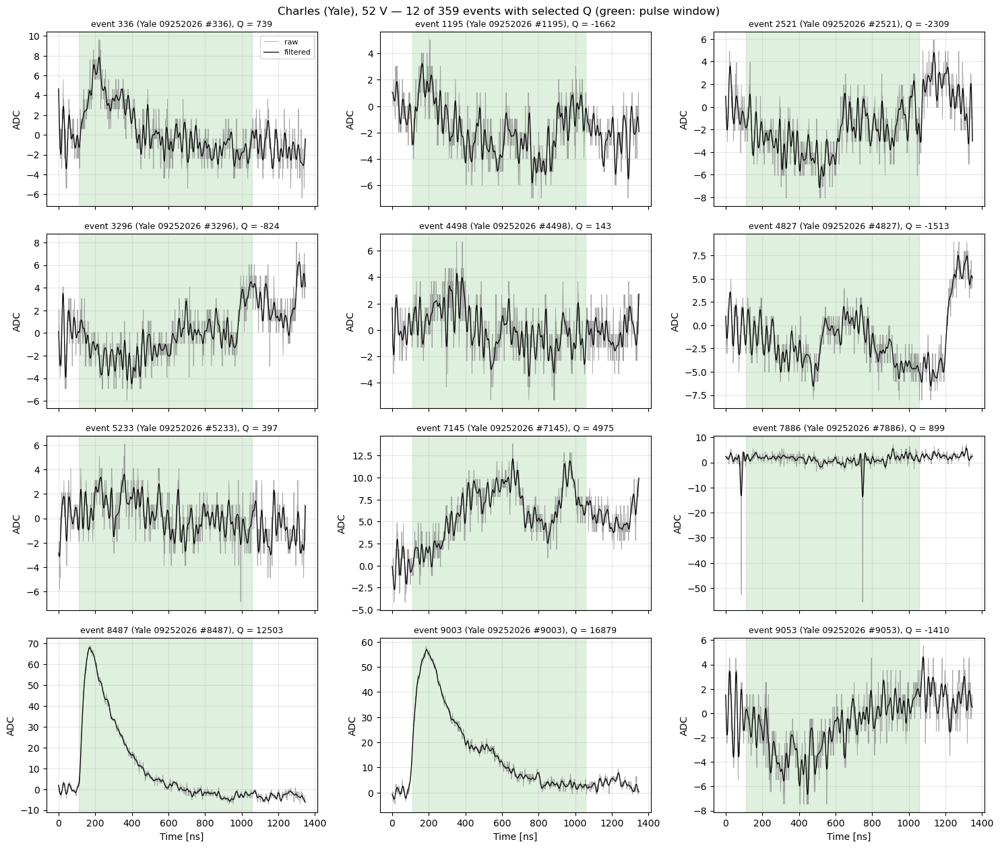

[Alice (Yale), 52 V] eventi con Q <= 60000: 466 su 10000 (4.660%); Q massima 1426588 ADC ns


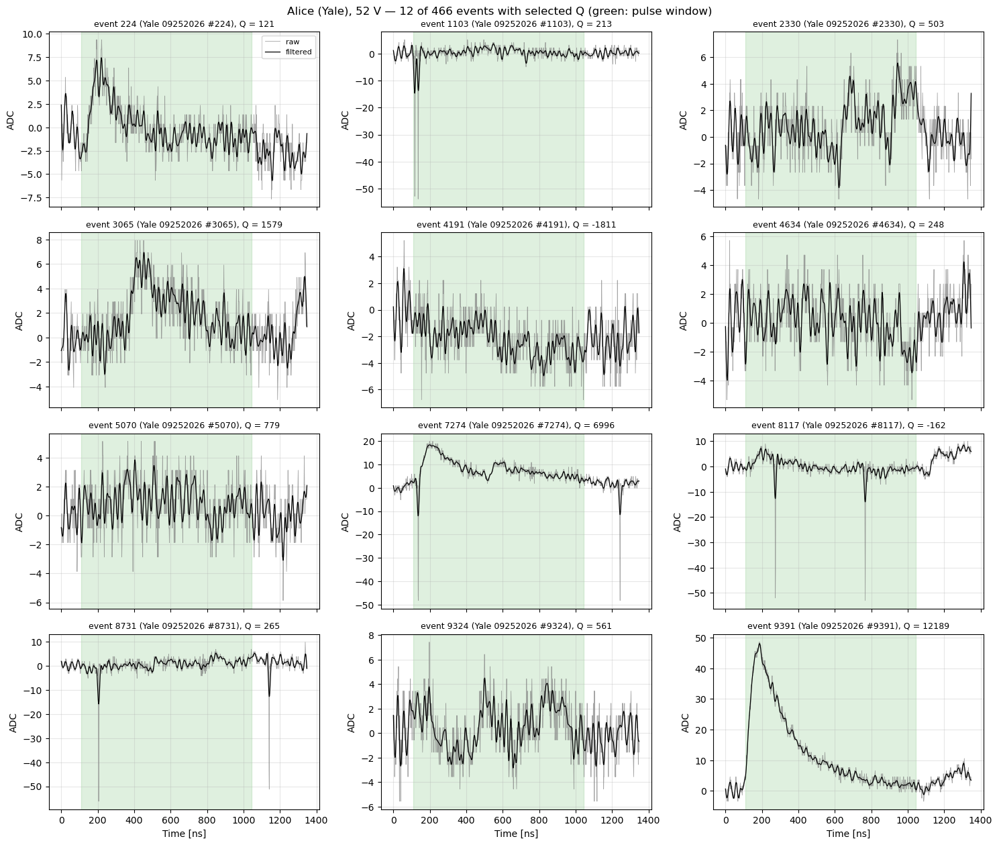

[Bob (Yale), 52 V] eventi con Q <= 60000: 434 su 10000 (4.340%); Q massima 1174423 ADC ns


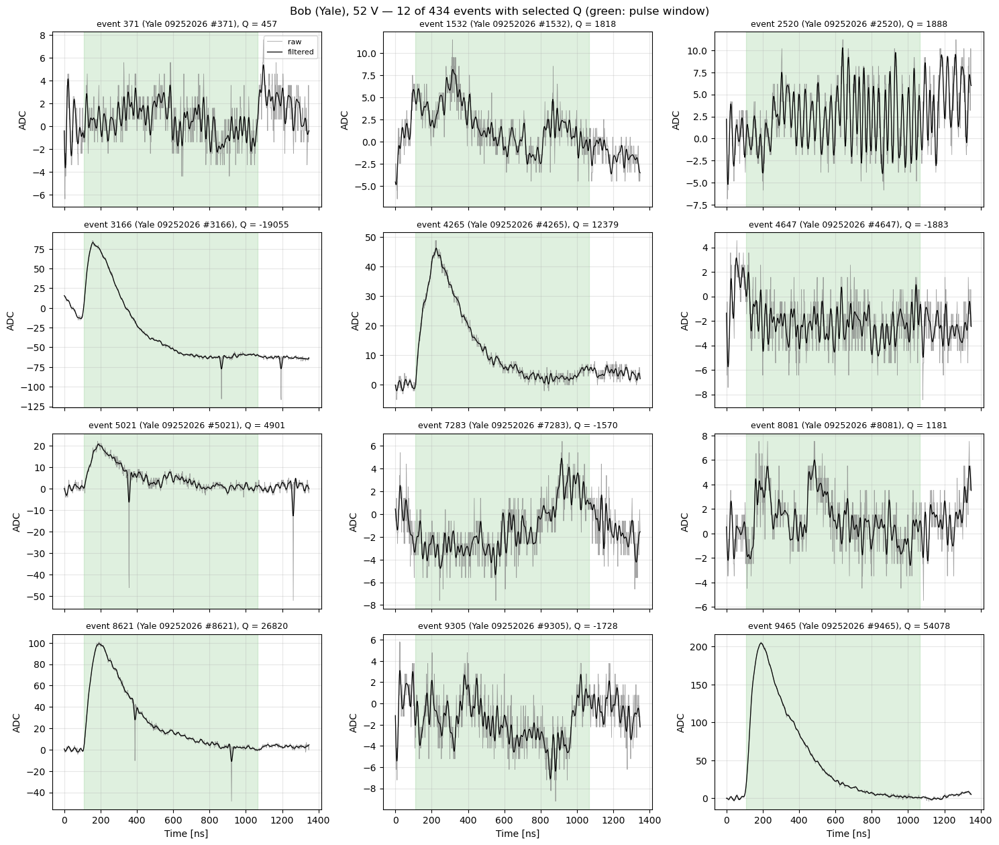

In [62]:
# === Eventi con Q fino a una soglia: waveform degli eventi selezionati ===
# Carica = quella nella finestra dell'impulso (Q_SEGNALE, cella della carica).
# Si guardano gli eventi con Q <= Q_MAX_EVENTI, per vedere che forma
# hanno. Per guardare una fascia, impostare anche Q_MIN_EVENTI; per la coda
# alta, invertire i due limiti (min = soglia, max = None).
Q_MIN_EVENTI = None       # [ADC ns]; None = nessun limite inferiore
# Un limite per rivelatore (gli spettri non partono dallo stesso valore); None = nessun limite
Q_MAX_EVENTI = {"Charles": 25000, "Alice": 60000, "Bob": 60000}
N_EVENTI_ALTA_Q = 12          # waveform mostrate per canale (a caso fra quelle selezionate)
SEED_ALTA_Q = 1

for ch in canali_q:
    q = Q_SEGNALE[ch]
    sel = np.ones(len(q), dtype=bool)
    if Q_MIN_EVENTI is not None:
        sel &= q >= Q_MIN_EVENTI
    q_max = Q_MAX_EVENTI.get(RIVELATORI[ch])
    if q_max is not None:
        sel &= q <= q_max
    idx = np.flatnonzero(sel)
    lim = " e ".join(([f">= {Q_MIN_EVENTI:g}"] if Q_MIN_EVENTI is not None else [])
                     + ([f"<= {q_max:g}"] if q_max is not None else []))
    print(f"[{DESCRIZIONE[ch]}] eventi con Q {lim}"
          + f": {len(idx)} su {len(q)} ({100 * len(idx) / len(q):.3f}%); Q massima {q.max():.0f} ADC ns")
    if len(idx) == 0:
        continue
    rng = np.random.default_rng(SEED_ALTA_Q)
    scelti = np.sort(rng.choice(idx, min(N_EVENTI_ALTA_Q, len(idx)), replace=False))

    ncol = 3
    nrow = int(np.ceil(len(scelti) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, scelti):
        ax.plot(t_q, wf_canali[ch][ev], lw=0.6, color="tab:gray", alpha=0.7, label="raw")
        ax.plot(t_q, wf_filt_canali[ch][ev], lw=0.9, color="k", label="filtered")
        ax.axvspan(*FINESTRA_CARICA_NS[ch], color="tab:green", alpha=0.15)
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]}), Q = {q[ev]:.0f}", fontsize=9)
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    axes.flat[0].legend(fontsize=8)
    for ax in axes.flat[len(scelti):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(f"{DESCRIZIONE[ch]} — {len(scelti)} of {len(idx)} events with selected Q (green: pulse window)")
    plt.tight_layout()
    plt.show()


In [66]:
# === Yale: PARAMETRI DELL'ANALISI: soglia e tagli sugli impulsi ===
# Gli stessi parametri della cella dei parametri dei dati nuovi, ma SEPARATI: le celle Yale
# qui sotto leggono solo questi (NSIGMA_YALE, ...), quindi per provare altri valori su Yale
# si cambia questa cella e si riesegue da qui in poi, senza toccare i dati nuovi e senza
# tornare indietro. Vale anche il contrario: cambiare la cella dei dati nuovi non sposta Yale.
# Non legge nessun file.
#
# I valori di partenza sono quelli attuali dei dati nuovi, solo come punto di partenza: il
# rumore e la forma degli impulsi di Yale sono diversi, i valori giusti si cercano con la
# cella "Come scegliere i tagli" Yale, che stampa i suggeriti per questi stessi nomi.
# Se si usa una soglia diversa da quella dei dati nuovi, il confronto delle efficienze
# lo segnala.
#
# Soglia di rivelazione di ogni canale: mu + NSIGMA_YALE*sigma del fit gaussiano della
# distribuzione delle ampiezze senza segnale.
NSIGMA_YALE = 6

# Condizioni di impulso "valido" (come nei dati nuovi; la coincidenza in tempo non c'e':
# i file Yale hanno un pannello ciascuno, il trigger e' esterno).
#  - T_MIN_LARGHEZZA_YALE_NS: il segnale deve restare sopra soglia per almeno questo
#    tempo CONSECUTIVO [ns]. 0 = nessun taglio.
#  - AMP_MAX_YALE_ADC: massimo ammesso nella regione del segnale [ADC]. None = nessun limite.
#  - RICHIEDI_Q_POSITIVA_YALE: sopra soglia valido solo se la carica nella finestra
#    dell'impulso e' > 0.
#  - RUMORE_RESIDUO_MAX_YALE: frazione di eventi in cui il solo rumore sarebbe "valido"
#    (serve alla cella dei tagli per suggerire T_MIN_LARGHEZZA_YALE_NS).
T_MIN_LARGHEZZA_YALE_NS = 18.7
AMP_MAX_YALE_ADC = None
RICHIEDI_Q_POSITIVA_YALE = True
RUMORE_RESIDUO_MAX_YALE = 0.01

print(f"Yale: NSIGMA_YALE = {NSIGMA_YALE}, T_MIN_LARGHEZZA_YALE_NS = {T_MIN_LARGHEZZA_YALE_NS}, "
      f"AMP_MAX_YALE_ADC = {AMP_MAX_YALE_ADC}, RICHIEDI_Q_POSITIVA_YALE = {RICHIEDI_Q_POSITIVA_YALE}, "
      f"RUMORE_RESIDUO_MAX_YALE = {RUMORE_RESIDUO_MAX_YALE}")


# Stesso helper della cella dei parametri dei dati nuovi: qui cosi' la sezione Yale non
# dipende dall'aver eseguito quella cella.
def frazione_ge(x, valori):
    """Frazione degli elementi di x che sono >= ciascun valore."""
    xs = np.sort(x)
    return 1.0 - np.searchsorted(xs, valori, side="left") / len(xs)


Yale: NSIGMA_YALE = 6, T_MIN_LARGHEZZA_YALE_NS = 18.7, AMP_MAX_YALE_ADC = None, RICHIEDI_Q_POSITIVA_YALE = True, RUMORE_RESIDUO_MAX_YALE = 0.01


Finestra [0, 90] ns: 68 campioni per evento; WF filtrate (low-pass 50 MHz), baseline per evento sottratta
[Charles (Yale), 52 V] 680000 campioni (0.43% fuori dal range -10.7, 10.7)
    Fit gaussiano: mu = -0.025 +- 0.014 ADC   sigma = 1.757 +- 0.014 ADC


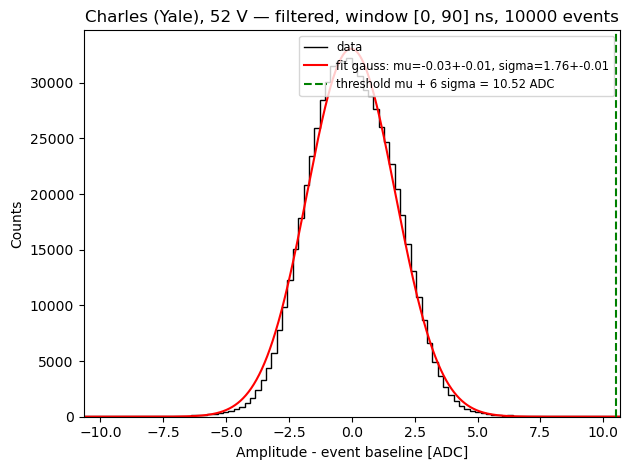

[Alice (Yale), 52 V] 680000 campioni (0.55% fuori dal range -10.8, 10.8)
    Fit gaussiano: mu = -0.048 +- 0.011 ADC   sigma = 1.767 +- 0.011 ADC


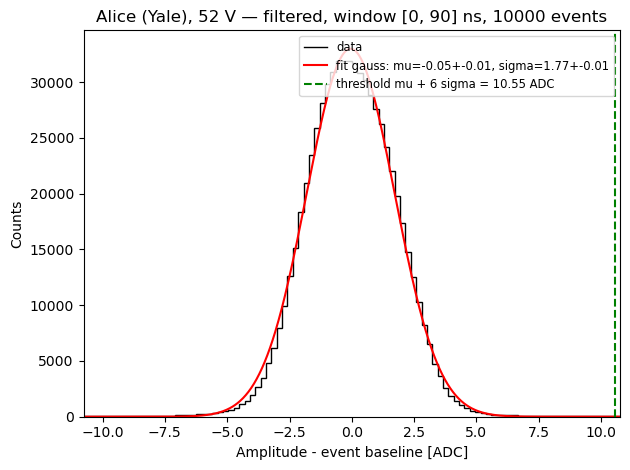

[Bob (Yale), 52 V] 680000 campioni (0.42% fuori dal range -10.8, 10.8)
    Fit gaussiano: mu = -0.029 +- 0.013 ADC   sigma = 1.767 +- 0.013 ADC


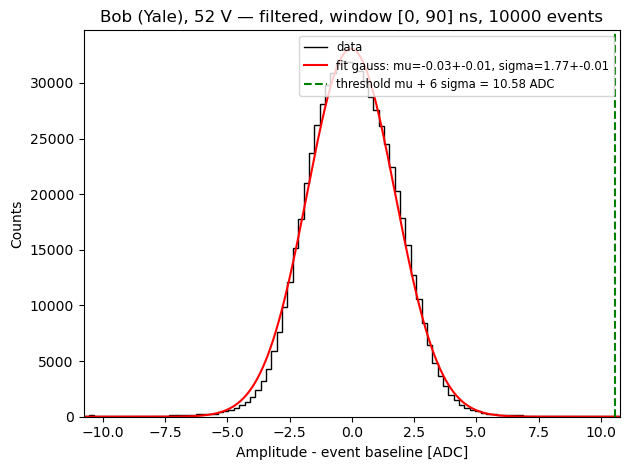

In [67]:
# === Distribuzione delle ampiezze nella finestra prima del segnale, su tutti gli eventi, con fit gaussiano ===
# Sulle WF FILTRATE (wf_filt_canali), sempre, indipendentemente da
# USA_FILTRATE: il filtro cambia molto la sigma -- su ch18 la riga a ~95 MHz
# da' ~15 ADC grezzi contro ~2.5 filtrati -- e le ampiezze dei vari run vanno
# confrontate tutte nello stesso modo.
# La baseline di ogni evento e' gia' tolta (cella della baseline). Se la
# finestra e' la stessa della baseline, ogni evento ha media zero per
# costruzione: la sigma e' il rumore DENTRO l'evento, senza lo spostamento
# della baseline da un evento all'altro.
FINESTRA_AMP_NS = BASELINE_NS

# Range dell'istogramma: esplicito, per la ragione scritta nell'originale (con
# il range automatico pochi campioni anomali lo allargano, i bin si svuotano e
# la covarianza di curve_fit degenera). Ma non fisso per tutti: si prende
# +-AMP_RANGE_NSIGMA sigma robuste (dalla MAD) attorno a zero, perche' la
# sigma cambia fra canali. AMP_RANGE = (-10, 10) lo impone fisso.
AMP_RANGE = None
AMP_RANGE_NSIGMA = 6
n_bins_amp = 100
N_EVENTI_STIMA = 50000       # eventi per stimare la larghezza; l'istogramma usa tutti gli eventi


def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))


t_amp = np.arange(N_SAMPLES) * SAMPLING_TIME
mask_t_amp = (t_amp >= FINESTRA_AMP_NS[0]) & (t_amp <= FINESTRA_AMP_NS[1])
print(f"Finestra [{FINESTRA_AMP_NS[0]:g}, {FINESTRA_AMP_NS[1]:g}] ns: {mask_t_amp.sum()} campioni per evento; "
      f"WF filtrate ({filtri}), baseline per evento sottratta")

fit_amp = {}                 # canale -> (mu, err_mu, sigma, err_sigma) [ADC]
for ch in wf_filt_canali:
    wf = wf_filt_canali[ch]

    if AMP_RANGE is not None:
        amp_range = AMP_RANGE
    else:
        stima = wf[:N_EVENTI_STIMA, mask_t_amp].astype(np.float64).ravel()
        sigma_mad = 1.4826 * np.median(np.abs(stima - np.median(stima)))
        del stima
        mezzo = max(AMP_RANGE_NSIGMA * sigma_mad, 5.0)
        amp_range = (-mezzo, mezzo)
    edges_amp = np.linspace(amp_range[0], amp_range[1], n_bins_amp + 1)
    centers_amp = 0.5 * (edges_amp[:-1] + edges_amp[1:])

    # Istogramma a blocchi: a run intera i campioni nella finestra sono ~2e8 per
    # canale, e appiattirli tutti in float64 vorrebbe GB. I blocchi sommano gli stessi conteggi.
    counts_amp = np.zeros(n_bins_amp)
    n_tot = n_fuori = 0
    for i0 in range(0, wf.shape[0], BLOCCO_EVENTI):
        v = wf[i0:i0 + BLOCCO_EVENTI, mask_t_amp].astype(np.float64).ravel()
        counts_amp += np.histogram(v, bins=edges_amp)[0]
        n_tot += v.size
        n_fuori += np.count_nonzero((v < edges_amp[0]) | (v > edges_amp[-1]))

    # p0 dai momenti dell'istogramma: e' l'equivalente di media e std dei valori nel range
    m1 = np.average(centers_amp, weights=counts_amp)
    m2 = np.average(centers_amp ** 2, weights=counts_amp)
    p0_amp = [counts_amp.max(), m1, np.sqrt(m2 - m1 ** 2)]
    popt_amp, pcov_amp = curve_fit(gauss, centers_amp, counts_amp, p0=p0_amp)
    A_amp_fit, mu_amp_fit, sigma_amp_fit = popt_amp
    sigma_amp_fit = abs(sigma_amp_fit)     # la gaussiana e' pari in sigma: il fit puo' darla negativa
    mu_amp_err, sigma_amp_err = np.sqrt(np.diag(pcov_amp))[1:]
    fit_amp[ch] = (mu_amp_fit, mu_amp_err, sigma_amp_fit, sigma_amp_err)

    print(f"[{DESCRIZIONE[ch]}] {n_tot} campioni ({100 * n_fuori / n_tot:.2f}% fuori dal range "
          f"{edges_amp[0]:.1f}, {edges_amp[-1]:.1f})")
    print(f"    Fit gaussiano: mu = {mu_amp_fit:.3f} +- {mu_amp_err:.3f} ADC   "
          f"sigma = {sigma_amp_fit:.3f} +- {sigma_amp_err:.3f} ADC")

    if not mostra(ch):
        continue
    plt.figure()
    plt.stairs(counts_amp, edges_amp, color='k', label='data')
    x_fit_amp = np.linspace(edges_amp[0], edges_amp[-1], 1000)
    plt.plot(x_fit_amp, gauss(x_fit_amp, *popt_amp), color='red', lw=1.5,
             label=f'fit gauss: mu={mu_amp_fit:.2f}+-{mu_amp_err:.2f}, sigma={sigma_amp_fit:.2f}+-{sigma_amp_err:.2f}')
    # soglia di rivelazione del canale (NSIGMA_YALE e' nella cella di config)
    soglia_amp = mu_amp_fit + NSIGMA_YALE * sigma_amp_fit
    plt.axvline(soglia_amp, color='green', ls='--', lw=1.5,
                label=f'threshold mu + {NSIGMA_YALE} sigma = {soglia_amp:.2f} ADC')
    plt.xlabel('Amplitude - event baseline [ADC]')
    plt.ylabel('Counts')
    plt.xlim(edges_amp[0], edges_amp[-1])
    plt.title(f"{DESCRIZIONE[ch]} — filtered, window [{FINESTRA_AMP_NS[0]:g}, {FINESTRA_AMP_NS[1]:g}] ns, {wf.shape[0]} events")
    plt.legend(loc='upper right', fontsize='small')
    plt.tight_layout()
    plt.show()

In [68]:
# === Yale: soglie mu + 4*sigma ed efficienza di ogni pannello ===
# Come la cella dell'efficienza dei dati nuovi -- stessa soglia mu + NSIGMA_YALE*sigma
# dal fit del pannello, stesso criterio "massimo nel segnale sopra soglia",
# stessi errori -- con un'unica differenza: manca la coincidenza a posteriori
# degli altri due pannelli (i tre pannelli sono in file diversi), e il
# riferimento e' TUTTO il file, sul presupposto che il trigger esterno sia gia'
# la coincidenza degli altri due pannelli.
from scipy.stats import beta

t_sig = np.arange(N_SAMPLES) * SAMPLING_TIME
# Finestra dell'impulso di ogni canale: la stessa su cui si integra la carica
# (cella della carica Yale). Fuori da questa finestra niente conta.
mask_finestra = {ch: (t_sig >= FINESTRA_CARICA_NS[ch][0]) & (t_sig <= FINESTRA_CARICA_NS[ch][1]) for ch in CANALI}

FIT_AMP_YALE = fit_amp       # fit_amp e' ora quello Yale (cella delle ampiezze)
soglia_yale = {}
sopra_yale = {}
massimo_yale = {}            # canale -> massimo nel segnale per evento [ADC]
larghezza_yale = {}          # canale -> tratto piu' lungo sopra soglia nel segnale per evento [ns]
EFF_YALE = {}                # canale dati nuovi -> (efficienza, errore binomiale, CP basso, CP alto)
alfa = 1 - 0.682689          # copertura di +-1 sigma
for ch in CANALI:
    wf = wf_filt_canali[ch]
    mu_amp_fit, _, sigma_amp_fit, _ = fit_amp[ch]
    soglia_yale[ch] = mu_amp_fit + NSIGMA_YALE * sigma_amp_fit
    # Massimo a blocchi: wf[:, mask].max() copierebbe la sezione di tutta la run
    massimo = np.empty(wf.shape[0], dtype=np.float32)
    for i0 in range(0, wf.shape[0], BLOCCO_EVENTI):
        massimo[i0:i0 + BLOCCO_EVENTI] = wf[i0:i0 + BLOCCO_EVENTI, mask_finestra[ch]].max(axis=-1)
    massimo_yale[ch] = massimo
    # Stesse condizioni di impulso valido dei dati nuovi, ma coi parametri della cella dei
    # parametri Yale: larghezza e ampiezza massima. La coincidenza in tempo non c'e': un solo pannello per file.
    larghezza_yale[ch] = larghezza_massima_ns(wf, soglia_yale[ch], mask_finestra[ch])
    sopra_yale[ch] = (massimo > soglia_yale[ch]) & (larghezza_yale[ch] >= T_MIN_LARGHEZZA_YALE_NS)
    if AMP_MAX_YALE_ADC is not None:
        sopra_yale[ch] &= massimo <= AMP_MAX_YALE_ADC
    if RICHIEDI_Q_POSITIVA_YALE:
        sopra_yale[ch] &= Q_SEGNALE[ch] > 0

    n_tot = len(massimo)
    n = int(sopra_yale[ch].sum())
    eff = n / n_tot
    # Come per i dati nuovi: binomiale, con Clopper-Pearson a fianco perche'
    # il binomiale va a zero quando l'efficienza e' vicina a 1
    eff_err = np.sqrt(eff * (1 - eff) / n_tot)
    cp_lo = beta.ppf(alfa / 2, n, n_tot - n + 1) if n > 0 else 0.0
    cp_hi = beta.ppf(1 - alfa / 2, n + 1, n_tot - n) if n < n_tot else 1.0
    EFF_YALE[ch] = (eff, eff_err, cp_lo, cp_hi)
    print(f"[{DESCRIZIONE[ch]}] soglia (mu + {NSIGMA_YALE}*sigma) = {soglia_yale[ch]:.3f} ADC "
          f"(mu = {mu_amp_fit:.3f}, sigma = {sigma_amp_fit:.3f}), pulse window [{FINESTRA_CARICA_NS[ch][0]:.0f}, {FINESTRA_CARICA_NS[ch][1]:.0f}] ns")
    print(f"    Events with valid signal > thr (width >= {T_MIN_LARGHEZZA_YALE_NS:g} ns, max <= {AMP_MAX_YALE_ADC} ADC): {n} over {n_tot}")
    print(f"    Efficienza = {n}/{n_tot} = {eff:.4f} +- {eff_err:.4f}  (Clopper-Pearson 68%: [{cp_lo:.4f}, {cp_hi:.4f}])")

[Charles (Yale), 52 V] soglia (mu + 6*sigma) = 10.516 ADC (mu = -0.025, sigma = 1.757), pulse window [109, 1057] ns
    Events with valid signal > thr (width >= 18.7 ns, max <= None ADC): 9706 over 10000
    Efficienza = 9706/10000 = 0.9706 +- 0.0017  (Clopper-Pearson 68%: [0.9688, 0.9723])
[Alice (Yale), 52 V] soglia (mu + 6*sigma) = 10.552 ADC (mu = -0.048, sigma = 1.767), pulse window [108, 1044] ns
    Events with valid signal > thr (width >= 18.7 ns, max <= None ADC): 9650 over 10000
    Efficienza = 9650/10000 = 0.9650 +- 0.0018  (Clopper-Pearson 68%: [0.9631, 0.9668])
[Bob (Yale), 52 V] soglia (mu + 6*sigma) = 10.575 ADC (mu = -0.029, sigma = 1.767), pulse window [109, 1065] ns
    Events with valid signal > thr (width >= 18.7 ns, max <= None ADC): 9681 over 10000
    Efficienza = 9681/10000 = 0.9681 +- 0.0018  (Clopper-Pearson 68%: [0.9662, 0.9699])


Charles (Yale), 52 V: soglia mu + 6*sigma = 10.52 ADC

  1) LARGHEZZA -> T_MIN_LARGHEZZA_NS
     Frazione di eventi con un tratto sopra soglia lungo ALMENO T.
     'rumore' = finestra di baseline [0, 90] ns, dove segnale non c'e' (tutti gli eventi sopra soglia sono falsi).
     'rumore, regione segnale' = stima per l'intera finestra dell'impulso (712 campioni contro 68): 1-(1-p)^(712/68),
        assume campioni di rumore indipendenti, e' una stima.
     'segnale' = finestra dell'impulso, tutti gli eventi del file.
       T [ns]   rumore (baseline)   rumore, regione segnale    segnale
          1.3               4.48%                    38.12%      97.1%
          2.7               2.45%                    22.87%      97.1%
          4.0               1.22%                    12.06%      97.1%
          6.7               0.24%                     2.48%      97.1%
          8.0               0.24%                     2.48%      97.1%
          9.3               0.12%                    

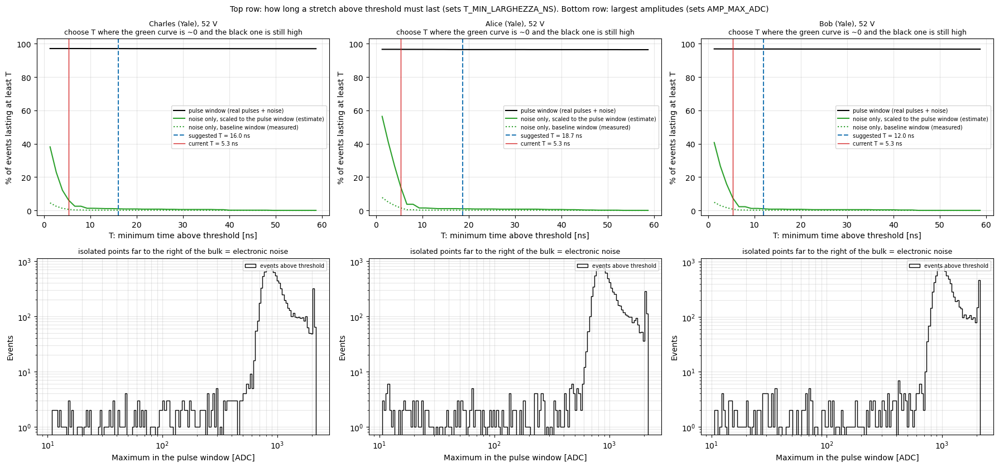

In [65]:
# === Yale: Come scegliere i tagli: larghezza, ampiezza ===
# Questa cella NON cambia nessun risultato: misura e suggerisce i valori dei
# parametri della cella dei parametri Yale (T_MIN_LARGHEZZA_YALE_NS, AMP_MAX_YALE_ADC).
# Per ogni parametro stampa: cosa misura, cosa leggere nel grafico, e un valore
# SUGGERITO. Il valore lo imposti tu nella cella dei parametri Yale.
#
# Domanda di fondo: un evento "sopra soglia" e' un impulso vero o rumore?
#  1) LARGHEZZA (T_MIN_LARGHEZZA_YALE_NS): un impulso vero resta sopra soglia a lungo,
#     una fluttuazione di rumore solo per pochi ns. Per ogni T si confronta
#     quanti eventi hanno un tratto sopra soglia lungo almeno T in una zona SENZA
#     segnale (la finestra di baseline: li' ogni evento sopra soglia e' rumore)
#     e nella finestra dell'impulso. Si sceglie il T piu' piccolo che elimina
#     (quasi) tutto il rumore tenendo (quasi) tutto il segnale.
#  2) AMPIEZZA (AMP_MAX_YALE_ADC): eventi con un massimo enorme, isolato dagli altri,
#     non sono impulsi del rivelatore ma rumore elettronico.
# I grafici sono in inglese come gli altri, le spiegazioni stampate in italiano.
# (Dati Yale: un pannello per file, niente coincidenza in tempo.)

T_TABELLA = [0.4, 2, 4, 6, 8, 10, 15, 20, 30, 40]   # ns, solo per la tabella stampata

t_diag = np.arange(N_SAMPLES) * SAMPLING_TIME
mask_t_baseline = (t_diag >= BASELINE_NS[0]) & (t_diag <= BASELINE_NS[1])
n_camp_bl = int(mask_t_baseline.sum())
n_camp_sig = {ch: int(mask_finestra[ch].sum()) for ch in CANALI}   # campioni della finestra dell'impulso di ogni canale
T_GRIGLIA = np.arange(SAMPLING_TIME, 60.0, SAMPLING_TIME)


T_sugg, amp_sugg, amp_bulk = {}, {}, {}
for ch in CANALI:
    nome = DESCRIZIONE[ch]
    larg_rumore = larghezza_massima_ns(wf_filt_canali[ch], soglia_yale[ch], mask_t_baseline)
    larg_sig = larghezza_yale[ch]
    campione = np.ones(len(larg_sig), dtype=bool)
    print("=" * 100)
    print(f"{nome}: soglia mu + {NSIGMA_YALE}*sigma = {soglia_yale[ch]:.2f} ADC")

    # ---- 1) larghezza ----
    p_bl = frazione_ge(larg_rumore, T_GRIGLIA)                      # rumore, nella finestra di baseline
    p_reg = 1 - (1 - p_bl) ** (n_camp_sig[ch] / n_camp_bl)              # stima per tutta la finestra dell'impulso
    p_sig = frazione_ge(larg_sig[campione], T_GRIGLIA)              # eventi nella finestra dell'impulso
    print(f"\n  1) LARGHEZZA -> T_MIN_LARGHEZZA_YALE_NS")
    print(f"     Frazione di eventi con un tratto sopra soglia lungo ALMENO T.")
    print(f"     'rumore' = finestra di baseline [{BASELINE_NS[0]:g}, {BASELINE_NS[1]:g}] ns, dove segnale non c'e' (tutti gli eventi sopra soglia sono falsi).")
    print(f"     'rumore, regione segnale' = stima per l'intera finestra dell'impulso ({n_camp_sig[ch]} campioni contro {n_camp_bl}): 1-(1-p)^({n_camp_sig[ch]}/{n_camp_bl}),")
    print(f"        assume campioni di rumore indipendenti, e' una stima.")
    print(f"     'segnale' = finestra dell'impulso, {"tutti gli eventi del file"}.")
    print(f"     {'T [ns]':>8} {'rumore (baseline)':>19} {'rumore, regione segnale':>25} {'segnale':>10}")
    for t_ in T_TABELLA:
        j = np.argmin(np.abs(T_GRIGLIA - t_))
        print(f"     {T_GRIGLIA[j]:>8.1f} {100 * p_bl[j]:>18.2f}% {100 * p_reg[j]:>24.2f}% {100 * p_sig[j]:>9.1f}%")
    ok = np.flatnonzero(p_reg <= RUMORE_RESIDUO_MAX_YALE)
    if len(ok):
        T_sugg[ch] = float(T_GRIGLIA[ok[0]])
        tenuto = p_sig[ok[0]] / p_sig[0] if p_sig[0] > 0 else np.nan
        print(f"     --> T suggerito per questo canale: {T_sugg[ch]:.1f} ns "
              f"(rumore residuo stimato {100 * p_reg[ok[0]]:.2f}% , segnale tenuto {100 * tenuto:.1f}% di quello a T = 1 campione)")
        if tenuto < 0.9:
            print("     !! il taglio toglie piu' del 10% del segnale: la separazione rumore/segnale e' poco netta a questa soglia")
    else:
        T_sugg[ch] = None
        print(f"     --> nessun T fino a {T_GRIGLIA[-1]:.0f} ns porta il rumore stimato sotto {100 * RUMORE_RESIDUO_MAX_YALE:g}%")

    # ---- 2) ampiezza ----
    m = massimo_yale[ch]
    sopra_m = np.flatnonzero(m > soglia_yale[ch])
    top = sopra_m[np.argsort(m[sopra_m])[::-1][:10]]
    a = m[top]
    print(f"\n  2) AMPIEZZA -> AMP_MAX_YALE_ADC")
    print(f"     Massimo nella finestra dell'impulso degli eventi sopra soglia ({len(sopra_m)} eventi): "
          f"mediana {np.median(m[sopra_m]):.0f}, 99% {np.percentile(m[sopra_m], 99):.0f}, 99.9% {np.percentile(m[sopra_m], 99.9):.0f}, max {m[sopra_m].max():.0f} ADC")
    print(f"     I 10 eventi col massimo piu' alto (se uno e' molto piu' in alto degli altri e' sospetto):")
    for ev, v in zip(top, a):
        print(f"        evento {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]}): massimo {v:.0f} ADC, tratto sopra soglia {larg_sig[ev]:.1f} ns")
    rapporti = a[:-1] / a[1:]
    salto = np.flatnonzero(rapporti >= 2)
    if len(salto):
        i_ = salto[0]
        amp_sugg[ch] = float(np.sqrt(a[i_] * a[i_ + 1]))
        amp_bulk[ch] = float(a[i_ + 1])
        print(f"     --> fra i 10 piu' alti c'e' un salto di un fattore >= 2: {a[i_]:.0f} ADC contro {a[i_ + 1]:.0f} ADC dell'evento dopo. "
              f"Gli eventi sopra il salto sono {i_ + 1}. AMP_MAX_YALE_ADC suggerito: {amp_sugg[ch]:.0f} ADC (taglia quei {i_ + 1})")
    else:
        amp_sugg[ch] = None
        amp_bulk[ch] = float(a[0]) if len(a) else 0.0
        print("     --> nessun evento isolato fra i primi 10 (nessun salto di un fattore 2): AMP_MAX_YALE_ADC non sembra servire per questo canale")


# ---- Riepilogo ----
print("=" * 100)
print("RIEPILOGO: valori suggeriti da impostare nella cella dei parametri Yale")
t_vals = [v for v in T_sugg.values() if v is not None]
print(f"  T_MIN_LARGHEZZA_YALE_NS = {max(t_vals):.1f}   (il piu' grande fra i canali: {T_sugg}; ora impostato: {T_MIN_LARGHEZZA_YALE_NS:g})"
      if t_vals else "  T_MIN_LARGHEZZA_YALE_NS: nessun valore suggerito")
con_outlier = {c: v for c, v in amp_sugg.items() if v is not None}
if con_outlier:
    a_min = min(con_outlier.values())
    print(f"  AMP_MAX_YALE_ADC = {a_min:.0f}   (ora impostato: {AMP_MAX_YALE_ADC})")
    for c, bulk in amp_bulk.items():
        if bulk >= a_min:
            print(f"  !! ch{c} ha eventi normali fino a {bulk:.0f} ADC, sopra questo limite: AMP_MAX e' uno solo per tutti i canali, controllare")
else:
    print(f"  AMP_MAX_YALE_ADC: nessun evento isolato fuori scala trovato (ora impostato: {AMP_MAX_YALE_ADC})")

# ---- Grafici ----
canali_diag = [ch for ch in CANALI if mostra(ch)]
if canali_diag:
    fig, assi = plt.subplots(2, len(canali_diag), figsize=(6 * len(canali_diag), 8.5), squeeze=False)
    fig.suptitle("Top row: how long a stretch above threshold must last (sets T_MIN_LARGHEZZA_YALE_NS). "
                 "Bottom row: largest amplitudes (sets AMP_MAX_YALE_ADC)", fontsize=10)
    for col, ch in enumerate(canali_diag):
        ax = assi[0, col]
        larg_rumore = larghezza_massima_ns(wf_filt_canali[ch], soglia_yale[ch], mask_t_baseline)
        campione = np.ones(len(larg_sig), dtype=bool)
        p_bl = frazione_ge(larg_rumore, T_GRIGLIA)
        p_reg = 1 - (1 - p_bl) ** (n_camp_sig[ch] / n_camp_bl)
        p_sig = frazione_ge(larghezza_yale[ch][campione], T_GRIGLIA)
        ax.plot(T_GRIGLIA, 100 * p_sig, color="k", label="pulse window (real pulses + noise)")
        ax.plot(T_GRIGLIA, 100 * p_reg, color="tab:green", label="noise only, scaled to the pulse window (estimate)")
        ax.plot(T_GRIGLIA, 100 * p_bl, color="tab:green", ls=":", label="noise only, baseline window (measured)")
        if T_sugg.get(ch) is not None:
            ax.axvline(T_sugg[ch], color="tab:blue", ls="--", label=f"suggested T = {T_sugg[ch]:.1f} ns")
        if T_MIN_LARGHEZZA_YALE_NS > 0:
            ax.axvline(T_MIN_LARGHEZZA_YALE_NS, color="tab:red", ls="-", lw=1, label=f"current T = {T_MIN_LARGHEZZA_YALE_NS:g} ns")
        ax.set_xlabel("T: minimum time above threshold [ns]")
        ax.set_ylabel("% of events lasting at least T")
        ax.set_title(f"{DESCRIZIONE[ch]}\nchoose T where the green curve is ~0 and the black one is still high", fontsize=9)
        ax.set_ylim(-3, 103); ax.grid(True, alpha=0.3); ax.legend(fontsize=7)

        ax = assi[1, col]
        m = massimo_yale[ch]
        s_ = m > soglia_yale[ch]
        ax.hist(m[s_], bins=np.logspace(np.log10(soglia_yale[ch]), np.log10(max(m.max(), 2 * soglia_yale[ch])), 150),
                histtype="step", color="k", label="events above threshold")
        if amp_sugg.get(ch) is not None:
            ax.axvline(amp_sugg[ch], color="tab:blue", ls="--", label=f"suggested AMP_MAX = {amp_sugg[ch]:.0f} ADC")
        if AMP_MAX_YALE_ADC is not None:
            ax.axvline(AMP_MAX_YALE_ADC, color="tab:red", lw=1, label=f"current AMP_MAX = {AMP_MAX_YALE_ADC:g} ADC")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("Maximum in the pulse window [ADC]"); ax.set_ylabel("Events")
        ax.set_title("isolated points far to the right of the bulk = electronic noise", fontsize=9)
        ax.grid(True, alpha=0.3, which="both"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()


[Charles (Yale), 52 V] Q minima -341116, mediana 228359; eventi con Q <= 25000: 359 su 10000 (3.6%)


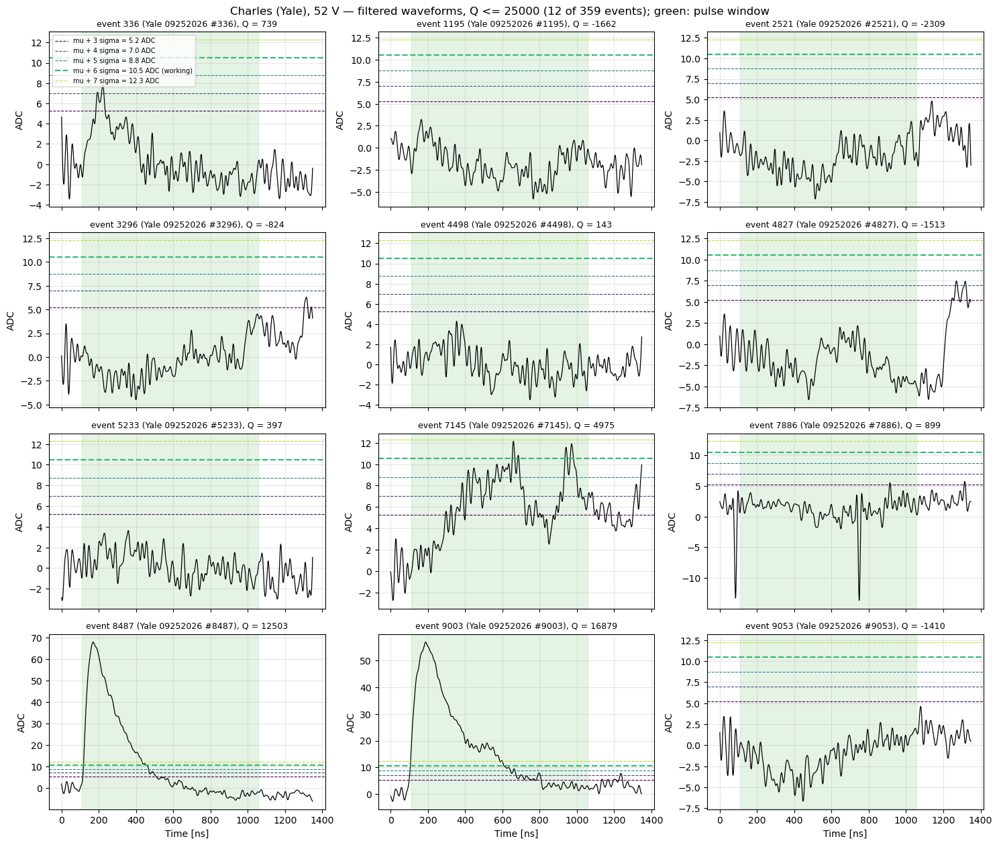

[Alice (Yale), 52 V] Q minima -1248776, mediana 220616; eventi con Q <= 60000: 466 su 10000 (4.7%)


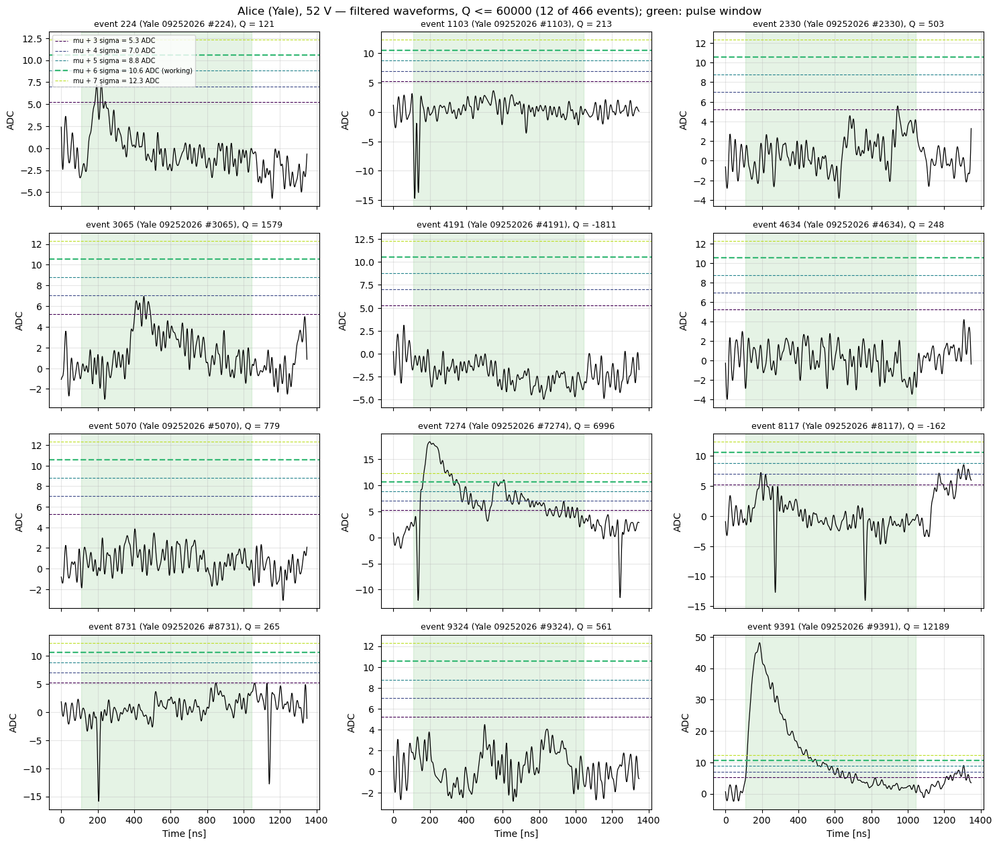

[Bob (Yale), 52 V] Q minima -465982, mediana 263537; eventi con Q <= 60000: 434 su 10000 (4.3%)


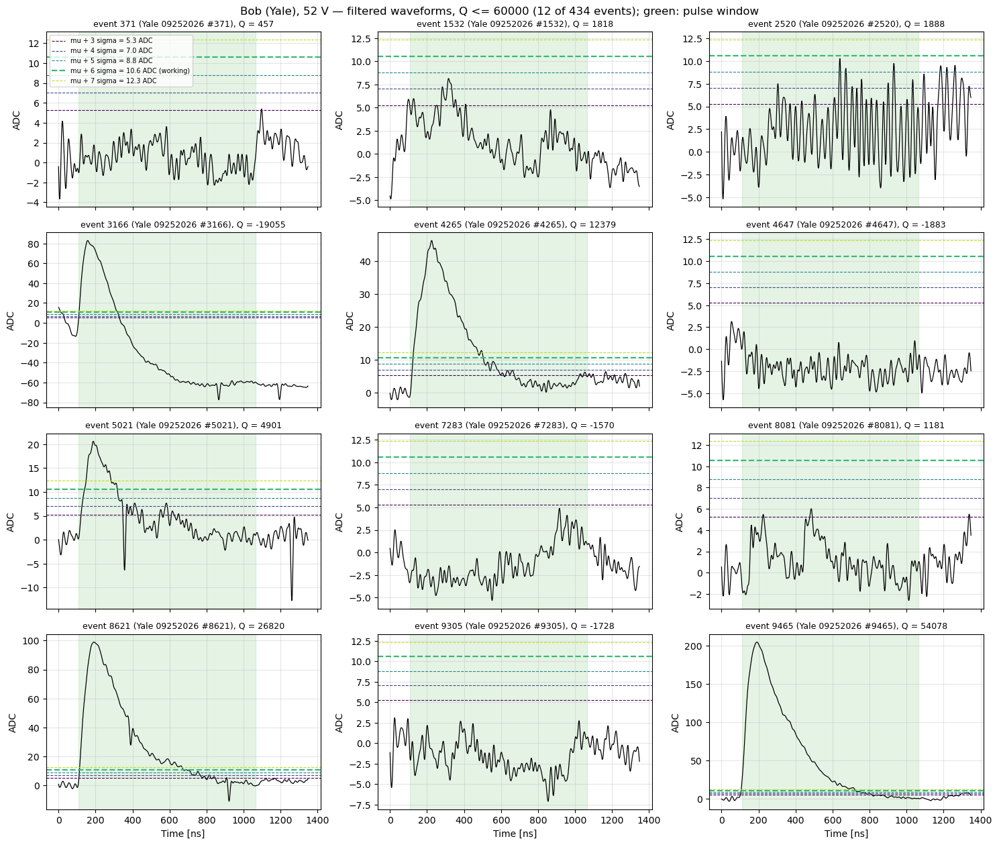

In [69]:
# === Yale: waveform filtrate degli eventi con Q <= soglia, con le soglie mu + N*sigma ===
# Solo WF filtrate (baseline per evento sottratta), un grafico per rivelatore.
# Q e' la carica nella finestra dell'impulso (Q_SEGNALE), selezione inclusiva.
# Le soglie sono quelle della cella dello scan dei dati nuovi, qui sui dati Yale: mu + N*sigma dal fit gaussiano
# delle ampiezze nella finestra di baseline (fit_amp) del canale, per N in
# SCAN_NSIGMA; quella di lavoro (NSIGMA_YALE) e' tratteggiata piu' marcata.
SCAN_NSIGMA = [3, 4, 5, 6, 7]  # come nello scan in soglia dei dati nuovi
# Limite di Q [ADC ns], incluso, UNO PER RIVELATORE: gli spettri di carica dei
# rivelatori non partono dallo stesso valore (Alice e Bob da ~50000), e con un
# limite solo uno dei tre non avrebbe nessun evento. Valori di partenza: Charles
# 25000, Alice e Bob appena sopra l'inizio dello spettro; da aggiustare guardando
# la Q minima che la cella stampa per ogni rivelatore.
Q_MAX_WF_SOGLIE = {"Charles": 25000, "Alice": 60000, "Bob": 60000}
N_WF_SOGLIE = 12              # waveform mostrate per rivelatore (a caso fra le selezionate)
SEED_WF_SOGLIE = 1

colori_soglie = dict(zip(SCAN_NSIGMA, plt.cm.viridis(np.linspace(0.0, 0.9, len(SCAN_NSIGMA)))))
for ch in canali_q:
    q = Q_SEGNALE[ch]
    q_max = Q_MAX_WF_SOGLIE.get(RIVELATORI[ch], 25000)
    idx = np.flatnonzero(q <= q_max)
    print(f"[{DESCRIZIONE[ch]}] Q minima {q.min():.0f}, mediana {np.median(q):.0f}; "
          f"eventi con Q <= {q_max:g}: {len(idx)} su {len(q)} ({100 * len(idx) / len(q):.1f}%)")
    if len(idx) == 0:
        print(f"    nessun evento: alzare il limite di {RIVELATORI[ch]} in Q_MAX_WF_SOGLIE sopra {q.min():.0f}")
    if len(idx) == 0:
        continue
    rng = np.random.default_rng(SEED_WF_SOGLIE)
    scelti = np.sort(rng.choice(idx, min(N_WF_SOGLIE, len(idx)), replace=False))
    mu_s, _, sigma_s, _ = fit_amp[ch]

    ncol = 3
    nrow = int(np.ceil(len(scelti) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow), sharex=True, squeeze=False)
    for ax, ev in zip(axes.flat, scelti):
        ax.plot(t_q, wf_filt_canali[ch][ev], lw=0.9, color="k")
        for n_sigma in SCAN_NSIGMA:
            lavoro = n_sigma == NSIGMA_YALE
            ax.axhline(mu_s + n_sigma * sigma_s, color=colori_soglie[n_sigma], ls="--",
                       lw=1.6 if lavoro else 0.8,
                       label=f"mu + {n_sigma} sigma = {mu_s + n_sigma * sigma_s:.1f} ADC" + (" (working)" if lavoro else ""))
        ax.axvspan(*FINESTRA_CARICA_NS[ch], color="tab:green", alpha=0.12)
        ax.set_title(f"event {ev} ({RUN_FILES[FILE_EVENTO[ev]][:15]} #{EVENTO_NEL_FILE[ev]}), Q = {q[ev]:.0f}", fontsize=9)
        ax.set_ylabel("ADC")
        ax.grid(True, alpha=0.3)
    axes.flat[0].legend(fontsize=7, loc="upper left")
    for ax in axes.flat[len(scelti):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Time [ns]")
    fig.suptitle(f"{DESCRIZIONE[ch]} — filtered waveforms, Q <= {q_max:g} "
                 f"({len(scelti)} of {len(idx)} events); green: pulse window")
    plt.tight_layout()
    plt.show()


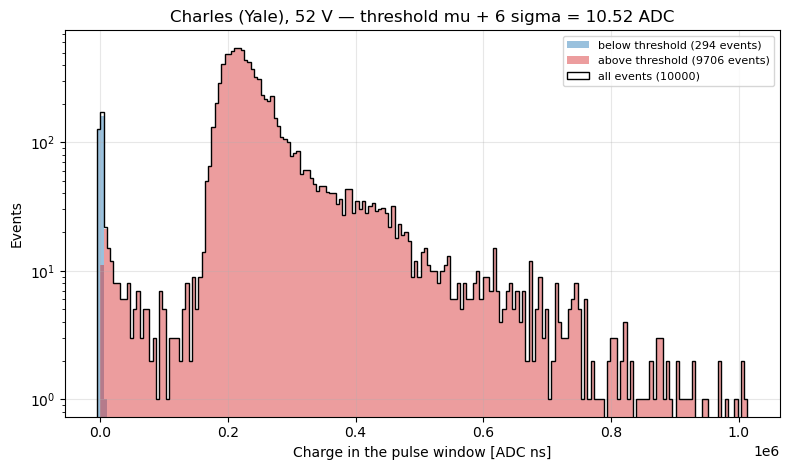

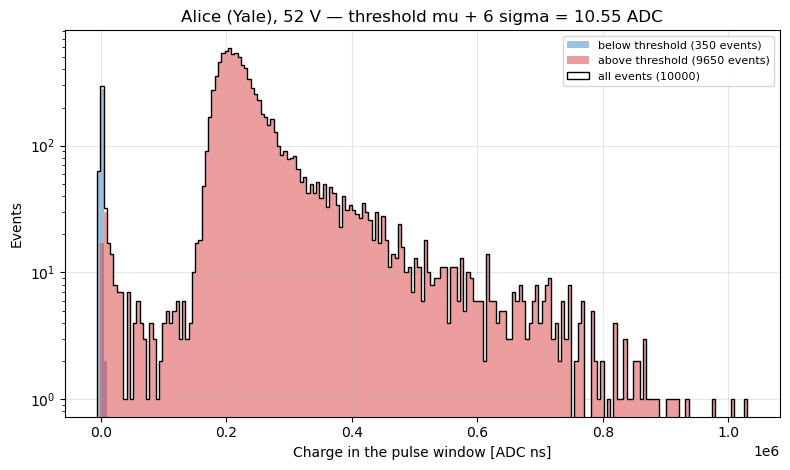

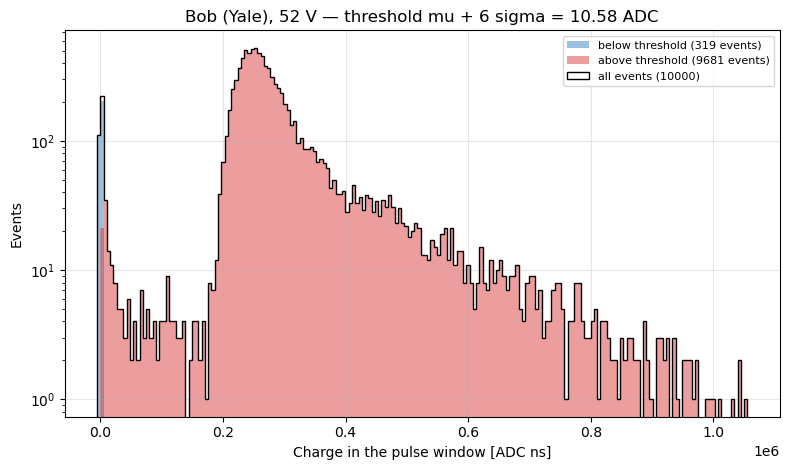

In [71]:
# === Yale: distribuzione di Q di ogni rivelatore, divisa in eventi sotto e sopra soglia ===
# Un pannello per rivelatore. Nero: tutti gli eventi. Colorati: gli stessi
# eventi divisi in base a "massimo nel segnale sopra la soglia mu + NSIGMA_YALE*sigma"
# del proprio canale (sopra_yale, dalla cella dell'efficienza Yale): rosso sopra soglia,
# blu sotto. I due istogrammi riempiti sommano all'istogramma nero.
# Linea verticale: il limite di quel rivelatore in Q_MAX_WF_SOGLIE (cella delle WF con soglie).
for ch in canali_q:
    q = Q_SEGNALE[ch]
    s = sopra_yale[ch]
    lo, hi = np.percentile(q, (0.05, 99.95))
    bins = np.linspace(lo, hi, 200)
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.hist(q[~s], bins=bins, color="tab:blue", alpha=0.45,
            label=f"below threshold ({int((~s).sum())} events)")
    ax.hist(q[s], bins=bins, color="tab:red", alpha=0.45,
            label=f"above threshold ({int(s.sum())} events)")
    ax.hist(q, bins=bins, histtype="step", color="k", label=f"all events ({len(q)})")
    q_max = Q_MAX_WF_SOGLIE.get(RIVELATORI[ch], 25000)
#     ax.axvline(q_max, color="tab:gray", ls="--", lw=1, label=f"Q = {q_max:g}")
    ax.set_yscale("log")
    ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
    ax.set_title(f"{DESCRIZIONE[ch]} — threshold mu + {NSIGMA_YALE} sigma = {soglia_yale[ch]:.2f} ADC")
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


Picco della carica [ADC ns] (massimo dell'istogramma smussato):
  Charles  picco    214367  mediana    228359  media    254844  (10000 eventi)
  Alice    picco    204338  mediana    220616  media    245412  (10000 eventi)
  Bob      picco    249468  mediana    263537  media    290595  (10000 eventi)


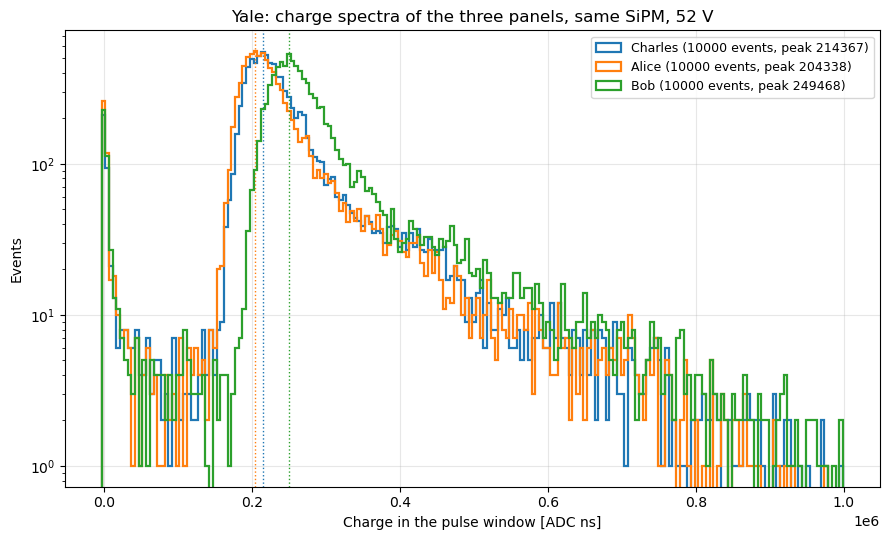

In [72]:
# === Yale: i tre spettri di carica in un unico grafico ===
# Q_SEGNALE della cella della carica Yale (somma dei campioni x dt, ADC ns, nella finestra
# lunga di ogni canale: stesso criterio dei dati nuovi e del notebook del guadagno). In questi dati lo STESSO SiPM e' stato usato su tutti e tre
# gli scintillatori: guadagno e PDE sono uguali, quindi le posizioni dei picchi si
# confrontano direttamente, senza i fattori di equalizzazione della cella 9 (che valgono
# per i tre SiPM diversi dei dati nuovi e qui non vanno applicati). La finestra
# di integrazione e' per canale perche' dipende dal segnale, ma con lo stesso criterio.
# Picco = massimo dell'istogramma smussato (la moda), non la media, che la coda di Landau sposta.
from scipy.ndimage import gaussian_filter1d

LOG_Y = True                 # True = scala logaritmica in y
N_BIN_Q = 200
ORDINE_Q = ["Charles", "Alice", "Bob"]
COLORI_Q = {"Charles": "tab:blue", "Alice": "tab:orange", "Bob": "tab:green"}

_ch_di = {nome: ch for ch, nome in RIVELATORI.items()}
_pannelli = [n for n in ORDINE_Q if n in _ch_di]
# Stessi bin per tutti: gli istogrammi si sovrappongono e si confrontano bin per bin
_hi = max(np.percentile(Q_SEGNALE[_ch_di[n]], 99.9) for n in _pannelli)
_lo = min(np.percentile(Q_SEGNALE[_ch_di[n]], 0.1) for n in _pannelli)
_bins = np.linspace(_lo, _hi, N_BIN_Q + 1)
_c = 0.5 * (_bins[1:] + _bins[:-1])

fig, ax = plt.subplots(figsize=(9, 5.5))
print("Picco della carica [ADC ns] (massimo dell'istogramma smussato):")
for nome in _pannelli:
    q = Q_SEGNALE[_ch_di[nome]]
    h, _ = np.histogram(q, bins=_bins)
    k = int(np.argmax(gaussian_filter1d(h.astype(float), 2)[5:])) + 5
    ax.hist(q, bins=_bins, histtype="step", lw=1.6, color=COLORI_Q[nome],
            label=f"{nome} ({len(q)} events, peak {_c[k]:.0f})")
    ax.axvline(_c[k], color=COLORI_Q[nome], ls=":", lw=1)
    print(f"  {nome:8s} picco {_c[k]:9.0f}  mediana {np.median(q):9.0f}  media {q.mean():9.0f}  ({len(q)} eventi)")
if LOG_Y:
    ax.set_yscale("log")
ax.set_xlabel("Charge in the pulse window [ADC ns]"); ax.set_ylabel("Events")
ax.set_title(f"Yale: charge spectra of the three panels, same SiPM, {VBIAS:g} V")
ax.grid(True, alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


Fit Landau (x) gaussiana dei muoni, Q >= 0.65 x moda dell'istogramma fino a fine spettro (overflow compreso), verosimiglianza di Poisson
  Charles : picco    211541 ADC ns (moda istogramma 213576), FWHM/picco 0.32; MPV 207237 +- 372, xi 14396 +- 274, sigma gauss 12061 +- 548
            fit sopra Q = 138825: 9538 eventi su 10000 (10 nell'overflow, oltre 973041); devianza/ndf = 664/167 = 3.97, Pearson chi2/ndf = 595/167 = 3.56; eventi di muoni stimati sull'intero spettro: 9538
            picco con soglia a  0.5: 213983,  0.6: 212355,  0.65: 211541,  0.7: 210727,  0.8: 209913  (frazione della moda: picco)
  Alice   : picco    204328 ADC ns (moda istogramma 205472), FWHM/picco 0.31; MPV 200843 +- 356, xi 13896 +- 262, sigma gauss 11329 +- 518
            fit sopra Q = 133557: 9480 eventi su 10000 (10 nell'overflow, oltre 912396); devianza/ndf = 659/167 = 3.94, Pearson chi2/ndf = 565/167 = 3.38; eventi di muoni stimati sull'intero spettro: 9480
            picco con soglia a  0.5: 207378,

/tmp/ipykernel_693935/1565975054.py:244: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


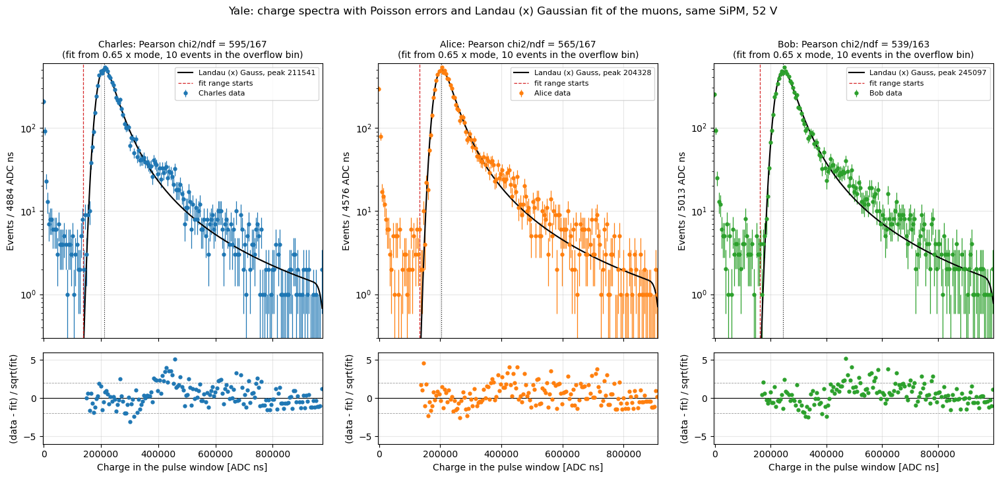

In [84]:
# === Yale: spettro di carica di ogni scintillatore con incertezze e fit Landau (x) gaussiana dei muoni ===
# Per ogni pannello: istogramma di Q_SEGNALE (somma x dt, ADC ns, finestra lunga) disegnato come
# PUNTI con barre d'errore poissoniane sqrt(N) per bin, e fit del contributo dei MUONI:
#     f(Q) = A * [ Landau(MPV, xi) (x) Gauss(sigma) ](Q)
# Landau = perdita di energia del muone, gaussiana = tutto cio' che la allarga con una risposta
# gaussiana (statistica dei fotoelettroni, posizione lungo la fibra, guadagno). MPV e xi sono i
# parametri della Landau PRIMA della convoluzione; il picco della curva convoluta, quello da
# confrontare, si calcola numericamente.
#
# NON si fittano gli eventi a carica bassa: il piedistallo (eventi senza segnale, Q ~ 0) e gli
# eventi fra il piedistallo e il picco non sono muoni che attraversano lo scintillatore (luce
# parziale, impulsi fuori finestra) e nessuna Landau li descrive. Il fit parte da
# FRAZ_MIN_FIT x la moda dell'istogramma e prende TUTTO quello che sta sopra, coda compresa,
# overflow compreso (gli eventi oltre RANGE_PERC entrano in un bin aggiuntivo col numero di
# eventi atteso dal modello oltre il bordo). I bin sotto soglia restano disegnati, in grigio, e
# la curva li attraversa tratteggiata: e' un'estrapolazione, non un fit. La soglia si sceglie
# guardando dove finisce la componente di muoni; la cella stampa quanto cambia il picco
# spostandola (SCAN_FRAZ_MIN) e conviene che sia stabile.
#
# Fit di verosimiglianza di Poisson sui conteggi per bin (minimizza la devianza
# 2 * somma [mu - n + n ln(n/mu)]): vale anche per i bin con pochi eventi o vuoti, dove il
# chi-quadro con errori sqrt(N) non e' definito o e' distorto. Errori sui parametri dalla
# matrice hessiana della devianza. Bonta' del fit: devianza/ndf e chi-quadro di Pearson/ndf con
# ndf = bin nel fit (overflow compreso) - parametri; nel chi-quadro di Pearson il denominatore e'
# max(mu, 1) per non far esplodere i bin di coda con mu ~ 0. I residui sotto il grafico sono
# (n - mu) / sqrt(mu) (Pearson).
#
# La Landau e' calcolata qui, non con scipy.stats.landau (esiste solo da scipy 1.15):
#     phi(x) = 1/(2 pi i) * integrale di exp(x s + s ln s) ds  lungo Re(s) = c,
# con la regola dei trapezi sulla retta e c vicino al punto di sella. Controllata contro la
# formula 1/pi * integrale exp(-t ln t - x t) sin(pi t) dt (scarto < 1e-9) e contro
# scipy.stats.landau. La densita' standard si calcola una volta su una griglia e poi si
# interpola: il fit ne chiede decine di migliaia di valutazioni.
from scipy.optimize import minimize, minimize_scalar
from scipy.ndimage import gaussian_filter1d

N_BIN_FIT = 200                 # bin dell'istogramma (esclusi underflow e overflow)
RANGE_PERC = (0.1, 99.9)        # l'istogramma copre questi percentili di Q; oltre, underflow e overflow
FRAZ_MIN_FIT = 0.65             # il fit parte da questa frazione della moda dell'istogramma
SCAN_FRAZ_MIN = [0.5, 0.6, 0.65, 0.7, 0.8]   # soglie provate per vedere quanto cambia il picco
LOG_Y_FIT = True
ORDINE_FIT = ["Charles", "Alice", "Bob"]
COLORI_FIT = {"Charles": "tab:blue", "Alice": "tab:orange", "Bob": "tab:green"}

_DY = 0.01
_Y = np.arange(0.0, 30.0, _DY)
_W = np.full_like(_Y, _DY); _W[0] = _DY / 2


def landau_std(x):
    """Densita' di Landau standard phi(x) (integrale 1, moda a -0.2228)."""
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.zeros_like(x)
    mid = (x > -6.0) & (x <= 100.0)
    xv = x[mid]
    c = np.clip(np.exp(-1.0 - xv), 0.05, 6.0)[:, None]
    s = c + 1j * _Y[None, :]
    out[mid] = np.maximum(((np.exp(xv[:, None] * s + s * np.log(s)).real) * _W[None, :]).sum(axis=1) / np.pi, 0.0)
    big = x > 100.0
    u = 1.0 / (x[big] - x[big] * np.log(x[big]) / (x[big] + 1.0))
    out[big] = u * u * (1.0 + (-1.845568670 - 4.284640743 * u) * u)
    return out


_LAMBDA0 = float(minimize_scalar(lambda v: -landau_std(v)[0], bounds=(-1.0, 1.0), method="bounded",
                                 options={"xatol": 1e-8}).x)      # moda della densita' standard (~ -0.2228)
_LGRID = np.arange(-6.0, 100.0, 0.01)
_LPHI = landau_std(_LGRID)                                         # una volta sola
_PHI_ALTO = lambda l: landau_std(l)                                # sopra 100 e' l'asintotica


def landau_interp(lam):
    lam = np.asarray(lam, dtype=float)
    out = np.interp(lam, _LGRID, _LPHI, left=0.0)
    alto = lam > _LGRID[-1]
    if alto.any():
        out[alto] = _PHI_ALTO(lam[alto])
    return out


def modello_bin(par, ctx):
    """Conteggi attesi dei muoni: [underflow, bin..., overflow]. par in unita' della moda: A, mpv, xi, sg."""
    A, mpv, xi, sg = par
    q = ctx["q_fine"]
    dens = landau_interp((q - mpv) / xi + _LAMBDA0) / xi
    h = ctx["h"]
    nk = int(np.ceil(6 * sg / h))                           # sg >= 0.01 (bound), h < 0.003
    k = np.arange(-nk, nk + 1) * h
    ker = np.exp(-0.5 * (k / sg) ** 2); ker /= ker.sum()
    conv = np.convolve(dens, ker, mode="same")
    lg = conv[ctx["i0"]:ctx["i1"]].reshape(ctx["nbin"], ctx["r"]).sum(axis=1) * h
    lg_sotto = conv[:ctx["i0"]].sum() * h                   # massa sotto il bordo basso dell'istogramma
    lg_sopra = max(1.0 - lg_sotto - lg.sum(), 0.0)          # il resto della densita' normalizzata e' sopra il bordo alto
    return A * np.concatenate([[lg_sotto], lg, [lg_sopra]])


def devianza(par, n, ctx, usati=None):
    """Devianza di Poisson sui soli bin `usati` (maschera su underflow, bin, overflow)."""
    mu = np.maximum(modello_bin(par, ctx), 1e-12)
    termine = np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / mu), 0.0)
    d = 2.0 * (mu - n + termine)
    return float(np.sum(d if usati is None else d[usati]))


def hessiana(f, x, passi):
    """Hessiana per differenze finite centrali."""
    n = len(x); H = np.zeros((n, n)); f0 = f(x); E = np.eye(n)
    for i in range(n):
        H[i, i] = (f(x + E[i] * passi[i]) - 2 * f0 + f(x - E[i] * passi[i])) / passi[i] ** 2
        for j in range(i + 1, n):
            H[i, j] = H[j, i] = (f(x + E[i] * passi[i] + E[j] * passi[j]) - f(x + E[i] * passi[i] - E[j] * passi[j])
                                 - f(x - E[i] * passi[i] + E[j] * passi[j]) + f(x - E[i] * passi[i] - E[j] * passi[j])) \
                                / (4 * passi[i] * passi[j])
    return H


_ch_di = {nome: ch for ch, nome in RIVELATORI.items()}
_pannelli = [n for n in ORDINE_FIT if n in _ch_di]


def fit_muoni(n, ctx, usati, N):
    """Fit di Landau (x) gaussiana sui bin `usati`. Ritorna (parametri fisici, errori, successo)."""
    # Parametri tutti di ordine 1 (l'ampiezza in frazione di N): con A ~ 1e4 contro 1 degli altri
    # il gradiente numerico non la muoverebbe.
    scala_par = np.array([N, 1, 1, 1], dtype=float)
    x0 = np.array([0.95, 1.0, 0.07, 0.05])
    lim = [(0, 2), (0.5, 1.5), (0.005, 0.5), (0.01, 0.5)]
    f_int = lambda xi: devianza(xi * scala_par, n, ctx, usati)
    ris = minimize(f_int, x0, method="L-BFGS-B", bounds=lim)
    for _ in range(3):                                         # altri giri dal minimo trovato
        ris = minimize(f_int, ris.x, method="L-BFGS-B", bounds=lim)
    ris_nm = minimize(f_int, ris.x, method="Nelder-Mead", options=dict(xatol=1e-7, fatol=1e-6, maxiter=4000))
    if ris_nm.fun < ris.fun:
        ris = ris_nm
    try:
        passi = np.maximum(1e-3 * np.abs(ris.x), 1e-3)
        cov_int = 2.0 * np.linalg.inv(hessiana(f_int, np.asarray(ris.x), passi))
        e_p = np.sqrt(np.where(np.diag(cov_int) > 0, np.diag(cov_int), np.nan)) * scala_par
    except np.linalg.LinAlgError:
        e_p = np.full(4, np.nan)
    return np.asarray(ris.x) * scala_par, e_p, ris


def curva_conv(p, ctx):
    """Landau (x) gaussiana sulla griglia fine (densita' per unita' scalata, integrale 1)."""
    dens = landau_interp((ctx["q_fine"] - p[1]) / p[2] + _LAMBDA0) / p[2]
    nk = int(np.ceil(6 * p[3] / ctx["h"])); kk = np.arange(-nk, nk + 1) * ctx["h"]
    ker = np.exp(-0.5 * (kk / p[3]) ** 2); ker /= ker.sum()
    return np.convolve(dens, ker, mode="same")


FIT_LG = {}
fig = plt.figure(figsize=(6.2 * len(_pannelli), 7.5))
gs = fig.add_gridspec(2, len(_pannelli), height_ratios=[3, 1], hspace=0.08)
print(f"Fit Landau (x) gaussiana dei muoni, Q >= {FRAZ_MIN_FIT:g} x moda dell'istogramma fino a fine spettro "
      f"(overflow compreso), verosimiglianza di Poisson")
for j, nome in enumerate(_pannelli):
    q = Q_SEGNALE[_ch_di[nome]]
    N = len(q)
    lo, hi = (float(v) for v in np.percentile(q, RANGE_PERC))
    n_reg, bordi = np.histogram(q, bins=np.linspace(lo, hi, N_BIN_FIT + 1))
    n_sotto, n_sopra = int((q < lo).sum()), int((q > hi).sum())
    n = np.concatenate([[n_sotto], n_reg, [n_sopra]]).astype(float)   # underflow, bin, overflow
    bw = bordi[1] - bordi[0]
    c = 0.5 * (bordi[1:] + bordi[:-1])
    sel_moda = c > 0.25 * np.median(q)
    moda_h = c[sel_moda][int(np.argmax(gaussian_filter1d(n_reg.astype(float), 1)[sel_moda]))]
    sc = moda_h                                          # unita' interne: la moda dell'istogramma
    r = 6
    h = bw / r
    n_ext = int(np.ceil(0.5 * moda_h / h))
    n_tot = n_ext + N_BIN_FIT * r
    ctx = dict(h=h / sc, r=r, nbin=N_BIN_FIT, i0=n_ext, i1=n_ext + N_BIN_FIT * r,
               q_fine=((lo - n_ext * h) + (np.arange(n_tot) + 0.5) * h) / sc, bordi=bordi / sc)

    def maschera(frazione):
        """Bin nel fit: quelli col bordo basso sopra frazione*moda, piu' l'overflow. L'underflow no."""
        m = np.zeros(len(n), dtype=bool)
        m[1:-1] = bordi[:-1] >= frazione * moda_h
        m[-1] = True
        return m

    usati = maschera(FRAZ_MIN_FIT)
    p, e_p, ris = fit_muoni(n, ctx, usati, N)
    mu = modello_bin(p, ctx)
    dev = devianza(p, n, ctx, usati)
    pearson = float(np.sum(((n - mu) ** 2 / np.maximum(mu, 1.0))[usati]))
    ndf = int(usati.sum()) - len(p)
    conv = curva_conv(p, ctx)
    picco = float(ctx["q_fine"][np.argmax(conv)] * sc)
    sopra_meta = ctx["q_fine"][conv >= conv.max() / 2] * sc
    fwhm = float(sopra_meta[-1] - sopra_meta[0])
    n_fit = int(n[usati].sum())
    FIT_LG[nome] = dict(parametri=p, errori=e_p, devianza=dev, pearson=pearson, ndf=ndf, picco=picco, fwhm=fwhm,
                        e_picco=float(e_p[1] * sc),      # errore dell'MPV, usato come errore del picco
                        sc=sc,
                        soglia_fit=FRAZ_MIN_FIT * moda_h, n_eventi_fit=n_fit)
    s_err = lambda k: f"{p[k] * sc:.0f} +- " + (f"{e_p[k] * sc:.0f}" if np.isfinite(e_p[k]) else "n.d.")
    print(f"  {nome:8s}: picco {picco:9.0f} ADC ns (moda istogramma {moda_h:.0f}), FWHM/picco {fwhm / picco:.2f}; "
          f"MPV {s_err(1)}, xi {s_err(2)}, sigma gauss {s_err(3)}\n"
          f"{'':10s}  fit sopra Q = {FRAZ_MIN_FIT * moda_h:.0f}: {n_fit} eventi su {N} ({n_sopra} nell'overflow, oltre {hi:.0f}); "
          f"devianza/ndf = {dev:.0f}/{ndf} = {dev / ndf:.2f}, Pearson chi2/ndf = {pearson:.0f}/{ndf} = {pearson / ndf:.2f}; "
          f"eventi di muoni stimati sull'intero spettro: {p[0]:.0f}")

    # stabilita' del picco rispetto alla soglia del fit
    riga = []
    for fr in SCAN_FRAZ_MIN:
        m_ = maschera(fr)
        p_, _, _ = fit_muoni(n, ctx, m_, N)
        cv = curva_conv(p_, ctx)
        riga.append(f"{fr:g}: {ctx['q_fine'][np.argmax(cv)] * sc:.0f}")
    print(f"{'':10s}  picco con soglia a  " + ",  ".join(riga) + "  (frazione della moda: picco)")

    ax = fig.add_subplot(gs[0, j])
    err = np.sqrt(np.maximum(n_reg, 1))
    nel = usati[1:-1]
    # Tutti i punti dello stesso colore, fittati o no: si vede dalla linea rossa dove parte il fit
    ax.errorbar(c, n_reg, yerr=err, fmt="o", ms=3.5, color=COLORI_FIT[nome], lw=0.9, label=f"{nome} data")
    qf = ctx["q_fine"] * sc
    curva = p[0] * conv / sc * bw                          # eventi per bin
    dentro = qf >= FRAZ_MIN_FIT * moda_h
    ax.plot(qf[dentro], curva[dentro], "k-", lw=1.5, label=f"Landau (x) Gauss, peak {picco:.0f}")
    ax.plot(qf[~dentro], curva[~dentro], "k--", lw=0.9, alpha=0.6)    # la curva a sinistra della soglia, dove non c'e' fit
    ax.axvline(picco, color="k", ls=":", lw=0.8)
    ax.axvline(FRAZ_MIN_FIT * moda_h, color="tab:red", ls="--", lw=0.9, label="fit range starts")
    ax.set_xlim(lo, hi)
    ax.set_ylim(top=1.12 * n_reg.max())
    if LOG_Y_FIT:
        ax.set_yscale("log"); ax.set_ylim(bottom=0.3)
    ax.set_ylabel(f"Events / {bw:.0f} ADC ns")
    ax.set_title(f"{nome}: Pearson chi2/ndf = {pearson:.0f}/{ndf}\n(fit from {FRAZ_MIN_FIT:g} x mode, {n_sopra} events in the overflow bin)", fontsize=10)
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8); ax.tick_params(labelbottom=False)

    axr = fig.add_subplot(gs[1, j], sharex=ax)
    pull = (n_reg - mu[1:-1]) / np.sqrt(np.maximum(mu[1:-1], 1.0))
    axr.axhline(0, color="k", lw=0.8)
    for y in (-2, 2):
        axr.axhline(y, color="0.6", ls="--", lw=0.6)
    axr.plot(c[nel], pull[nel], "o", ms=3.5, color=COLORI_FIT[nome])     # solo i bin fittati
    axr.set_ylim(-6, 6)
    axr.set_xlabel("Charge in the pulse window [ADC ns]"); axr.set_ylabel("(data - fit) / sqrt(fit)")
    axr.grid(True, alpha=0.3)
fig.suptitle(f"Yale: charge spectra with Poisson errors and Landau (x) Gaussian fit of the muons, same SiPM, {VBIAS:g} V", y=0.995)
plt.tight_layout(); plt.show()


DELTA_E = 8.87 MeV (calcolata: 5 cm, muone da 4 GeV)
SiPM_001: Qpe_tot(52 V) = 437.2 +- 16.0 ADC ns; crosstalk del LED a 52 V: lambda = 0.000 +- 0.030
ATTENZIONE: Qpe_tot e' quello misurato a LNF a 52 V nominali; la sovratensione efficace a Yale non e' nota (moduli HV diversi) e il guadagno cambia molto con essa: il LY di Yale ne eredita l'incertezza.

 pannello   picco [ADC ns]   N pe misurati     Pct     N pe reali    LY [pe/MeV]
  Charles           211541     483.9 +- 17.7   0.000    483.9 +- 22.9     54.6 +-  2.6
    Alice           204328     467.4 +- 17.1   0.000    467.4 +- 22.1     52.7 +-  2.5
      Bob           245097     560.7 +- 20.5   0.000    560.7 +- 26.5     63.2 +-  3.0
(errori: picco = errore dell'MPV del fit, Qpe_tot dal fit lineare, Pct dal JSON; NON inclusi: l'errore su DELTA_E e quello sulla sovratensione di Yale)


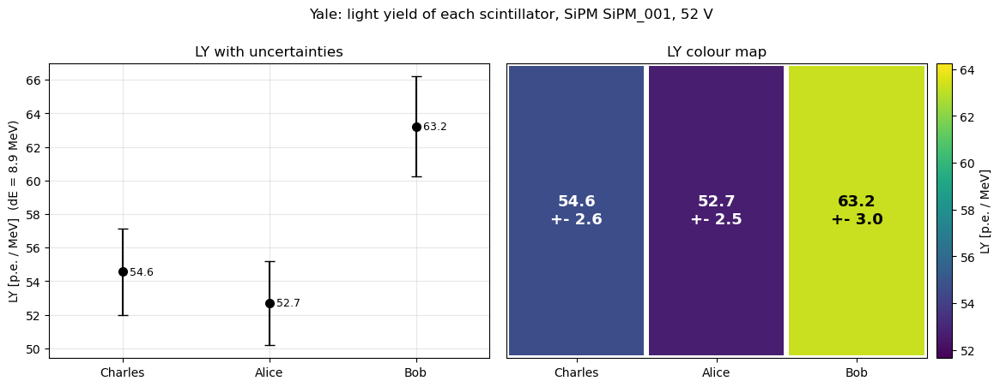

In [86]:
# === Yale: light yield di ogni scintillatore ===
# Per ogni pannello, a partire dal picco della Landau (x) gaussiana della cella precedente:
#   N_pe misurati = picco / Qpe_tot                 fotoelettroni (celle accese) al picco
#   N_pe reali    = N_pe misurati / (1 - Pct)       con Pct = probabilita' di crosstalk (CT_DIVIDI = True)
#   LY            = N_pe reali / DELTA_E            fotoelettroni per MeV depositato al picco
# - Qpe_tot: carica per fotoelettrone sull'intero impulso del SiPM usato, misurata col LED
#   (notebook del guadagno), valutata dalla cella dell'equalizzazione (fit lineare in V, a V_EQ) e
#   moltiplicata per dt in ADC ns: e' nella stessa unita' del picco. Si legge dal JSON
#   mv_panels_equalizzazione_sipm.json scritto da quella cella, quindi va eseguita almeno una volta.
# - SiPM: a Yale lo STESSO SiPM e' stato usato su tutti e tre gli scintillatori, ed e' quello che
#   nei dati nuovi sta su Bob (indicato dall'utente il 2026-10-19), cioe' SiPM_001 secondo la mappa
#   SiPM -> pannello. Si cambia con SIPM_YALE.
# - Pct: crosstalk `lambda` del JSON del LED a 52 V (il punto singolo di per_run, non un fit).
#   Per SiPM_001 e SiPM_002 a 52 V il JSON da' 0.000 (segnato non affidabile quando e' cosi'):
#   con una sovratensione di 0.6 V il crosstalk e' piccolo e il fit non lo separa. Si puo'
#   imporre un valore con PCT_OVERRIDE.
#   ATTENZIONE alla direzione della correzione: se il segnale misurato conta anche le celle del
#   crosstalk, i fotoelettroni primari sono MENO di quelli misurati, e il notebook del guadagno
#   scrive primari ~ misurati x (1 - lambda). Qui, come richiesto, si divide per (1 - Pct), che
#   li fa salire; con CT_DIVIDI = False si moltiplica. La differenza e' ~2 Pct: 7% con 0.034.
# - DELTA_E: energia attesa al picco, perdita di energia piu' probabile di un muone minimo in
#   SPESSORE_CM di scintillatore plastico (Landau-Vavilov, PDG):
#     MPV = xi * [ln(2 m_e c2 b2g2 / I) + ln(xi / I) + 0.200 - b2 - delta],  xi = (K/2)(Z/A) rho x / b2
#   con delta di densita' al limite asintotico. EJ-200 (polivinil-toluene): rho = 1.023 g/cm3,
#   Z/A = 0.541, I = 64.7 eV (valori del datasheet/PDG, non misurati qui). Per muoni sopra
#   1 GeV il risultato non dipende dall'energia (8.86-8.97 MeV da 1 a 100 GeV). Si impone un
#   valore con DELTA_E_MEV. Vale per un muone verticale: un muone inclinato attraversa
#   x / cos(theta) e depone di piu', quindi a LNF, dove i pannelli sono uno sopra l'altro e
#   l'accettanza angolare e' larga, il picco corrisponde a una ΔE un po' maggiore.
import json

SIPM_YALE = "SiPM_001"
CT_DIVIDI = True                # True: N reali = N misurati / (1 - Pct); False: x (1 - Pct)
PCT_OVERRIDE = None             # es. {"Charles": 0.03}: crosstalk per pannello al posto di quello del JSON
SPESSORE_CM, RHO_G_CM3, Z_SU_A, I_EV, E_MU_GEV = 5.0, 1.023, 0.5408, 64.7, 4.0
DELTA_E_MEV = None              # None = calcolata qui


def mpv_perdita_energia(x_cm, rho, z_su_a, i_ev, e_mu_gev):
    """Perdita di energia piu' probabile [MeV] di un muone in x_cm di materiale (Landau-Vavilov, PDG)."""
    K, ME_EV, M_MU_MEV = 0.307075, 0.511e6, 105.658     # MeV cm2/mol, eV, MeV
    gam = e_mu_gev * 1000.0 / M_MU_MEV
    bg2 = gam ** 2 - 1.0
    b2 = bg2 / gam ** 2
    xi = 0.5 * K * z_su_a * rho * x_cm / b2             # MeV
    hw_p = 28.816 * np.sqrt(rho * z_su_a)               # energia di plasma [eV]
    delta = np.log(bg2) + 2.0 * np.log(hw_p / i_ev) - 1.0          # limite asintotico, 2 ln(bg) = ln(bg2)
    return xi * (np.log(2 * ME_EV * bg2 / i_ev) + np.log(xi * 1e6 / i_ev) + 0.200 - b2 - delta)


delta_e = DELTA_E_MEV if DELTA_E_MEV is not None else mpv_perdita_energia(SPESSORE_CM, RHO_G_CM3, Z_SU_A, I_EV, E_MU_GEV)
print(f"DELTA_E = {delta_e:.2f} MeV ({'imposta' if DELTA_E_MEV is not None else f'calcolata: {SPESSORE_CM:g} cm, muone da {E_MU_GEV:g} GeV'})")

nome_eq_ly = os.path.join(DIR_MISURE, "mv_panels_equalizzazione_sipm.json")
if not os.path.exists(nome_eq_ly):
    raise FileNotFoundError("manca mv_panels_equalizzazione_sipm.json: eseguire una volta la cella dell'equalizzazione dei SiPM")
with open(nome_eq_ly) as f_:
    eq_ly = json.load(f_)
qpe_tot = eq_ly["sipm"][SIPM_YALE]["q_pe_tot_adc_ns"]
e_qpe_tot = eq_ly["sipm"][SIPM_YALE]["e_q_pe_tot_adc_ns"]
with open(os.path.join(DIR_MISURE, f"sipm_gain_led_{SIPM_YALE}_{DATA_GAIN}.json")) as f_:
    pr_ly = json.load(f_)["per_run"][str(int(eq_ly["tensione_V"]))]
pct_json, e_pct_json = pr_ly["lambda"], pr_ly["e_lambda"]
print(f"{SIPM_YALE}: Qpe_tot({eq_ly['tensione_V']:g} V) = {qpe_tot:.1f} +- {e_qpe_tot:.1f} ADC ns; crosstalk del LED a "
      f"{eq_ly['tensione_V']:g} V: lambda = {pct_json:.3f} +- {e_pct_json:.3f}"
      + ("" if pr_ly.get("affidabile", True) else " (punto segnato non affidabile)"))
if abs(eq_ly["tensione_V"] - VBIAS) > 1e-6:
    print(f"ATTENZIONE: Qpe_tot e crosstalk valgono a {eq_ly['tensione_V']:g} V, i dati Yale sono a {VBIAS:g} V")
print("ATTENZIONE: Qpe_tot e' quello misurato a LNF a 52 V nominali; la sovratensione efficace a Yale non e' nota "
      "(moduli HV diversi) e il guadagno cambia molto con essa: il LY di Yale ne eredita l'incertezza.")

LY = {}
print(f"\n{'pannello':>9} {'picco [ADC ns]':>16} {'N pe misurati':>15} {'Pct':>7} {'N pe reali':>14} {'LY [pe/MeV]':>14}")
for nome in [n for n in ["Charles", "Alice", "Bob"] if n in FIT_LG]:
    picco, e_picco = FIT_LG[nome]["picco"], FIT_LG[nome]["e_picco"]
    pct = PCT_OVERRIDE[nome] if PCT_OVERRIDE and nome in PCT_OVERRIDE else pct_json
    e_pct = 0.0 if PCT_OVERRIDE and nome in PCT_OVERRIDE else e_pct_json
    n_mis = picco / qpe_tot
    e_n_mis = n_mis * np.hypot(e_picco / picco, e_qpe_tot / qpe_tot)
    if CT_DIVIDI:
        n_reali = n_mis / (1.0 - pct)
        e_n_reali = n_reali * np.hypot(e_n_mis / n_mis, e_pct / (1.0 - pct))
    else:
        n_reali = n_mis * (1.0 - pct)
        e_n_reali = n_reali * np.hypot(e_n_mis / n_mis, e_pct / (1.0 - pct))
    ly = n_reali / delta_e
    e_ly = e_n_reali / delta_e                   # senza l'errore su DELTA_E (sistematico, non stimato)
    LY[nome] = dict(picco=picco, n_pe_misurati=n_mis, e_n_pe_misurati=e_n_mis, pct=pct, n_pe_reali=n_reali,
                    e_n_pe_reali=e_n_reali, delta_e_mev=delta_e, ly_pe_per_mev=ly, e_ly=e_ly)
    print(f"{nome:>9} {picco:>16.0f} {n_mis:>9.1f} +- {e_n_mis:4.1f} {pct:>7.3f} {n_reali:>8.1f} +- {e_n_reali:4.1f} "
          f"{ly:>8.1f} +- {e_ly:4.1f}")
print("(errori: picco = errore dell'MPV del fit, Qpe_tot dal fit lineare, Pct dal JSON; "
      "NON inclusi: l'errore su DELTA_E e quello sulla sovratensione di Yale)")

# Due grafici affiancati: a sinistra LY con incertezze, a destra gli stessi valori come mappa di colore
# (un riquadro per scintillatore, nello stesso ordine; il colore e' il LY, scritto nel riquadro).
CMAP_LY = "viridis"
LY_RANGE = None                 # (min, max) della scala di colore; None = dai dati, con un po' di margine
nomi = list(LY)
valori = np.array([LY[n]["ly_pe_per_mev"] for n in nomi])
errori = np.array([LY[n]["e_ly"] for n in nomi])

fig, (ax, axm) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax.errorbar(range(len(nomi)), valori, yerr=errori, fmt="o", ms=7, capsize=4, color="k")
for k, v in enumerate(valori):
    ax.text(k, v, f"  {v:.1f}", va="center", ha="left", fontsize=9)
ax.set_xticks(range(len(nomi))); ax.set_xticklabels(nomi)
ax.set_xlim(-0.5, len(nomi) - 0.5)
ax.set_ylabel(f"LY [p.e. / MeV]  (dE = {delta_e:.1f} MeV)")
ax.set_title("LY with uncertainties")
ax.grid(True, alpha=0.3)

vmin, vmax = LY_RANGE if LY_RANGE is not None else (valori.min() - 0.1 * np.ptp(valori) - 1e-9, valori.max() + 0.1 * np.ptp(valori) + 1e-9)
im = axm.pcolormesh(np.arange(len(nomi) + 1), [0, 1], valori[None, :], cmap=CMAP_LY, vmin=vmin, vmax=vmax,
                    edgecolors="w", linewidth=3)
for k, (v, e) in enumerate(zip(valori, errori)):
    # testo chiaro sui colori scuri e scuro sui chiari
    chiaro = plt.get_cmap(CMAP_LY)((v - vmin) / (vmax - vmin))[:3]
    col = "k" if (0.299 * chiaro[0] + 0.587 * chiaro[1] + 0.114 * chiaro[2]) > 0.5 else "w"
    axm.text(k + 0.5, 0.5, f"{v:.1f}\n+- {e:.1f}", ha="center", va="center", fontsize=13, color=col, fontweight="bold")
axm.set_xticks(np.arange(len(nomi)) + 0.5); axm.set_xticklabels(nomi)
axm.set_yticks([])
axm.set_title("LY colour map")
cb = fig.colorbar(im, ax=axm, pad=0.02)
cb.set_label("LY [p.e. / MeV]")
fig.suptitle(f"Yale: light yield of each scintillator, SiPM {SIPM_YALE}, {VBIAS:g} V", y=0.995)
plt.tight_layout(); plt.show()


In [ ]:
# === Confronto: efficienze LNF (un run per pannello, trigger = coincidenza degli altri due) contro Yale ===
# LNF: i JSON scritti dalla cella di salvataggio, uno per pannello. Si prende la
# riga dello scan con N = NSIGMA_SOGLIA (versione (a): stessa soglia su tutti i
# canali), quindi lo scan deve contenere NSIGMA_SOGLIA. I pannelli senza JSON
# (adesso Bob) non compaiono nel grafico.
# Yale: frazione degli eventi del file sopra soglia (cella precedente).
import json

if NSIGMA_YALE != NSIGMA_SOGLIA:
    print(f"ATTENZIONE: soglia LNF mu + {NSIGMA_SOGLIA} sigma, soglia Yale mu + {NSIGMA_YALE} sigma: "
          f"le due efficienze non sono alla stessa soglia")

PANNELLI_ORDINE = ["Charles", "Alice", "Bob"]     # dall'alto in basso
lnf = {}
for nome in PANNELLI_ORDINE:
    pj = os.path.join(DIR_MISURE, f"mv_panels_eff_{nome}.json")
    if not os.path.exists(pj):
        print(f"{nome}: nessun risultato LNF ({os.path.relpath(pj, os.path.abspath('..'))}); "
              f"si ottiene eseguendo il notebook con PANNELLO = {nome!r}")
        continue
    with open(pj) as fj:
        d = json.load(fj)
    riga = [r for r in d["scan_soglia"] if r["n_sigma"] == NSIGMA_SOGLIA]
    if not riga:
        print(f"{nome}: lo scan salvato non contiene N = {NSIGMA_SOGLIA} (ha {[r['n_sigma'] for r in d['scan_soglia']]}): saltato")
        continue
    lnf[nome] = dict(d, riga=riga[0]["a"])

print(f"{'pannello':>9} {'ch':>3} | {'eff LNF':>20} {'N rif.':>8} {'eventi':>8} | {'eff Yale':>20} {'N':>7} | "
      f"{'sigma LNF':>9} {'sigma Yale':>10} [ADC]")
ris = {}
for nome in PANNELLI_ORDINE:
    if nome not in lnf:
        continue
    d = lnf[nome]; ch = d["canale"]; r = d["riga"]
    e_y, err_y, _, _ = EFF_YALE[ch]
    ris[nome] = (r["eff"], r["err"], e_y, err_y, ch)
    print(f"{nome:>9} {ch:>3} | {r['eff']:>13.4f} +- {r['err']:.4f} {r['n_rif']:>8} {d['n_eventi']:>8} | "
          f"{e_y:>13.4f} +- {err_y:.4f} {len(sopra_yale[ch]):>7} | "
          f"{d['fit_ampiezze'][str(ch)]['sigma']:>9.3f} {FIT_AMP_YALE[ch][2]:>10.3f}")

if ris:
    fig, ax = plt.subplots(figsize=(7, 4.2))
    x = np.arange(len(ris))
    ax.errorbar(x - 0.08, [100 * r[0] for r in ris.values()], yerr=[100 * r[1] for r in ris.values()],
                fmt="o", capsize=4, label=f"LNF ({VBIAS:g} V, CFD coincidence of the other two)")
    ax.errorbar(x + 0.08, [100 * r[2] for r in ris.values()], yerr=[100 * r[3] for r in ris.values()],
                fmt="s", capsize=4, label="Yale (external trigger)")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{n}\n(ch{r[4]})" for n, r in ris.items()])
    ax.set_xlim(-0.6, len(ris) - 0.4)
    ax.set_ylabel(f"Efficiency [%] (threshold mu + {NSIGMA_SOGLIA} sigma)" if NSIGMA_YALE == NSIGMA_SOGLIA
                  else f"Efficiency [%] (LNF mu + {NSIGMA_SOGLIA} sigma, Yale mu + {NSIGMA_YALE} sigma)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()